# Phase 6A - Supervised models: how much does what we know early say about what happens to a new song?

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis (Atlantic Recording Corporation case)

**What this notebook does.** Phases 4 and 5 described the chart as it was and tested ten claims about it. This notebook asks a different kind of question. Take the 894 songs that arrived on the chart after its first snapshot day (by 229 artists; the 50 songs that were already there on day one are left out, because we did not see them arrive). For each song, how much of what happened next could have been told from what was known at the time? There are seven questions: three with a class as the answer (C1 a Top-10 debut, C2 a later climb into the Top 10, C3 the stay class Flash, Short or Sustained), two with a number as the answer (R1 first-week popularity, R2 days on the chart) and two asked after the song has spent three days on the chart (E1 a later climb, E2 a stay of 15 or more days). Each is answered by a model that sees only what was known at that moment, scored on songs of artists it has never seen.

**How the word "forecast" is used.** The brief for this project is historical analytics, not prediction and not recommendation. A "forecast" in this notebook is a measuring tool, not advice: it is what a model would have said at the time, checked against what really happened. How close the forecasts come tells us how much the early information says about the outcome. No model here is offered as a way to choose songs, and nothing is claimed about what would happen if a song were changed. Section 8 puts a price on acting on the forecasts, but as a measurement of what such a rule would have done on past songs.

**Before you run it.** Phases 1 to 5 must have run, so that `data/processed/` holds the Parquet tables (if not: `python -m src.etl.run_pipeline`). `reports/p4_facts.json` is used for one cross-check if it is there. Then restart the kernel and choose *Run All*. The notebook scores 94 combinations of question, step and model, each of them fifteen times over (five parts, three repeats), and then adds the checks, the importance calculations and the stress tests, so it takes several minutes (about 8 on the two-core computer where it was tested; yours will differ); the long parts are Section 3 (the main run), Section 7 (permutation importance) and Section 9 (stress tests). It writes 17 charts to `reports/figures/p6a_*.png` and six files to `reports/`: `p6a_facts.json` (every number quoted in the text), `p6a_model_register.csv` (every score of every model with its interval), `p6a_oof_predictions.csv` (the forecast for every song), `p6a_explanations.csv`, `p6a_decisions.csv` and `p6a_stress_tests.csv`. Always restart the kernel before running again: the container of numbers refuses to store the same name twice, which is how we know that no number is silently replaced.

**If your numbers differ a little.** The numbers in the sentences of this notebook were written from one run, on scikit-learn 1.9.1. The straight-line models and the regressions do not depend on the version: their numbers came out the same, to nine digits, on scikit-learn 1.4.0, the oldest version this project allows. The boosting and forest models can move a little. On 1.4.0 about one number in seven in the text would be printed differently (60 of 402), the scores by about 0.01 at most and by about 0.001 as a rule, and the numbers that rest on a handful of songs by more: after three days only 31 songs climbed, so a single song is worth about 3 points of a gain. If a cell prints a number that differs a little from the sentence near it, trust the printed number. The story should be the same, and `tests/test_notebook_06a.py` checks the claims that matter, for example that no flexible model is clearly better than the straight-line model for the Top-10 questions.

**How to read it.** Every code cell has a short plain-English explanation above it in five parts: *what this code is*, *why we need it*, *what will happen*, *expected outcome* and *motive*. Every chart has a *What to notice* note below it, and the numbers in those notes are not typed by hand: the code stores each number it computes in `FACTS`, and the sentences are written from it.

**Ground rules used throughout.**

- *No peeking.* Every input of a song is calculated from what was on the chart before the forecast is made. Section 2 proves it by scrambling the future of the chart and checking that no input moves.
- *A ladder of information.* The inputs come in five blocks: release details, timing, the artist's chart record, the debut-day chart and the first three days on the chart. Each step of the ladder includes the steps before it, so what a step adds can be measured, with its own interval.
- *Artists held out.* The songs of one artist are alike (Phase 5), so a model is always scored on songs whose artist it has never seen. Section 3 shows what a lazy random split would have done to the scores.
- *Every score has an interval.* The 95% interval comes from drawing the artists again 1,000 times. The difference between two scores gets its own interval from the same draws.
- *Simple first.* Every question is answered by a straight-line model (logistic or ridge regression), by gradient boosting and, at the last step, by a random forest, and all three are held against a baseline that knows nothing. A complicated model has to beat the straight line to be worth its complication.
- *Explaining is not forecasting.* Section 7 reads the odds ratios, coefficients, importance and curves; they describe associations among these songs and what the models do, not causes.
- *The price of a forecast is a range.* Section 8 does not know what a climb is worth to Atlantic, so it shows a whole range of values and the point at which a rule would just pay back.
- *Small counts.* Only 56 songs climb in C2 and 31 in E1. The intervals say how little that is.

| Section | What it does | Figures |
|---|---|---|
| 1 | Setup and loading | - |
| 2 | The modeling table, the proof that it does not peek, and the seven questions | 1 |
| 3 | The test: artist folds, the main run of all models, two checks of the test itself | 2-3 |
| 4 | C1: can a Top-10 debut be told before the song arrives? | 4-5 |
| 5 | C2, C3, R1 and R2: the questions asked on the debut day | 6-9 |
| 6 | E1 and E2: what three days on the chart add | 10 |
| 7 | What goes with the outcomes: odds ratios, coefficients, importance, curves | 11-14 |
| 8 | Putting a price on the forecasts: gains and break-even | 15-16 |
| 9 | Stress tests: other splits, other settings, without the biggest artist, forward in time | 17 |
| 10 | Saving the results and what Phase 6A adds up to | - |

## Section 1 - Setup and loading

Libraries, our own modeling code, the project look, and the cleaned chart from Phase 3. The last cell of this section refuses to go on if the chart it loads is not the one that Phases 4 and 5 described.

**What this code is.** The import cell. It loads the Python libraries (pandas for tables, numpy for numbers, matplotlib for charts, scikit-learn for the models) and our own modules: `src/ml` (the modeling table, the artist-grouped validation, the models, the scores, the explanations and the chart helpers of Phase 6) together with the Phase 3 to 5 helpers for paths, the chart look, the container of facts, regressions with artist-aware intervals and the saving of tables.

**Why we need it.** Everything below uses these names. The logic that matters (how the folds are made, how a score is calculated, how an interval is drawn) lives in `src/ml` and is covered by automated tests, so the notebook stays short and the formulas stay checked. The two path lines make `from src...` work whether Jupyter was started in the project folder or in the `notebooks` folder.

**What will happen.** Python imports the libraries, switches on the project look and creates `FACTS`, where every number that appears in a sentence is stored once (it refuses to store a name twice and refuses numbers that are not finite). It then sets the settings of the whole notebook: the songs are dealt into 5 parts by artist, this is done 3 times with different deals, and every interval comes from 1,000 draws of artists.

**Expected outcome.** Four printed lines (the versions of pandas, numpy and scikit-learn, and the project folder) and no chart. If a line fails with `ModuleNotFoundError`, run `pip install -r requirements.txt` in the project folder and restart the kernel.

**Motive.** One setup, one look, one place for the numbers. From here to the end no number in a sentence is typed by hand.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))            # makes "from src..." work when the notebook starts inside the notebooks folder

from src.config import default_paths
from src.eda import style
from src.eda.findings import Facts
from src.eda.plots import clean_text, direct_label, hbar, make_fig, panel_title, readable_ink, save_fig, short, style_axes, swatch_legend
from src.inference.dependence import coefficient_test, fit_ols
from src.inference.register import save_table
from src.ml import metrics as M
from src.ml import plots as MP
from src.ml.benchmark import (CLASS_LISTS, HIGHER_IS_BETTER, MAIN_METRIC, METRICS, TASKS, compare, run_benchmark, run_forward,
                              score_rows, score_variant, task_data)
from src.ml.dataset import (ARTIST_FEATURES, DEBUT_FEATURES, EARLY_FEATURES, HORIZON, LOOKBACK, RELEASE_FEATURES, STAY_CLASSES,
                            TIMING_FEATURES, build_modeling_table)
from src.ml.explain import build_design, partial_dependence, permutation_importance
from src.ml.glm import fit_logit
from src.ml.models import LADDER, LADDER_LABELS, MODEL_LABELS, SEED, feature_set, make_classifier, make_regressor
from src.ml.validation import (assert_no_group_overlap, cross_validated_predictions, grouped_folds, random_folds,
                               repeated_grouped_folds)

pd.set_option("display.max_columns", 40)             # show up to 40 columns instead of hiding some
pd.set_option("display.width", 200)                  # use a wide print area so that tables do not wrap
pd.set_option("display.float_format", "{:,.4g}".format)

style.apply_style()                                  # the project look: fonts, colours, hairline grid
FACTS = Facts()                                      # every number we quote in a sentence is stored here, once

N_SPLITS = 5                                         # artist-grouped cross-validation: five parts ...
N_REPEATS = 3                                        # ... made three times with different artist splits
N_BOOT = 1000                                        # artist-level bootstrap draws for every interval
FACTS["n_splits"] = N_SPLITS
FACTS["n_repeats"] = N_REPEATS
FACTS["n_boot"] = N_BOOT

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("project     :", PROJECT_ROOT)

pandas      : 2.3.2
numpy       : 2.3.3
scikit-learn: 1.6.1
project     : d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics


**What this code is.** The loading cell. It reads the four Parquet tables that the pipeline made: the songs, the chart rows (one per song per snapshot day), the credits (which artists are on which song) and the calendar. It stores the headline counts and compares them with Phase 4.

**Why we need it.** A model can only be as right as its data. If the pipeline had been changed since Phase 4, a quiet difference would flow into every score of this notebook. The comparison with `reports/p4_facts.json` is a seat belt: it stops the notebook, with a message that says what to run, if the chart is not the one that Phases 4 and 5 described.

**What will happen.** The code checks that the four files exist, reads them, lists the snapshot days, stores the numbers of rows, songs and snapshot days and the first and last date in `FACTS`, and prints a small table. If `p4_facts.json` is there it compares song-days, songs and snapshot days with Phase 4 and stops on any difference; if the file is not there it says that the comparison is skipped.

**Expected outcome.** A table with 27,750 song-days, 944 songs and 555 snapshot days (from 18 May 2024 to 27 November 2025), followed by the line "Phase 4 reproduced: the same numbers of song-days, songs and snapshot days."

**Motive.** Be sure that Phase 6 models the same chart that Phases 4 and 5 described.

In [2]:
paths = default_paths()
FIG_DIR = paths.reports_dir / "figures"              # all charts of this notebook are saved here as PNG files

needed = ["dim_track", "fact_chart_daily", "bridge_track_artist", "dim_date"]
missing = [name for name in needed if not (paths.processed_dir / f"{name}.parquet").exists()]
assert not missing, f"Run the pipeline first:  python -m src.etl.run_pipeline   (missing: {missing})"

dim_track = pd.read_parquet(paths.processed_dir / "dim_track.parquet")                      # one row per song
fact_chart = pd.read_parquet(paths.processed_dir / "fact_chart_daily.parquet")              # one row per song per snapshot day
bridge = pd.read_parquet(paths.processed_dir / "bridge_track_artist.parquet")               # which artists are credited on which song
dim_date = pd.read_parquet(paths.processed_dir / "dim_date.parquet")                        # one row per calendar day

snapshots = dim_date[dim_date["has_snapshot"]]
FACTS["rows"] = len(fact_chart)
FACTS["songs"] = len(dim_track)
FACTS["snapshots"] = len(snapshots)
FACTS["first_date"], FACTS["last_date"] = f"{snapshots['date'].min():%d %B %Y}", f"{snapshots['date'].max():%d %B %Y}"

display(pd.DataFrame({"table": ["fact_chart_daily (song x day)", "dim_track (songs)", "bridge_track_artist (credits)", "snapshot days"],
                      "rows": [len(fact_chart), len(dim_track), len(bridge), len(snapshots)]}))

# ---- the numbers of Phase 4 must come out again, otherwise this notebook would model a different chart
p4_file = paths.reports_dir / "p4_facts.json"
if p4_file.exists():
    p4 = json.loads(p4_file.read_text(encoding="utf-8"))
    for label, now, before in [("song-days", len(fact_chart), p4["rows"]), ("songs", len(dim_track), p4["songs"]),
                               ("snapshot days", len(snapshots), p4["snapshots"])]:
        assert now == before, f"{label}: {now} here, {before} in Phase 4. Re-run the pipeline and notebook 04 first."
    print("Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.")
else:
    print("reports/p4_facts.json is not there (notebook 04 has not been run): the cross-check with Phase 4 is skipped.")

,table,rows
0,fact_chart_daily (song x day),27750
1,dim_track (songs),944
2,bridge_track_artist (credits),1105
3,snapshot days,555


Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.


## Section 2 - The modeling table, the proof that it does not peek, and the seven questions

A model learns from a table with one row per song. This section builds that table, proves that none of its inputs uses information from after the forecast, and lists the seven questions the models will be asked, with the songs each one covers. Figure 1 shows what the outcomes look like, because how hard a question is depends on how rare and how spread out its answer is.

**What this code is.** The cell that builds the modeling table with `build_modeling_table`: one row per song that arrived after the first snapshot day. Each row holds the song's inputs, in five blocks, and the outcomes that followed. The cell then shows, for one example song, what the model sees at each step of the ladder and what happened to the song afterwards.

**Why we need it.** This is the most important step of the notebook. A model is honest only if every input is something that was known on the day of the forecast. Here every input is calculated from data that is strictly older than the song's arrival: the artist's record, for example, counts the artist's chart days before the arrival, never after it. The outcomes are calculated separately from what happened next, and they are the answer sheet: they are never given to a model as an input. The 50 songs that were already on the chart on the first day are left out, because their arrival was not seen.

**What will happen.** 894 songs by 229 artists remain (arrivals from 19 May 2024 to 27 November 2025). The inputs are counted by block: 5 release details, 8 for timing (the weekday of the first appearance as seven yes-or-no columns, and how much chart history exists before the arrival), 7 for the artist's record, 2 for the debut day (the place and the popularity on the first day) and 5 for the first three days, 27 in all at the last step. Outcomes look at the first 30 snapshot days on the chart, and the artist's recent record at the 90 snapshot days before arrival. One example song is drawn with a fixed seed from the songs for which every outcome exists: songs that spent their first three days outside the Top 10, were followed for the full 30 days, and whose artist had at least two earlier songs on the chart.

**Expected outcome.** Two lines of text, then the name of the example song, a table with its inputs grouped by step and a second small table with what happened to it. Reading the first table from top to bottom is reading the ladder: each step is something more that could be known.

**Motive.** Make the problem concrete before any model appears: this is what we knew, and this is what happened.

In [3]:
TABLE = build_modeling_table(dim_track, fact_chart, bridge, dim_date)        # one row per song that ARRIVED after the first snapshot day

FACTS["entrants"] = len(TABLE)
FACTS["day_one_songs"] = len(dim_track) - len(TABLE)                         # already on the chart on day one: their arrival was not seen
FACTS["entrant_artists"] = TABLE["primary_artist"].nunique()
FACTS["first_entry"] = f"{TABLE['entry_date'].min():%d %B %Y}"
FACTS["last_entry"] = f"{TABLE['entry_date'].max():%d %B %Y}"
FACTS["horizon_days"] = HORIZON                                              # outcomes look at the first 30 snapshot days on the chart
FACTS["lookback_days"] = LOOKBACK                                            # an artist's recent record = the 90 snapshot days before arrival
for block, columns in [("release", RELEASE_FEATURES), ("timing", TIMING_FEATURES), ("artist", ARTIST_FEATURES),
                       ("debut", DEBUT_FEATURES), ("early", EARLY_FEATURES)]:
    FACTS[f"inputs_{block}"] = len(columns)
FACTS["inputs_all"] = len(feature_set("early"))

print(f"{len(TABLE)} songs arrived after the first snapshot day ({FACTS['first_entry']} to {FACTS['last_entry']}), by {FACTS['entrant_artists']} artists.")
print(f"{FACTS['day_one_songs']} songs were already on the chart on day one and are left out: we did not see them arrive.")

# ---- what the model sees for one song, step by step down the ladder (a song with a record and three days of chart life)
example = TABLE[TABLE["ok_early"] & (TABLE["artist_prior_songs"] >= 2) & TABLE["ok_climb"]].sample(1, random_state=SEED).iloc[0]
rows = []
for step in LADDER:
    block = {"release": RELEASE_FEATURES, "timing": TIMING_FEATURES, "artist": ARTIST_FEATURES, "debut": DEBUT_FEATURES, "early": EARLY_FEATURES}[step]
    for column in block:
        if step == "timing" and column.startswith("weekday_") and example[column] == 0:
            continue                                                         # of the seven weekday columns only the one that is 1 is worth showing
        rows.append({"step": LADDER_LABELS[step], "input": column, "value": example[column]})
print(f"\nSong: {example['track_label']}  (arrived {example['entry_date']:%d %B %Y})")
display(pd.DataFrame(rows).set_index(["step", "input"]))
print("What happened later (the outcomes the models try to forecast):")
display(example[["y_debut_top10", "y_climb_top10", "chart_days_30", "stay_class", "pop_first_week", "y_climb_after3", "y_sustained_after3"]].to_frame("value"))

894 songs arrived after the first snapshot day (19 May 2024 to 27 November 2025), by 229 artists.
50 songs were already on the chart on day one and are left out: we did not see them arrive.

Song: Boys Of Faith (feat. Bon Iver) by Zach Bryan & Bon Iver  (arrived 24 September 2024)


value
step               input                          
Release details    duration_min              2.847
                   total_tracks                  1
                   is_single                     1
                   is_explicit                   1
                   is_collab                     1
+ Timing           weekday_tue                   1
                   history_days                 90
+ Artist's record  artist_prior_slot_days      402
                   artist_slot_days_recent     363
                   artist_prior_songs           20
                   artist_prior_top10_days      69
                   artist_prior_best_rank        1
                   artist_prior_mean_pop     82.73
                   artist_on_chart_prev_day      1
+ Debut-day chart  entry_rank                   13
                   entry_pop                    54
+ First three days pos_day2                     13
                   move_first_3d                 0
                   best_rank_first_3d           13
                   pop_day3                     58
                   pop_move_first_3d             4

What happened later (the outcomes the models try to forecast):


,value
y_debut_top10,0
y_climb_top10,0
chart_days_30,8
stay_class,Short (4-14)
pop_first_week,61.43
y_climb_after3,0
y_sustained_after3,0


**What this code is.** A test of the table itself, the *peek test*. Six songs are drawn at random. For each one, the chart is changed so that everything after the song's arrival is replaced by random numbers (for the other songs from the arrival day on; for the song itself from its fourth day on, because its first three days are known at the time of the early forecasts). The whole modeling table is then built again, and the song's inputs and outcomes are compared with what they were before.

**Why we need it.** "No input uses information from the future" is the claim that all later results rest on, and saying it is not proof. If scrambling the future moves an input, that input knew something it should not have known. The test also has to show that it has teeth: scrambling the future must change at least some outcomes, otherwise it would pass even if it could not see anything.

**What will happen.** For each of the six songs the code scrambles the position and the popularity in the rows described above (thousands of rows each time), rebuilds the table, and counts how many inputs and how many outcomes moved. The cell stops with an error if any input moved, or if no outcome moved at all. A song that left the chart within three days has no later life to scramble, so its outcomes cannot move; that is expected.

**Expected outcome.** A table of six songs. The column "inputs that moved" is 0 in every row, and "outcomes that moved" is above 0 for some songs (3 of the 6). The last line says that scrambling the future moved 0 inputs.

**Motive.** Turn "we were careful" into something that can fail, and did not.

In [4]:
INPUTS = RELEASE_FEATURES + TIMING_FEATURES + ARTIST_FEATURES + DEBUT_FEATURES + EARLY_FEATURES
OUTCOMES = ["y_debut_top10", "y_climb_top10", "chart_days_30", "pop_first_week", "y_climb_after3", "y_sustained_after3"]

days = dim_date[dim_date["has_snapshot"]]
snapshot_of = dict(zip(days["date"], days["snapshot_index"].astype(int) - int(days["snapshot_index"].min())))
day_of_row = fact_chart["date"].map(snapshot_of)                             # snapshot number of every chart row

rng = np.random.default_rng(SEED)
base = TABLE.set_index("track_id")
checked = rng.choice(base.index[base["entry_snapshot"].between(40, 500)].to_numpy(), 6, replace=False)

peek_rows = []
for track_id in checked:
    arrival = int(base.loc[track_id, "entry_snapshot"])
    scrambled = fact_chart.copy()
    hit = ((day_of_row >= arrival) & (scrambled["track_id"] != track_id)) | ((scrambled["track_id"] == track_id) & (day_of_row >= arrival + 3))
    scrambled.loc[hit, "position"] = rng.integers(1, 51, int(hit.sum()))
    scrambled.loc[hit, "popularity_clean"] = rng.integers(20, 100, int(hit.sum())).astype(float)
    scrambled["in_top10"] = scrambled["position"] <= 10
    again = build_modeling_table(dim_track, scrambled, bridge, dim_date).set_index("track_id")
    moved_inputs = [c for c in INPUTS if not np.isclose(again.loc[track_id, c], base.loc[track_id, c], equal_nan=True)]
    moved_outcomes = [c for c in OUTCOMES if not np.isclose(again.loc[track_id, c], base.loc[track_id, c], equal_nan=True)]
    peek_rows.append({"song": short(base.loc[track_id, "track_label"], 44), "arrived": f"{base.loc[track_id, 'entry_date']:%d %b %Y}",
                      "rows scrambled": int(hit.sum()), "inputs that moved": len(moved_inputs), "outcomes that moved": len(moved_outcomes)})
peek = pd.DataFrame(peek_rows)
display(peek)

FACTS["peek_songs"] = len(peek)
FACTS["peek_inputs_moved"] = int(peek["inputs that moved"].sum())
FACTS["peek_outcomes_moved_songs"] = int((peek["outcomes that moved"] > 0).sum())
FACTS["peek_rows_min"] = int(peek["rows scrambled"].min())
assert FACTS["peek_inputs_moved"] == 0, "an input of the modeling table depends on information from after the forecast was made"
assert FACTS["peek_outcomes_moved_songs"] > 0, "the check has no teeth: scrambling the future should change at least one outcome"
print(f"Scrambling the future moved {FACTS['peek_inputs_moved']} inputs and changed the outcome of {FACTS['peek_outcomes_moved_songs']} of the {len(peek)} songs.")

,song,arrived,rows scrambled,inputs that moved,outcomes that moved
0,You Should Probably Leave by Chris Stapleton,26 Feb 2025,13548,0,0
1,Mean (Taylor's Version) by Taylor Swift,09 Jul 2024,25147,0,1
2,I Look in People's Windows by Taylor Swift,21 Apr 2025,10947,0,3
3,HUMBLE. by Kendrick Lamar,09 May 2025,10048,0,0
4,New Romantics by Taylor Swift,12 Aug 2024,23449,0,0
5,Good Graces by Sabrina Carpenter,24 Aug 2025,4797,0,1


Scrambling the future moved 0 inputs and changed the outcome of 3 of the 6 songs.


**What this code is.** The list of the seven questions. For each one the code picks the songs that the question covers, counts them, stores the counts, and prints a table: the code of the question, the question in words, the kind of answer (yes or no, three classes, a number), the number of songs, what happened, when the forecast is made and which steps of the ladder it may use.

**Why we need it.** "A model" means nothing until it is clear what it is asked and when. The moment matters: C1 is asked before the song arrives, so only release details, timing and the artist's record exist; C2, C3, R1 and R2 are asked on the debut day; E1 and E2 are asked after three days. Each question also covers a different set of songs: C2 only songs that debuted outside the Top 10 and could be followed for 30 days, E1 and E2 only songs that spent their first three days on the chart without reaching the Top 10. And a yes that happens to 9 songs in 100 is a harder thing to find than one that happens to 25 in 100.

**What will happen.** For every question the eligible songs and the outcome are selected with `task_data`, and the number of songs and artists is stored. For a yes-or-no question the code stores the number of yes and their share; for the three classes the number of songs in each; for a number the mean, the median and the standard deviation.

**Expected outcome.** Seven rows: C1 894 songs (222 yes), C2 632 (56 yes), C3 832 (Flash, Short and Sustained 289 / 289 / 254), R1 878 (mean 76.6), R2 832 (mean 11.3, median 7), E1 359 (31 yes) and E2 359 (132 yes).

**Motive.** Say once, in one place, what each question asks, which songs it covers and how rare the answer is.

In [5]:
WHEN = {"debut_top10": "before the song arrives", "climb_top10": "on the day it arrives", "stay_class": "on the day it arrives",
        "first_week_popularity": "on the day it arrives", "chart_days": "on the day it arrives", "climb_after3": "after three days on the chart",
        "sustained_after3": "after three days on the chart"}
ASKED = {"debut_top10": "Does the song debut in the Top 10?", "climb_top10": "A song that debuts outside the Top 10: does it climb into it within 30 days?",
         "stay_class": "How long does the song stay in its first 30 days: Flash, Short or Sustained?",
         "first_week_popularity": "How popular is the song in its first week (Spotify popularity, 0 to 100)?",
         "chart_days": "On how many of its first 30 days is the song on the chart?",
         "climb_after3": "A song that spent three days outside the Top 10: does it climb into it later?",
         "sustained_after3": "A song that spent three days outside the Top 10: does it stay 15 or more days of its first 30?"}
KIND_WORD = {"binary": "yes or no", "multiclass": "three classes", "regression": "a number"}

question_rows = []
for key, task in TASKS.items():
    data, y = task_data(TABLE, task)
    code = task.code.lower()
    FACTS[f"{code}_n"] = len(y)
    FACTS[f"{code}_artists"] = data["primary_artist"].nunique()
    if task.kind == "binary":
        FACTS[f"{code}_positives"] = int(y.sum())
        FACTS[f"{code}_rate_pct"] = float(100 * y.mean())
        outcome = f"{int(y.sum())} yes ({100 * y.mean():.1f}%)"
    elif task.kind == "multiclass":
        counts = np.bincount(y, minlength=len(STAY_CLASSES))
        for name, count in zip(["flash", "short", "sustained"], counts):
            FACTS[f"{code}_{name}"] = int(count)
        outcome = " / ".join(f"{count}" for count in counts) + "  (Flash / Short / Sustained)"
    else:
        FACTS[f"{code}_mean"], FACTS[f"{code}_median"], FACTS[f"{code}_sd"] = float(y.mean()), float(np.median(y)), float(y.std(ddof=1))
        outcome = f"mean {y.mean():.1f}, median {np.median(y):.1f}, sd {y.std(ddof=1):.1f}"
    question_rows.append({"code": task.code, "question": ASKED[key], "answer is": KIND_WORD[task.kind], "songs": len(y), "what happened": outcome,
                          "forecast is made": WHEN[key], "steps of the ladder": " > ".join(LADDER_LABELS[s].lstrip("+ ") for s in task.steps)})
QUESTIONS = pd.DataFrame(question_rows)
with pd.option_context("display.max_colwidth", 80):
    display(QUESTIONS.set_index("code"))

,question,answer is,songs,what happened,forecast is made,steps of the ladder
code,,,,,,
C1,Does the song debut in the Top 10?,yes or no,894,222 yes (24.8%),before the song arrives,Release details > Timing > Artist's record
C2,A song that debuts outside the Top 10: does it climb into it within 30 days?,yes or no,632,56 yes (8.9%),on the day it arrives,Release details > Timing > Artist's record > Debut-day chart
C3,"How long does the song stay in its first 30 days: Flash, Short or Sustained?",three classes,832,289 / 289 / 254 (Flash / Short / Sustained),on the day it arrives,Release details > Timing > Artist's record > Debut-day chart
R1,"How popular is the song in its first week (Spotify popularity, 0 to 100)?",a number,878,"mean 76.6, median 79.0, sd 10.8",on the day it arrives,Release details > Timing > Artist's record > Debut-day chart
R2,On how many of its first 30 days is the song on the chart?,a number,832,"mean 11.3, median 7.0, sd 10.7",on the day it arrives,Release details > Timing > Artist's record > Debut-day chart
E1,A song that spent three days outside the Top 10: does it climb into it later?,yes or no,359,31 yes (8.6%),after three days on the chart,Release details > Timing > Artist's record > Debut-day chart > First three days
E2,A song that spent three days outside the Top 10: does it stay 15 or more day...,yes or no,359,132 yes (36.8%),after three days on the chart,Release details > Timing > Artist's record > Debut-day chart > First three days


**What this code is.** Figure 1. Four panels. Top left: the share of songs for which each of the four yes-or-no questions is answered yes. Top right: how many songs fall in each stay class. Bottom left: the spread of first-week popularity. Bottom right: how many songs spent each number of days (1 to 30) on the chart.

**Why we need it.** Before looking at how well the models do, look at what they are up against. A rare outcome and an outcome that hardly varies are hard to forecast, and the pictures show both at a glance.

**What will happen.** The code draws horizontal bars for the four shares, vertical bars for the three classes, a histogram of first-week popularity with its average marked, and a bar for every number of chart days coloured by stay class. It saves the picture as `p6a_01_outcomes.png`.

**Expected outcome.** A Top-10 debut is common, a later climb is rare; the stay classes are of similar size; first-week popularity is bunched at the high end; chart days come in two lumps, one day and the whole month.

**Motive.** Make the targets visible, so that the scores of the following sections can be judged against them.

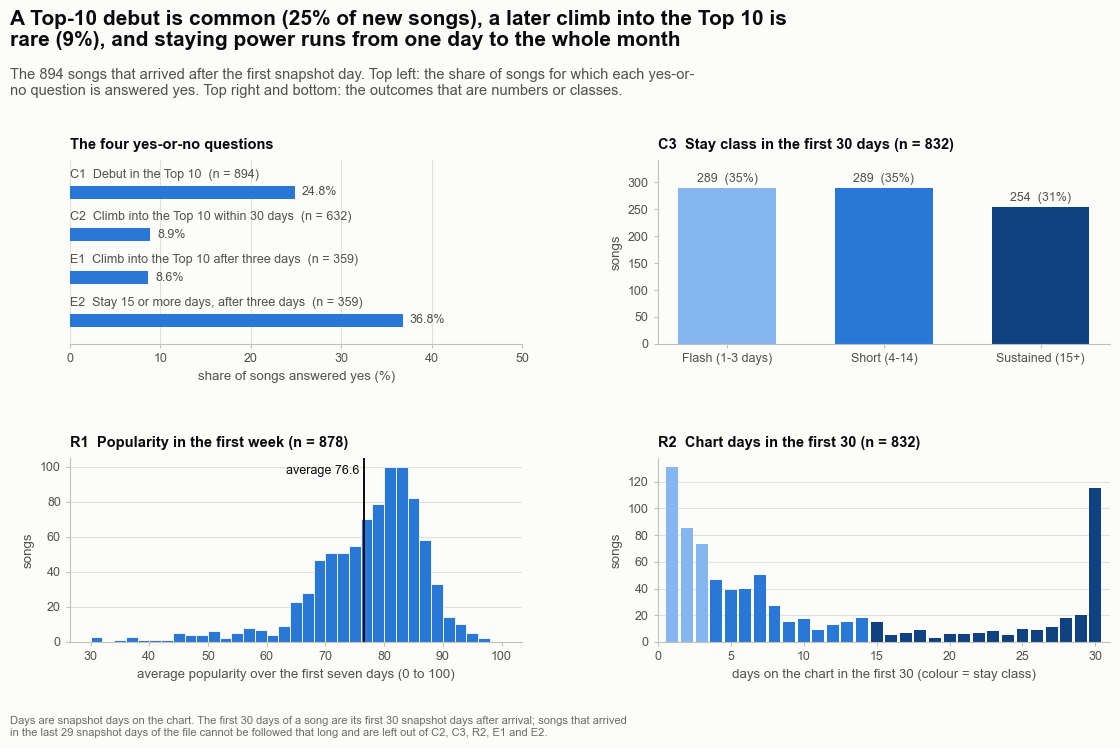

In [6]:
# Figure 01 - what the models try to forecast
STAY_COLORS = MP.step_colors(3)                                              # Flash (lightest), Short, Sustained (darkest)
first_week = TABLE.loc[TABLE["ok_pop"], "pop_first_week"].to_numpy()
chart_days = TABLE.loc[TABLE["ok_stay"], "chart_days_30"].to_numpy().astype(int)
FACTS["r2_one_day_songs"], FACTS["r2_full_month_songs"] = int((chart_days == 1).sum()), int((chart_days == 30).sum())      # the two ends of the spread of chart days

fig, axes = make_fig(11.8, 7.6, 2, 2, left=0.95, right=0.45, bottom=0.8, hspace=0.62, wspace=0.3, panel_titles=True,
                     title=f"A Top-10 debut is common ({FACTS['c1_rate_pct']:.0f}% of new songs), a later climb into the Top 10 is rare "
                           f"({FACTS['c2_rate_pct']:.0f}%), and staying power runs from one day to the whole month",
                     subtitle=f"The {FACTS['entrants']} songs that arrived after the first snapshot day. Top left: the share of songs for which each yes-or-no question is answered yes. "
                              "Top right and bottom: the outcomes that are numbers or classes.",
                     note_text="Days are snapshot days on the chart. The first 30 days of a song are its first 30 snapshot days after arrival; songs that arrived in the last 29 snapshot days of the file cannot be followed that long and are left out of C2, C3, R2, E1 and E2.")
(axa, axb), (axc, axd) = axes

binary_keys = ["debut_top10", "climb_top10", "climb_after3", "sustained_after3"]
labels = [f"{TASKS[k].code}  {TASKS[k].title}  (n = {FACTS[TASKS[k].code.lower() + '_n']})" for k in binary_keys]
values = [FACTS[f"{TASKS[k].code.lower()}_rate_pct"] for k in binary_keys]
y = np.arange(len(values))
axa.barh(y, values, height=0.3, color=style.BLUE)
for yi, label, value in zip(y, labels, values):
    axa.text(0, yi - 0.27, label, ha="left", va="bottom", fontsize=9, color=style.INK_2)          # the label sits above its bar: no room needed at the left
    axa.text(value + 0.8, yi, f"{value:.1f}%", ha="left", va="center", fontsize=9, color=style.INK_2)
axa.set_yticks([])
axa.set_ylim(len(values) - 0.45, -0.75)
axa.set_xlim(0, 50)
axa.set_xlabel("share of songs answered yes (%)")
style_axes(axa, grid="x", left_spine=False)
panel_title(axa, "The four yes-or-no questions")

counts = [FACTS["c3_flash"], FACTS["c3_short"], FACTS["c3_sustained"]]
axb.bar(range(3), counts, width=0.62, color=STAY_COLORS)
for i, count in enumerate(counts):
    axb.text(i, count + 6, f"{count}  ({100 * count / sum(counts):.0f}%)", ha="center", va="bottom", fontsize=9, color=style.INK_2)
axb.set_xticks(range(3))
axb.set_xticklabels(STAY_CLASSES, fontsize=9)
axb.set_ylim(0, max(counts) * 1.18)
axb.set_ylabel("songs")
style_axes(axb, grid=None)
panel_title(axb, f"C3  Stay class in the first 30 days (n = {FACTS['c3_n']})")

axc.hist(first_week, bins=np.arange(30, 102, 2), color=style.BLUE, edgecolor=style.SURFACE, linewidth=0.6)
axc.axvline(first_week.mean(), color=style.INK, linewidth=1.4)
direct_label(axc, first_week.mean() - 0.8, axc.get_ylim()[1] * 0.93, f"average {first_week.mean():.1f}", ha="right", size=9, color=style.INK)
axc.set_xlabel("average popularity over the first seven days (0 to 100)")
axc.set_ylabel("songs")
style_axes(axc, grid="y")
panel_title(axc, f"R1  Popularity in the first week (n = {FACTS['r1_n']})")

day_counts = np.bincount(chart_days, minlength=31)[1:]
colors = [STAY_COLORS[0] if d <= 3 else STAY_COLORS[1] if d <= 14 else STAY_COLORS[2] for d in range(1, 31)]
axd.bar(range(1, 31), day_counts, width=0.82, color=colors)
axd.set_xlabel("days on the chart in the first 30 (colour = stay class)")
axd.set_ylabel("songs")
axd.set_xlim(0, 31)
style_axes(axd, grid="y")
panel_title(axd, f"R2  Chart days in the first 30 (n = {FACTS['r2_n']})")
save_fig(fig, "p6a_01_outcomes", FIG_DIR)
plt.show()

**What to notice**

- A Top-10 debut happens to 222 of the 894 songs (25%). A climb into the Top 10 by a song that debuted outside it is rare: 56 of 632 (8.9%), about the same share as in E1 (31 of 359, 8.6%). Questions with so few yes answers have wide intervals, and the notebook says so wherever it matters.
- A stay of 15 or more days is common among songs that spent their first three days on the chart outside the Top 10: 132 of 359 (37%).
- The three stay classes are of similar size: Flash 289, Short 289, Sustained 254 songs. That is why C3 is scored by balanced accuracy (the share right within each class, averaged), whose chance level is 0.33.
- Chart days come in two lumps: 131 songs are on the chart for a single day and 115 for the whole month, with few songs on any one of the days in between. The median is 7 days, the mean 11.3 and the standard deviation 10.7, so the average says little about a typical song.
- First-week popularity is bunched at the high end, with a thin tail of less popular songs to the left, which is why the average (76.6) sits below the median (79). The standard deviation is only 10.8 on the 0 to 100 scale: a song that gets onto this chart is already a popular song, so there is little difference between songs to forecast. Keep this in mind for R1.

## Section 3 - The test: artist folds, the main run of all models, two checks of the test itself

How the models are tested matters as much as which models are used. This section explains the test (songs of an artist travel together, so artists are held out), runs every model on every question, and then tests the test twice: once to see how much a lazy random split would flatter the scores, and once to see that the machinery gives nothing but chance when there is nothing to learn.

**What this code is.** Figure 2 and the calculation behind it. For two ways of cutting the songs into five parts, a random cut and a cut by artist, the code measures the share of test songs whose artist also appears in the training part. It repeats each cut three times, and draws the result next to a chart of the ten artists with the most songs.

**Why we need it.** The songs of one artist are alike (Phase 5 measured how alike). A model that is trained on one song of an artist and tested on another song of the same artist can score well just by remembering the artist, which would not help with a new artist. Every score in this notebook is meant to say how well a model does on songs of artists it has never seen, so the test must keep an artist's songs together.

**What will happen.** The songs are cut into five parts at random (`random_folds`) and by artist (`repeated_grouped_folds`), three times each with different deals. For every cut the code counts the test songs whose artist has another song in the training part. `assert_no_group_overlap` stops the notebook if one artist ever sits on both sides of an artist cut. The code also stores facts about the artists: how many have a single song, which artist has the most songs, and how many songs the biggest ten have.

**Expected outcome.** A two-panel picture. On the left a few artists with very many songs; on the right two bars, a tall one for random folds (about 84% of test songs have a sibling in training) and none at all for artist folds (0%).

**Motive.** Settle once how every score in this notebook is made, and show why.

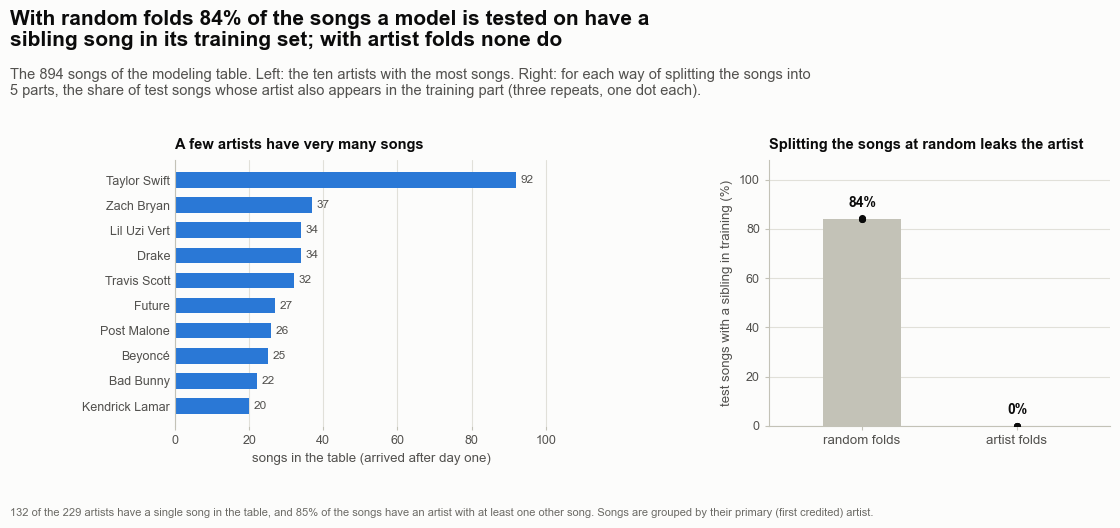

In [7]:
# Figure 02 - why the folds are made by artist: songs of one artist travel together
groups = TABLE["primary_artist"].to_numpy()
songs_per_artist = TABLE["primary_artist"].value_counts()


def share_with_artist_in_training(folds):
    """The share of test songs whose artist has at least one other song in the training part of the same split."""
    shared = np.zeros(len(groups), dtype=bool)
    for fold in np.unique(folds):
        test = folds == fold
        training_artists = set(groups[~test])
        shared[test] = [artist in training_artists for artist in groups[test]]
    return float(shared.mean())


random_shares = [share_with_artist_in_training(random_folds(len(TABLE), N_SPLITS, seed=s)) for s in range(N_REPEATS)]
artist_folds = repeated_grouped_folds(groups, N_SPLITS, N_REPEATS, seed=0)
artist_shares = [share_with_artist_in_training(folds) for folds in artist_folds]
for folds in artist_folds:
    assert_no_group_overlap(groups, folds)                                   # stops the notebook if one artist ever sits on both sides

sizes = np.bincount(artist_folds[0])
FACTS["artists_one_song"] = int((songs_per_artist == 1).sum())
FACTS["artists_one_song_pct"] = float(100 * (songs_per_artist == 1).mean())
FACTS["songs_with_artist_siblings_pct"] = float(100 * (TABLE["primary_artist"].map(songs_per_artist) > 1).mean())
FACTS["top_artist_name"] = str(songs_per_artist.index[0])
FACTS["top_artist_songs"] = int(songs_per_artist.iloc[0])
FACTS["top_artist_pct"] = float(100 * songs_per_artist.iloc[0] / len(TABLE))
FACTS["top10_artists_pct"] = float(100 * songs_per_artist.iloc[:10].sum() / len(TABLE))
FACTS["leak_random_pct"] = float(100 * np.mean(random_shares))
FACTS["leak_artist_pct"] = float(100 * np.mean(artist_shares))
FACTS["fold_songs_min"], FACTS["fold_songs_max"] = int(sizes.min()), int(sizes.max())
FACTS["fold_pos_min"] = int(min(TABLE.loc[artist_folds[0] == f, "y_debut_top10"].sum() for f in range(N_SPLITS)))
FACTS["fold_pos_max"] = int(max(TABLE.loc[artist_folds[0] == f, "y_debut_top10"].sum() for f in range(N_SPLITS)))

fig, (ax1, ax2) = make_fig(11.8, 5.4, 1, 2, left=2.0, right=0.45, bottom=0.9, wspace=0.55, panel_titles=True, width_ratios=[1.15, 1],
                           title=f"With random folds {FACTS['leak_random_pct']:.0f}% of the songs a model is tested on have a sibling song in its training set; "
                                 f"with artist folds none do",
                           subtitle=f"The {FACTS['entrants']} songs of the modeling table. Left: the ten artists with the most songs. Right: for each way of splitting the songs "
                                    f"into {N_SPLITS} parts, the share of test songs whose artist also appears in the training part (three repeats, one dot each).",
                           note_text=f"{FACTS['artists_one_song']} of the {FACTS['entrant_artists']} artists have a single song in the table, and {FACTS['songs_with_artist_siblings_pct']:.0f}% of the songs have an artist with at least one other song. "
                                     "Songs are grouped by their primary (first credited) artist.")
top = songs_per_artist.iloc[:10]
hbar(ax1, top.index.tolist(), top.to_numpy(), color=style.BLUE, fmt="{:.0f}", xlim=(0, top.iloc[0] * 1.15))
ax1.set_xlabel("songs in the table (arrived after day one)")
panel_title(ax1, "A few artists have very many songs")

labels = ["random folds", "artist folds"]
means = [100 * np.mean(random_shares), 100 * np.mean(artist_shares)]
ax2.bar([0, 1], means, width=0.5, color=[style.AXIS, style.BLUE])
for x, shares in zip([0, 1], [random_shares, artist_shares]):
    ax2.scatter(np.full(len(shares), x), 100 * np.array(shares), s=26, color=style.INK, zorder=4)
    ax2.text(x, 100 * np.mean(shares) + 3.5, f"{100 * np.mean(shares):.0f}%", ha="center", va="bottom", fontsize=10, fontweight="bold", color=style.INK)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_xlim(-0.6, 1.6)
ax2.set_ylim(0, 108)
ax2.set_ylabel("test songs with a sibling in training (%)")
style_axes(ax2, grid="y")
panel_title(ax2, "Splitting the songs at random leaks the artist")
save_fig(fig, "p6a_02_folds", FIG_DIR)
plt.show()

**What to notice**

- With random folds, 84% of the songs a model is tested on have another song of the same artist in its training part; with artist folds, 0%. The three dots of each bar are the three repeats, and they are almost the same.
- The table is dominated by a few artists: Taylor Swift has 92 of the 894 songs (10%), and the ten biggest artists together have 39%. At the other end, 132 of the 229 artists (58%) have a single song. Section 9 repeats the main results without Taylor Swift.
- Cutting by artist keeps the parts about the same size (178 to 179 songs) and gives every part enough Top-10 debuts to be scored (40 to 52 in the first repeat).
- Why it matters: 85% of the songs have an artist with at least one other song in the table, so a random split would let most test songs be recognised through a sibling.

**What this code is.** The main run. For each of the seven questions the cell calls `run_benchmark`. For every step of the ladder and every model, it makes a forecast for every song with models that never saw the song's artist (five parts, three repeats; the forecast of a song is the average of its three out-of-fold forecasts), scores the forecasts, and puts a 95% interval around every score by drawing the artists again 1,000 times. The models are: a straight-line model (logistic regression for yes-or-no and classes, ridge regression for numbers), gradient boosting (many small decision trees, each one correcting the mistakes of the ones before) and, at the last step only, a random forest (many trees that vote). A baseline that knows nothing is scored beside them.

**Why we need it.** Fair comparison means identical treatment: the same folds, repeats, scores and draws for every model and every question. A difference between two models is then a difference of the models, not of luck. The straight-line model is there on purpose. A complicated model has to beat it to be worth its complication, and if it does not, the straight line is the better description of the data.

**What will happen.** The seven benchmarks run one after the other and a line is printed for each (the number of songs, the number of step-and-model combinations scored, and the seconds it took). Every score and its interval is then stored in `FACTS` under a name such as `c1_artist_logistic_auc` (question, step, model, score). The cell ends with a first look: for each question, the main score of the baseline, the straight-line model, boosting and the forest at the last step of the ladder, each with its interval.

**Expected outcome.** Seven progress lines (94 step-and-model combinations scored in all) and a table with one row per question, scored by AUC for the yes-or-no questions, balanced accuracy for C3 and R-squared for the two numbers. It is the first answer to "how well can this be forecast": the scores are modest for most questions, and they differ from question to question. The sections that follow take them one at a time.

**Motive.** Every score of the rest of the notebook comes from this run.

In [8]:
BENCH = {}
for key, task in TASKS.items():
    started = time.time()
    BENCH[key] = run_benchmark(TABLE, key, n_splits=N_SPLITS, n_repeats=N_REPEATS, n_boot=N_BOOT)       # about 15 to 25 seconds per question
    print(f"{task.code}  {task.title:<42} {len(BENCH[key].y):>4} songs   {len(BENCH[key].table):>2} model fits scored   {time.time() - started:5.1f} s")
FACTS["benchmark_runs"] = int(sum(len(b.table) for b in BENCH.values()))

# ---- every score, with its interval, goes into FACTS under the name  <question>_<step>_<model>_<score>  (for example c1_artist_logistic_auc)
KEPT_SCORES = {"binary": ["auc", "average_precision"], "multiclass": ["balanced_accuracy", "weighted_kappa", "accuracy"], "regression": ["r2", "mae"]}
for key, bench in BENCH.items():
    for _, row in bench.table.iterrows():
        for score in KEPT_SCORES[bench.task.kind]:
            stem = f"{bench.task.code.lower()}_{row['step']}_{row['model']}_{score}"
            FACTS[stem], FACTS[stem + "_low"], FACTS[stem + "_high"] = float(row[score]), float(row[f"{score}_low"]), float(row[f"{score}_high"])

# ---- a first look: the score of every model at the LAST step of each question's ladder (the step with the most information)
LINEAR_NAME = {"binary": "logistic", "multiclass": "logistic", "regression": "ridge"}
first_look = []
for key, bench in BENCH.items():
    metric = MAIN_METRIC[bench.task.kind]
    last = bench.task.steps[-1]
    row = {"question": bench.task.code, "score": metric, "step": LADDER_LABELS[last].lstrip("+ ")}
    for label, model in [("baseline", "baseline"), ("straight-line model", LINEAR_NAME[bench.task.kind]), ("boosting", "boosting"), ("forest", "forest")]:
        low, high = bench.interval(last, model, metric)
        row[label] = f"{bench.score(last, model, metric):.3f}  ({low:.3f} to {high:.3f})"
    first_look.append(row)
display(pd.DataFrame(first_look).set_index("question"))

d:\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\ANACONDA\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\ANACONDA\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass

C1  Debut in the Top 10                         894 songs   10 model fits scored    17.9 s
C2  Climb into the Top 10 within 30 days        632 songs   13 model fits scored    20.8 s
C3  Stay class in the first 30 days             832 songs   13 model fits scored    37.1 s
R1  Popularity in the first week                878 songs   13 model fits scored    22.5 s
R2  Chart days in the first 30                  832 songs   13 model fits scored    21.4 s
E1  Climb into the Top 10 after three days      359 songs   16 model fits scored    16.4 s
E2  Stay 15 or more days, after three days      359 songs   16 model fits scored    15.7 s


,score,step,baseline,straight-line model,boosting,forest
question,,,,,,
C1,auc,Artist's record,0.500 (0.500 to 0.500),0.681 (0.643 to 0.728),0.650 (0.600 to 0.702),0.673 (0.623 to 0.725)
C2,auc,Debut-day chart,0.500 (0.500 to 0.500),0.686 (0.604 to 0.765),0.711 (0.635 to 0.779),0.699 (0.614 to 0.773)
C3,balanced_accuracy,Debut-day chart,0.333 (0.333 to 0.333),0.444 (0.397 to 0.484),0.504 (0.464 to 0.541),0.514 (0.475 to 0.554)
R1,r2,Debut-day chart,-0.021 (-0.093 to -0.006),-0.317 (-0.965 to 0.016),0.024 (-0.271 to 0.175),0.011 (-0.286 to 0.175)
R2,r2,Debut-day chart,-0.005 (-0.022 to -0.002),0.092 (0.013 to 0.159),0.218 (0.136 to 0.285),0.219 (0.150 to 0.281)
E1,auc,First three days,0.500 (0.500 to 0.500),0.800 (0.699 to 0.891),0.873 (0.810 to 0.929),0.870 (0.801 to 0.924)
E2,auc,First three days,0.500 (0.500 to 0.500),0.779 (0.718 to 0.833),0.821 (0.760 to 0.872),0.841 (0.784 to 0.886)


**What this code is.** Two checks of the test itself, on the three questions that carry the main results (C1 at the artist step, C2 at the debut step, E1 at the early step), each with the three real models. Check (a): the same forecasts made again with random folds instead of artist folds. Check (b): the real inputs but with the outcomes shuffled among the songs, three times, scored with the artist folds.

**Why we need it.** Check (a) measures how much a lazy split would flatter the models. Check (b) is a placebo: if the outcomes are shuffled there is nothing to learn, so every score should come out near the chance level (AUC 0.5). If it did not, the machinery would be creating skill out of nothing. A test that has not been shown to fail on nonsense proves little.

**What will happen.** For each of the nine question and model combinations the code makes the forecasts with random folds (three deals, averaged), scores them, and then shuffles the outcomes three times and scores the artist-fold forecasts of each shuffle. It stores the flattery (random-fold score minus artist-fold score) and the placebo scores.

**Expected outcome.** A table of nine rows with the artist-fold score, the random-fold score, three placebo scores and the flattery. Random folds score higher in 7 of the 9 rows, by 0.024 on average and by up to 0.061; the 27 placebo scores average 0.48.

**Motive.** Test the test: show how much a lazy split would have flattered the scores, and that the machinery does not invent skill.

In [9]:
# Two checks of the test itself, on the three questions that carry the main results (each at its last step, with the three real models)
CHECKS = [("debut_top10", "artist"), ("climb_top10", "debut"), ("climb_after3", "early")]
CHECK_MODELS = ["logistic", "forest", "boosting"]
N_SHUFFLES = 3

check_rows = []
for key, step in CHECKS:
    task = TASKS[key]
    data, y = task_data(TABLE, task)
    columns = feature_set(step, key)
    artists = data["primary_artist"].to_numpy()
    shuffle_folds = repeated_grouped_folds(artists, N_SPLITS, N_SHUFFLES, seed=100)
    rng = np.random.default_rng([SEED, len(y)])
    for name in CHECK_MODELS:
        def make(n=name):
            return make_classifier(n, seed=SEED)
        # (a) the same forecasts, but made with random folds: a song's own artist can sit in the training part
        random_sets = [random_folds(len(y), N_SPLITS, seed=s) for s in range(N_REPEATS)]
        random_forecast = cross_validated_predictions(make, data[columns], y, random_sets, kind="proba").mean(axis=0)
        # (b) the real inputs, but the outcomes shuffled among the songs: there is nothing to learn, so the score should be near 0.5
        placebo = []
        for s in range(N_SHUFFLES):
            y_shuffled = rng.permutation(y)
            forecast = cross_validated_predictions(make, data[columns], y_shuffled, [shuffle_folds[s]], kind="proba")[0]
            placebo.append(M.roc_auc(y_shuffled, forecast))
        row = {"question": task.code, "model": name, "step": step, "artist_folds": BENCH[key].score(step, name, "auc"),
               "random_folds": M.roc_auc(y, random_forecast), "placebo": placebo}
        check_rows.append(row)
        code = task.code.lower()
        FACTS[f"leak_{code}_{name}_artist"] = float(row["artist_folds"])
        FACTS[f"leak_{code}_{name}_random"] = float(row["random_folds"])
        FACTS[f"placebo_{code}_{name}_mean"] = float(np.mean(placebo))
CHECK = pd.DataFrame(check_rows)
CHECK["flattery"] = CHECK["random_folds"] - CHECK["artist_folds"]
all_placebo = np.concatenate(CHECK["placebo"].to_list())
for code, part in CHECK.groupby("question"):
    FACTS[f"leak_{code.lower()}_gap_min"], FACTS[f"leak_{code.lower()}_gap_max"] = float(part["flattery"].min()), float(part["flattery"].max())
FACTS["leak_gap_mean"] = float(CHECK["flattery"].mean())
FACTS["leak_gap_min"], FACTS["leak_gap_max"] = float(CHECK["flattery"].min()), float(CHECK["flattery"].max())
FACTS["leak_gap_positive"] = int((CHECK["flattery"] > 0).sum())
FACTS["leak_combinations"] = len(CHECK)
FACTS["placebo_runs"] = len(all_placebo)
FACTS["placebo_mean"], FACTS["placebo_sd"] = float(all_placebo.mean()), float(all_placebo.std(ddof=1))
FACTS["placebo_min"], FACTS["placebo_max"] = float(all_placebo.min()), float(all_placebo.max())
display(CHECK.assign(placebo=CHECK["placebo"].map(lambda v: " / ".join(f"{x:.3f}" for x in v)), model=CHECK["model"].map(MODEL_LABELS)).round(3).set_index(["question", "model"]))

step  artist_folds  random_folds                placebo  flattery
question model                                                                                   
C1       Logistic regression  artist         0.681         0.711  0.493 / 0.502 / 0.512     0.029
         Random forest        artist         0.673         0.721  0.419 / 0.488 / 0.492     0.048
         Gradient boosting    artist          0.65         0.714  0.460 / 0.537 / 0.495     0.063
C2       Logistic regression   debut         0.686         0.709  0.431 / 0.513 / 0.454     0.023
         Random forest         debut         0.699         0.746  0.493 / 0.406 / 0.447     0.046
         Gradient boosting     debut         0.711          0.74  0.525 / 0.534 / 0.558      0.03
E1       Logistic regression   early           0.8         0.808  0.469 / 0.425 / 0.435     0.008
         Random forest         early          0.87         0.856  0.448 / 0.394 / 0.435    -0.014
         Gradient boosting     early         0.873         0.859  0.442 / 0.694 / 0.400    -0.015

**What this code is.** Figure 3. Left panel: for each of the nine rows, a blue dot for the score with artist folds (the one this notebook uses) and a grey dot for the score with random folds, joined by a line, with the gap written at the right. Right panel: the same blue dot, and the three grey dots of the shuffled-outcome runs.

**Why we need it.** The table of the previous cell holds the numbers, and the picture makes the two answers easy to see: how far random folds push a score up, and how close the placebo stays to 0.5.

**What will happen.** The code puts the nine rows in three groups (one per question), draws the dots and lines, writes the gaps, and saves the picture as `p6a_03_checks.png`.

**Expected outcome.** Left, grey dots to the right of the blue ones for most rows; right, grey dots scattered around the 0.5 line, with the blue dots well to their right.

**Motive.** Show that the scores of the notebook are neither flattered by the split nor produced by the machinery.

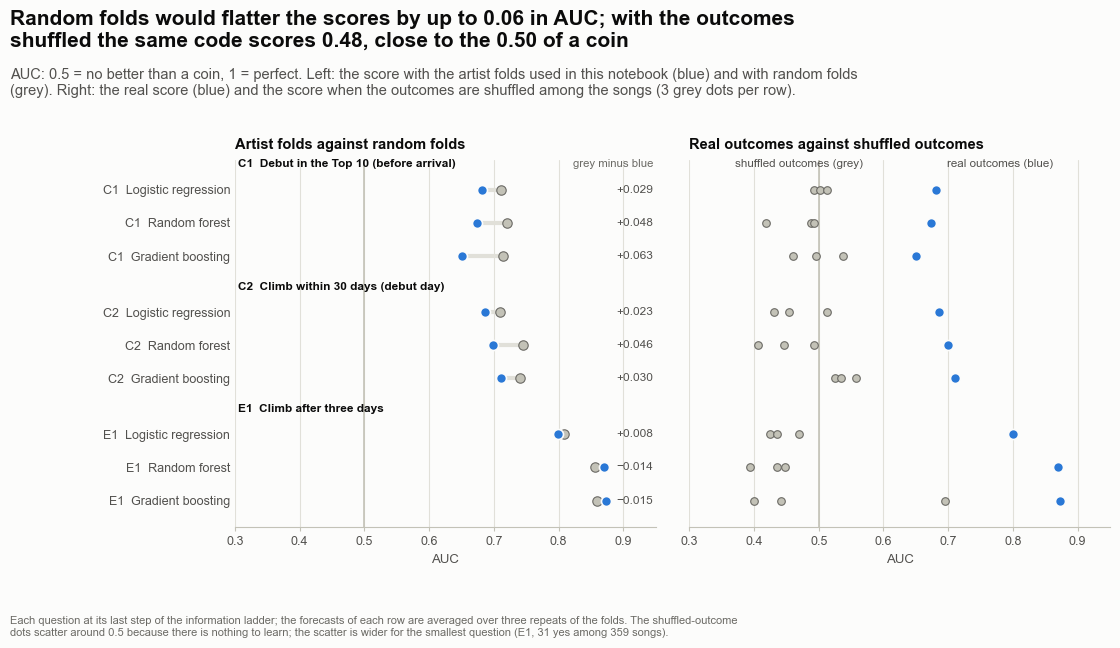

In [10]:
# Figure 03 - does the test flatter the models? Random folds against artist folds, and the same code on shuffled outcomes
rows = CHECK.reset_index(drop=True)
y_positions = np.array([0, 1, 2, 3.7, 4.7, 5.7, 7.4, 8.4, 9.4])
XLIM = (0.3, 0.95)

fig, (ax1, ax2) = make_fig(11.8, 6.6, 1, 2, left=2.6, right=0.45, bottom=0.95, wspace=0.08, panel_titles=True, sharey=True,
                           title=f"Random folds would flatter the scores by up to {FACTS['leak_gap_max']:.2f} in AUC; with the outcomes shuffled the same code scores "
                                 f"{FACTS['placebo_mean']:.2f}, close to the 0.50 of a coin",
                           subtitle="AUC: 0.5 = no better than a coin, 1 = perfect. Left: the score with the artist folds used in this notebook (blue) and with random folds (grey). "
                                    f"Right: the real score (blue) and the score when the outcomes are shuffled among the songs ({N_SHUFFLES} grey dots per row).",
                           note_text="Each question at its last step of the information ladder; the forecasts of each row are averaged over three repeats of the folds. "
                                     "The shuffled-outcome dots scatter around 0.5 because there is nothing to learn; the scatter is wider for the smallest question (E1, 31 yes among 359 songs).")
labels = [f"{r.question}  {MODEL_LABELS[r.model]}" for r in rows.itertuples()]
for ax in (ax1, ax2):
    ax.set_xlim(*XLIM)
    ax.axvline(0.5, color=style.AXIS, linewidth=1.2, zorder=1)
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("AUC")
ax1.set_yticks(y_positions)
ax1.set_yticklabels(labels, fontsize=9)
ax1.set_ylim(10.2, -0.9)
for code, first, title in [("C1", 0, "C1  Debut in the Top 10 (before arrival)"), ("C2", 3, "C2  Climb within 30 days (debut day)"), ("E1", 6, "E1  Climb after three days")]:
    ax1.text(XLIM[0] + 0.005, y_positions[first] - 0.62, title, ha="left", va="bottom", fontsize=8.6, fontweight="bold", color=style.INK)

for y_pos, row in zip(y_positions, rows.itertuples()):
    ax1.hlines(y_pos, min(row.artist_folds, row.random_folds), max(row.artist_folds, row.random_folds), color=style.GRID, linewidth=3, zorder=2)
    ax1.scatter([row.random_folds], [y_pos], s=46, color=style.AXIS, edgecolor=style.MUTED, linewidth=0.8, zorder=3)
    ax1.scatter([row.artist_folds], [y_pos], s=52, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
    gap = row.random_folds - row.artist_folds
    ax1.text(XLIM[1] - 0.004, y_pos, f"{gap:+.3f}".replace("-", "−"), ha="right", va="center", fontsize=8.6, color=style.INK_2)
    ax2.scatter(row.placebo, np.full(len(row.placebo), y_pos), s=30, color=style.AXIS, edgecolor=style.MUTED, linewidth=0.8, zorder=3)
    ax2.scatter([row.artist_folds], [y_pos], s=52, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
ax1.text(XLIM[1] - 0.004, -0.62, "grey minus blue", ha="right", va="bottom", fontsize=8.2, color=style.MUTED)
panel_title(ax1, "Artist folds against random folds")
panel_title(ax2, "Real outcomes against shuffled outcomes")
ax2.text(0.47, -0.62, "shuffled outcomes (grey)", ha="center", va="bottom", fontsize=8.4, color=style.INK_2)
ax2.text(0.78, -0.62, "real outcomes (blue)", ha="center", va="bottom", fontsize=8.4, color=style.INK_2)
save_fig(fig, "p6a_03_checks", FIG_DIR)
plt.show()

**What to notice**

- Random folds score higher than artist folds in 7 of the 9 rows. The flattery is 0.024 of AUC on average and as much as 0.061 (the largest is gradient boosting on C1). A flattery of that size is as large as some of the differences between steps of the ladder that the next sections measure, so it would have changed the story. Artist folds remove it.
- For C1 and C2 every flattery is positive (C1 from 0.029 to 0.061, C2 from 0.023 to 0.046). For E1 the three gaps are small and of mixed sign (-0.016 to 0.008): no flattery shows there, but with only 31 climbers a gap of that size is within noise.
- Right panel: with the outcomes shuffled, the 27 scores average 0.48 (lowest 0.39, highest 0.68). They scatter around 0.5 and on average a little below it, a known side effect of cross-validation: a part that happens to hold more yes answers leaves fewer of them for training, so its songs get lower forecasts. The scatter is widest for E1, the smallest question.
- Every real (blue) score lies to the right of the three shuffled dots of its own row, so the scores of the notebook are not what noise produces. The highest shuffled dot of all, 0.68, belongs to E1 and shows how much a question with 31 climbers can wander by luck alone; the intervals of E1 are wide for the same reason.

## Section 4 - C1 - Can a Top-10 debut be told before the song arrives?

The first question is asked before the song exists on the chart, so a model may use only what is known about the release, the day it arrives and the artist's earlier chart record. This section also introduces the words used for the rest of the notebook: *AUC* and the *ROC curve* (how well songs are put in order), *average precision*, *precision* and *recall* (how many of the songs we flag are right, and how many of the real ones we find), the *confusion matrix* (the four kinds of outcome of a yes-or-no forecast) and *calibration* (whether a forecast chance can be read as a chance).

**What this code is.** Two helper functions and the first tables of the notebook. `ladder_table` lays out, for every step of the ladder and every model, the scores with their 95% intervals (the baseline is left out: it knows nothing). `step_gains` works out what each step of the ladder adds to the main score, and how the models compare at the last step, and gives every difference its own 95% interval. The cell then prints the tables for C1.

**Why we need it.** "Is the model better?" is a question about a difference, and two separate intervals do not answer it: when a draw of artists is unlucky for one score it is usually unlucky for the other too, so the difference is steadier than the two scores. Every difference here is calculated on the same re-drawn sets of artists and has its own interval; an interval that includes zero means that the data do not show a difference. Two scores are shown. *AUC* is the chance that a randomly chosen song that did it gets a higher forecast than a randomly chosen song that did not: 0.5 is a coin, 1 is perfect. *Average precision* sums up how many of the songs flagged are right, over every possible cut-off; a random order scores the share of yes songs.

**What will happen.** The cell stores the share of Top-10 debuts (0.25) as the average precision of the baseline, which is what picking songs at random achieves. It then prints one table with the AUC and the average precision of every step and model with their intervals, and a second table of differences: what timing adds to release details, what the artist's record adds to timing, what both add together, for the straight-line model and for boosting, and at the last step how boosting and the forest compare with the straight line. Every difference is stored in `FACTS`.

**Expected outcome.** Two tables. In the first, the straight-line model rises from about 0.61 to 0.68 as the ladder goes up, while gradient boosting starts near a coin. In the second, most differences have intervals that include zero, and the ones that do not mark the steps that really add something.

**Motive.** Read every comparison as a difference with its own interval, never by eye from two overlapping bars.

In [11]:
def ladder_table(bench, metrics):
    """One row per (step, model): the listed scores, each with its 95% interval (the baseline, which knows nothing, is left out)."""
    table = bench.table[bench.table["model"] != "baseline"]
    out = pd.DataFrame({"step": table["step"].map(LADDER_LABELS), "model": table["model"].map(MODEL_LABELS)})
    for metric in metrics:
        out[metric] = [f"{v:.3f}  ({lo:.3f} to {hi:.3f})" for v, lo, hi in zip(table[metric], table[f"{metric}_low"], table[f"{metric}_high"])]
    return out.set_index(["step", "model"])


def step_gains(bench):
    """What each step of the ladder adds to the main score, and how the models compare at the last step; every difference has an interval from the SAME artist draws."""
    code, kind = bench.task.code.lower(), bench.task.kind
    metric, linear, steps = MAIN_METRIC[kind], LINEAR_NAME[bench.task.kind], list(bench.task.steps)
    rows = []

    def record(stem, text, model, a, b):
        diff, low, high = compare(bench, a, b)
        FACTS[stem], FACTS[stem + "_low"], FACTS[stem + "_high"] = diff, low, high
        rows.append({"comparison": text, "model": MODEL_LABELS[model], "difference": f"{diff:+.3f}", "95% interval": f"{low:+.3f} to {high:+.3f}"})

    for model in [linear, "boosting"]:
        for before, after in list(zip(steps[:-1], steps[1:])) + [(steps[0], steps[-1])]:
            record(f"{code}_add_{before}_to_{after}_{model}", f"{LADDER_LABELS[before].lstrip('+ ')} -> {LADDER_LABELS[after].lstrip('+ ')}", model, (after, model), (before, model))
    for other in ["boosting", "forest"]:
        record(f"{code}_{other}_vs_{linear}", f"at the last step: {MODEL_LABELS[other].lower()} minus {MODEL_LABELS[linear].lower()}", other, (steps[-1], other), (steps[-1], linear))
    return pd.DataFrame(rows).set_index("comparison")


C1 = BENCH["debut_top10"]
FACTS["c1_baseline_ap"] = float(C1.score("release", "baseline", "average_precision"))          # = the share of Top-10 debuts: what picking songs at random achieves
display(ladder_table(C1, ["auc", "average_precision"]))
print("Difference in AUC (the second score minus the first), with the 95% interval of the difference:")
with pd.option_context("display.max_colwidth", 90):
    display(step_gains(C1))

auc        average_precision
step              model                                                                
Release details   Logistic regression  0.614  (0.569 to 0.674)  0.335  (0.277 to 0.396)
                  Gradient boosting    0.511  (0.465 to 0.581)  0.267  (0.219 to 0.321)
+ Timing          Logistic regression  0.619  (0.568 to 0.676)  0.335  (0.275 to 0.389)
                  Gradient boosting    0.543  (0.487 to 0.618)  0.275  (0.234 to 0.324)
+ Artist's record Logistic regression  0.681  (0.643 to 0.728)  0.379  (0.313 to 0.443)
                  Gradient boosting    0.650  (0.600 to 0.702)  0.342  (0.283 to 0.393)
                  Random forest        0.673  (0.623 to 0.725)  0.357  (0.295 to 0.406)

Difference in AUC (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Logistic regression,+0.006,-0.075 to +0.059
Timing -> Artist's record,Logistic regression,+0.062,+0.005 to +0.121
Release details -> Artist's record,Logistic regression,+0.068,+0.012 to +0.116
Release details -> Timing,Gradient boosting,+0.032,-0.014 to +0.083
Timing -> Artist's record,Gradient boosting,+0.108,+0.028 to +0.174
Release details -> Artist's record,Gradient boosting,+0.139,+0.076 to +0.191
at the last step: gradient boosting minus logistic regression,Gradient boosting,-0.031,-0.069 to +0.004
at the last step: random forest minus logistic regression,Random forest,-0.008,-0.048 to +0.023


**What this code is.** Figure 4, and the function `ladder_and_roc` that draws it (it is used again for C2 in the next section). Left: the AUC of the three models at every step of the ladder, one dot per model and step with a bar for the 95% interval, and a line at 0.5 for a coin. Right: the *ROC curves* of the three models at the last step. A point on a curve is a cut-off: it shows the share of Top-10 debuts that would be flagged (up) against the share of other songs flagged by mistake (right). The grey diagonal is a coin.

**Why we need it.** AUC does not depend on any cut-off, so it is the fairest single summary of how well a model puts songs in order. The left panel shows how the score grows, or does not grow, as the model may know more. The right panel shows what a given AUC looks like as a curve: the further the curve bends towards the top left corner, the better the model separates the two kinds of song.

**What will happen.** The code draws the dots and bars from the stored scores, and calculates the ROC curve of every model from its out-of-fold forecasts of all 894 songs. It saves the picture as `p6a_04_c1_ladder.png`.

**Expected outcome.** Left, the straight-line model rising across the ladder and gradient boosting far below it at the first two steps. Right, three curves close together, above the diagonal and well short of the corner.

**Motive.** Show the main result for C1 and what it looks like.

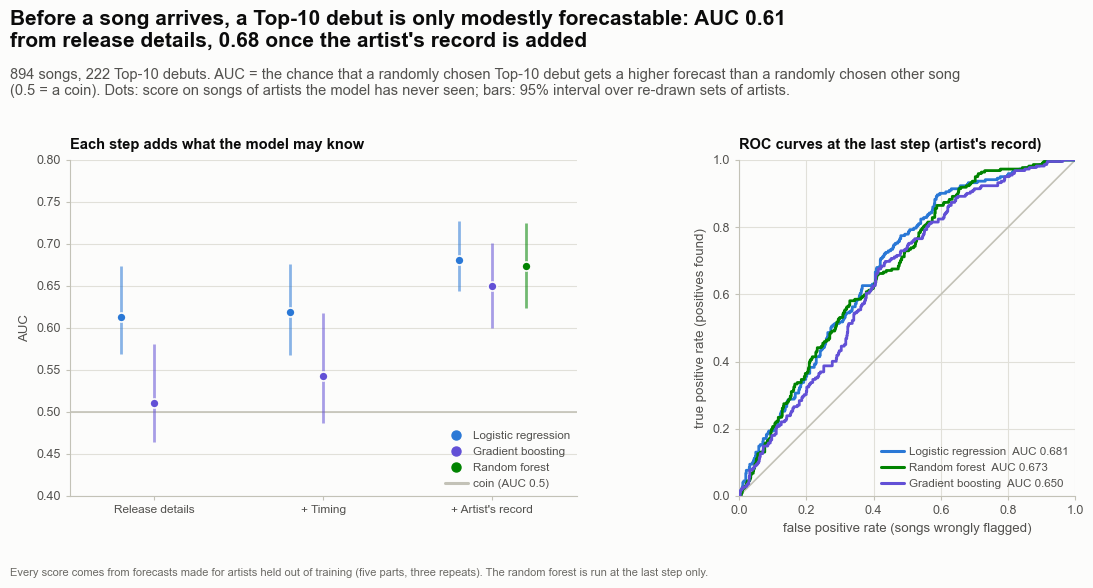

In [12]:
# Figure 04 - C1: can a Top-10 debut be forecast before the song arrives?
def ladder_and_roc(bench, fig_name, title, subtitle, ylim):
    """Left: the score of every model at every step of the ladder, with 95% intervals. Right: ROC curves at the last step."""
    last = bench.task.steps[-1]
    fig, (ax1, ax2) = make_fig(11.8, 6.0, 1, 2, left=0.95, right=0.45, bottom=0.8, wspace=0.28, panel_titles=True, width_ratios=[1.25, 1],
                               title=title, subtitle=subtitle,
                               note_text="Every score comes from forecasts made for artists held out of training (five parts, three repeats). The random forest is run at the last step only.")
    MP.draw_ladder(ax1, bench.table, bench.task.steps, ["logistic", "boosting", "forest"], "auc", LADDER_LABELS, MODEL_LABELS, reference=0.5,
                   ylim=ylim, ylabel="AUC", label_last=False)
    MP.ladder_legend(ax1, ["logistic", "boosting", "forest"], MODEL_LABELS, "coin (AUC 0.5)", loc="lower right")
    panel_title(ax1, "Each step adds what the model may know")
    curves = []
    for model in ["logistic", "forest", "boosting"]:
        fpr, tpr = M.roc_curve(bench.y, bench.predictions[(last, model)])
        curves.append({"label": f"{MODEL_LABELS[model]}  AUC {bench.score(last, model, 'auc'):.3f}", "fpr": fpr, "tpr": tpr, "color": MP.MODEL_COLORS[model]})
    MP.draw_roc(ax2, curves)
    panel_title(ax2, f"ROC curves at the last step ({LADDER_LABELS[last].lstrip('+ ').lower()})")
    save_fig(fig, fig_name, FIG_DIR)
    plt.show()


ladder_and_roc(C1, "p6a_04_c1_ladder",
               title=f"Before a song arrives, a Top-10 debut is only modestly forecastable: AUC {FACTS['c1_release_logistic_auc']:.2f} from release details, "
                     f"{FACTS['c1_artist_logistic_auc']:.2f} once the artist's record is added",
               subtitle=f"{FACTS['c1_n']} songs, {FACTS['c1_positives']} Top-10 debuts. AUC = the chance that a randomly chosen Top-10 debut gets a higher forecast than a randomly chosen "
                        f"other song (0.5 = a coin). Dots: score on songs of artists the model has never seen; bars: 95% interval over re-drawn sets of artists.",
               ylim=(0.4, 0.8))

**What to notice**

- With release details alone the straight-line model reaches an AUC of 0.61 (interval 0.57 to 0.67): above a coin, but only just. Gradient boosting, given the same five inputs, scores 0.51 (0.47 to 0.58), no better than a coin. A flexible model has many ways to fit chance patterns in a few hundred songs, and this is the reason the straight-line model always runs beside it.
- Timing adds nothing that the data can show: the straight-line AUC changes by +0.006 (interval -0.075 to +0.059) and boosting's by +0.029 (-0.018 to +0.082). Both include zero.
- The artist's record is the step that adds. From timing to the artist's record the straight-line AUC rises by +0.062 (+0.005 to +0.121) and boosting's by +0.108 (+0.032 to +0.173); neither interval includes zero.
- At the last step the three models are alike. Boosting minus the straight-line model is -0.031 (-0.067 to +0.004) and the forest minus the straight line -0.008 (-0.048 to +0.023). The extra flexibility finds nothing that the straight line misses, so the simplest model is also the best one here: AUC 0.68 (0.64 to 0.73).
- What an AUC of 0.68 means: pick one song that debuted in the Top 10 and one that did not, and in about 68% of such pairs the Top-10 debut gets the higher forecast. That is a real signal and a modest one. Before a song arrives, a Top-10 debut can be told only loosely.

**What this code is.** Figure 5, and the function `detail_figure` that draws it (it is used again for C2). It looks at the last step of the ladder in three panels. Left: *precision* against *recall* for every cut-off (precision = of the songs flagged, the share that were Top-10 debuts; recall = of the Top-10 debuts, the share that were flagged), with the base rate as a line. Middle: *calibration*. The songs are put in five groups by their forecast, and the average forecast chance of each group is set against the share that really did it; a model whose chances can be read as chances lies on the diagonal. Right: the *confusion matrix*. The songs with the highest forecasts are flagged, as many as there were Top-10 debuts (so precision and recall come out equal), and the four counts are shown: flagged and right, flagged and wrong, not flagged and right, not flagged and wrong.

**Why we need it.** AUC says how well songs are ordered, not what to do with the order. The three panels say it in counts of songs. They also show why accuracy alone is a poor guide when one answer is rare: a rule that says "no" for every song is right for the share of "no" songs, and that is hard to beat. The model shown in the middle and right panels is the one with the highest AUC at the last step. It was chosen on the same songs it is scored on, so what is shown is a little flattering; Section 9 puts it through harder tests.

**What will happen.** The code picks the model, flags the songs with the highest forecasts, counts the four cells, and calculates precision, recall, specificity, F1, accuracy and balanced accuracy with a 95% interval for each, from the same re-drawn sets of artists. It also stores the accuracy of answering "no" for every song, the calibration of the first and last group, and the Brier score (the average squared error of the forecast chances; lower is better) next to that of always forecasting the base rate. It saves the picture as `p6a_05_c1_detail.png`.

**Expected outcome.** Three panels: precision curves that start high on the left and settle near the base rate, calibration dots on or near the diagonal with bars, and a two-by-two table with the correct forecasts outlined.

**Motive.** Turn the AUC into numbers of songs that anyone can read, and show where the forecast chances can and cannot be trusted.

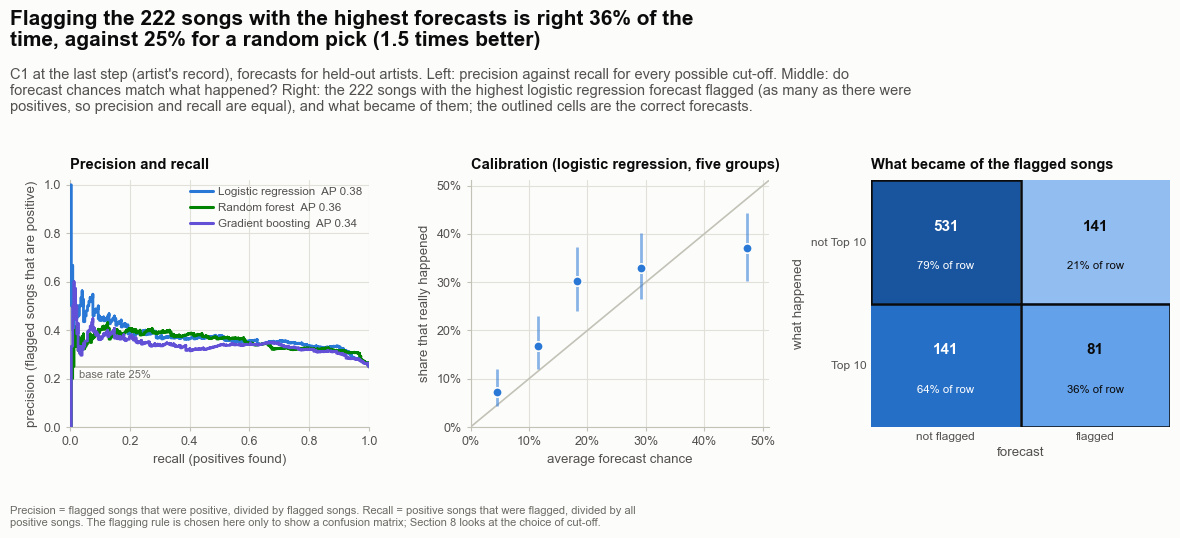

In [13]:
# Figure 05 - C1 in more detail: precision and recall, calibration, and the confusion matrix when as many songs are flagged as there are Top-10 debuts
def detail_figure(bench, fig_name, names):
    """Left: precision against recall. Middle: calibration. Right: the confusion matrix when as many songs are flagged as there are positives.
    The model shown in the middle and on the right is the one with the highest AUC at the last step; `names` = (the negative outcome, the positive outcome)."""
    code, last = bench.task.code.lower(), bench.task.steps[-1]
    chosen = max(["logistic", "forest", "boosting"], key=lambda m: bench.score(last, m, "auc"))
    FACTS[f"{code}_chosen_model"] = MODEL_LABELS[chosen].lower()
    score, y = bench.predictions[(last, chosen)], bench.y
    flagged = M.top_share_flags(score, y.sum() / len(y))                     # flag the songs with the highest forecasts: as many as there are real positives
    tp, fp, fn, tn = M.confusion_counts(y, flagged)
    point = M.threshold_scores(tp, fp, fn, tn)
    boot = M.threshold_scores(*M.confusion_counts(y, flagged, bench.weights))      # the same four counts for every re-drawn set of artists
    calibration = M.calibration_table(y, score, n_bins=5)
    FACTS[f"{code}_flagged"] = int(flagged.sum())
    for name, value in zip(["tp", "fp", "fn", "tn"], [tp, fp, fn, tn]):
        FACTS[f"{code}_flag_{name}"] = int(value)
    for name in ["precision", "recall", "specificity", "f1", "accuracy", "balanced_accuracy"]:
        low, high = M.interval(boot[name])
        FACTS[f"{code}_flag_{name}"], FACTS[f"{code}_flag_{name}_low"], FACTS[f"{code}_flag_{name}_high"] = float(point[name]), low, high
    FACTS[f"{code}_flag_lift"] = float(point["precision"] / y.mean())
    FACTS[f"{code}_always_no_accuracy"] = float(1 - y.mean())                # the accuracy of answering "no" for every song: the yardstick for the accuracy of the flags
    FACTS[f"{code}_cal_first_pred"], FACTS[f"{code}_cal_first_obs"] = float(calibration["mean_predicted"].iloc[0]), float(calibration["observed"].iloc[0])
    FACTS[f"{code}_cal_last_pred"], FACTS[f"{code}_cal_last_obs"] = float(calibration["mean_predicted"].iloc[-1]), float(calibration["observed"].iloc[-1])
    FACTS[f"{code}_brier"], FACTS[f"{code}_brier_baseline"] = bench.score(last, chosen, "brier"), bench.score(last, "baseline", "brier")

    fig, (ax1, ax2, ax3) = make_fig(12.4, 5.5, 1, 3, left=0.95, right=0.45, bottom=0.85, wspace=0.34, panel_titles=True,
                                    title=f"Flagging the {FACTS[code + '_flagged']} songs with the highest forecasts is right {100 * FACTS[code + '_flag_precision']:.0f}% of the time, "
                                          f"against {100 * y.mean():.0f}% for a random pick ({FACTS[code + '_flag_lift']:.1f} times better)",
                                    subtitle=f"{bench.task.code} at the last step ({LADDER_LABELS[last].lstrip('+ ').lower()}), forecasts for held-out artists. Left: precision against recall for every possible cut-off. "
                                             f"Middle: do forecast chances match what happened? Right: the {FACTS[code + '_flagged']} songs with the highest {MODEL_LABELS[chosen].lower()} forecast flagged "
                                             "(as many as there were positives, so precision and recall are equal), and what became of them; the outlined cells are the correct forecasts.",
                                    note_text="Precision = flagged songs that were positive, divided by flagged songs. Recall = positive songs that were flagged, divided by all positive songs. "
                                              "The flagging rule is chosen here only to show a confusion matrix; Section 8 looks at the choice of cut-off.")
    curves = []
    for model in ["logistic", "forest", "boosting"]:
        recall, precision = M.precision_recall_curve(y, bench.predictions[(last, model)])
        curves.append({"label": f"{MODEL_LABELS[model]}  AP {bench.score(last, model, 'average_precision'):.2f}", "recall": recall, "precision": precision, "color": MP.MODEL_COLORS[model]})
    MP.draw_pr(ax1, curves, float(y.mean()), legend_loc="upper right")
    panel_title(ax1, "Precision and recall")
    MP.draw_calibration(ax2, calibration, color=MP.MODEL_COLORS[chosen])
    panel_title(ax2, f"Calibration ({MODEL_LABELS[chosen].lower()}, five groups)")
    MP.draw_confusion(ax3, np.array([[tn, fp], [fn, tp]]), list(names), ["not flagged", "flagged"])
    panel_title(ax3, "What became of the flagged songs")
    save_fig(fig, fig_name, FIG_DIR)
    plt.show()


detail_figure(C1, "p6a_05_c1_detail", names=("not Top 10", "Top 10"))

**What to notice**

- The 222 songs with the highest forecasts (as many as there were Top-10 debuts) include 81 real Top-10 debuts. 141 flagged songs were not Top-10 debuts and 141 real ones were missed. Precision and recall are therefore both 36% (precision interval 29% to 42%), which is 1.5 times the 25% that a random pick achieves.
- The flags are right for 68% of all 894 songs. That sounds good and is not: answering "no" for every song would be right 75% of the time. When one answer is rare, accuracy alone misleads, which is why this notebook leads with AUC, precision and recall.
- Left panel: the precision curves start high for the very first songs and then settle close to the base rate. Average precision for the straight-line model is 0.38, against 0.25 for a random order.
- Calibration, middle panel: in the lowest fifth of songs the model says 4% on average and 7% really debuted in the Top 10; in the highest fifth it says 47% and 37% did. The order is right, but the chances are too extreme at both ends. Read the forecast as a rank, not as a probability.
- The Brier score is 0.177, against 0.187 for always forecasting the base rate (lower is better): a small gain, in line with the modest AUC.

## Section 5 - C2, C3, R1 and R2 - the questions asked on the debut day

On the day a song arrives, the chart itself adds a fourth step to the ladder: the place it enters at and its popularity that day. Four questions are asked at this point. C2: does a song that debuted outside the Top 10 climb into it within 30 days? C3: which stay class does it fall in, Flash (1 to 3 days), Short (4 to 14) or Sustained (15 or more)? R1: how popular is it in its first week? R2: on how many of its first 30 days is it on the chart? For R1 the popularity on the debut day is not an input, because it is almost the same number as the first-week popularity that is being forecast.

**What this code is.** The tables for C2, printed in the same layout as for C1: the AUC and the average precision of every step and model with their intervals, and the table of differences between steps and between models.

**Why we need it.** C2 is the first question asked after the song has appeared on the chart. It covers only the songs that debuted outside the Top 10 and could be followed for the full 30 days: 632 songs, of which 56 climbed into the Top 10. The table of differences is where the answer to "which step makes the difference" is read.

**What will happen.** The cell stores the share of songs that climbed as the baseline's average precision (0.09) and the best AUC at the debut step, then prints the two tables.

**Expected outcome.** AUC near 0.5 at the first step, rising across the ladder to about 0.71 at the debut step. The intervals are much wider than for C1 because there are only 56 climbers: every climber that is ranked a little higher or lower moves the score.

**Motive.** Find which step of the ladder carries C2, with a fair statement of how much the small number of climbers allows to be said.

In [14]:
C2 = BENCH["climb_top10"]
FACTS["c2_baseline_ap"] = float(C2.score("release", "baseline", "average_precision"))          # = the share of songs that did climb
FACTS["c2_debut_best_auc"] = max(C2.score("debut", m, "auc") for m in ["logistic", "forest", "boosting"])
display(ladder_table(C2, ["auc", "average_precision"]))
print("Difference in AUC (the second score minus the first), with the 95% interval of the difference:")
with pd.option_context("display.max_colwidth", 90):
    display(step_gains(C2))

auc        average_precision
step              model                                                                
Release details   Logistic regression  0.495  (0.389 to 0.599)  0.087  (0.064 to 0.124)
                  Gradient boosting    0.503  (0.407 to 0.591)  0.095  (0.069 to 0.155)
+ Timing          Logistic regression  0.589  (0.507 to 0.674)  0.126  (0.088 to 0.199)
                  Gradient boosting    0.605  (0.527 to 0.683)  0.133  (0.092 to 0.221)
+ Artist's record Logistic regression  0.646  (0.563 to 0.723)  0.164  (0.107 to 0.255)
                  Gradient boosting    0.603  (0.520 to 0.684)  0.178  (0.107 to 0.279)
+ Debut-day chart Logistic regression  0.686  (0.604 to 0.765)  0.216  (0.133 to 0.335)
                  Gradient boosting    0.711  (0.635 to 0.779)  0.269  (0.174 to 0.403)
                  Random forest        0.699  (0.614 to 0.773)  0.238  (0.151 to 0.376)

Difference in AUC (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Logistic regression,+0.094,-0.034 to +0.231
Timing -> Artist's record,Logistic regression,+0.057,+0.005 to +0.110
Artist's record -> Debut-day chart,Logistic regression,+0.040,-0.012 to +0.086
Release details -> Debut-day chart,Logistic regression,+0.191,+0.056 to +0.341
Release details -> Timing,Gradient boosting,+0.102,+0.018 to +0.193
Timing -> Artist's record,Gradient boosting,-0.002,-0.085 to +0.078
Artist's record -> Debut-day chart,Gradient boosting,+0.107,+0.050 to +0.168
Release details -> Debut-day chart,Gradient boosting,+0.208,+0.095 to +0.316
at the last step: gradient boosting minus logistic regression,Gradient boosting,+0.025,-0.040 to +0.092


**What this code is.** Figure 6: the same two-panel picture as Figure 4, for C2. Left: the AUC of the three models at every step. Right: the ROC curves at the last step, the debut-day chart.

**Why we need it.** The picture makes it easy to compare C2 with C1: the same layout, a different question, a different step at which the score starts to rise.

**What will happen.** The code calls `ladder_and_roc` with the C2 results and saves the picture as `p6a_06_c2_ladder.png`.

**Expected outcome.** Left, dots near the coin line at the first step that climb slowly across the ladder; right, three ROC curves above the diagonal, jagged because every step of a curve is one of only 56 climbers.

**Motive.** Show where C2 gets its signal.

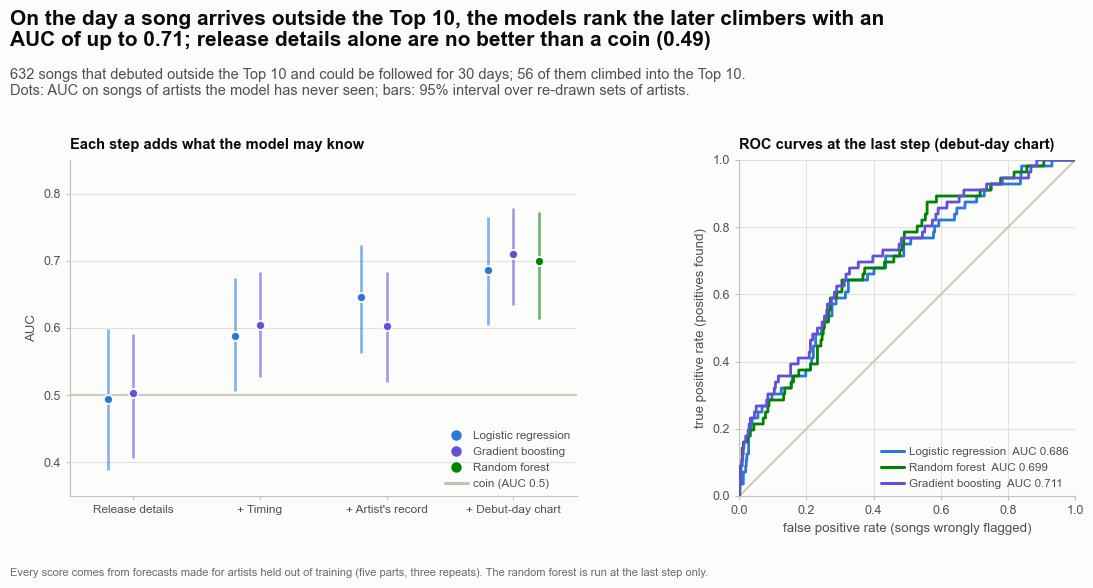

In [15]:
# Figure 06 - C2: on the day a song arrives outside the Top 10, can its later climb into the Top 10 be forecast?
ladder_and_roc(C2, "p6a_06_c2_ladder",
               title=f"On the day a song arrives outside the Top 10, the models rank the later climbers with an AUC of up to {FACTS['c2_debut_best_auc']:.2f}; "
                     f"release details alone are no better than a coin ({FACTS['c2_release_logistic_auc']:.2f})",
               subtitle=f"{FACTS['c2_n']} songs that debuted outside the Top 10 and could be followed for 30 days; {FACTS['c2_positives']} of them climbed into the Top 10. "
                        "Dots: AUC on songs of artists the model has never seen; bars: 95% interval over re-drawn sets of artists.",
               ylim=(0.35, 0.85))

**What to notice**

- Release details alone are no better than a coin: the AUC is 0.49 (0.39 to 0.60) for the straight-line model and 0.50 for boosting. Whether a song is explicit, on a big release or a collaboration gives no sign of a later climb from outside the Top 10.
- The step that matters is the debut-day chart. From release details to the debut-day chart the straight-line AUC rises by +0.191 (interval +0.056 to +0.341) and boosting's by +0.207 (+0.094 to +0.315); neither interval includes zero.
- The artist's record is harder to read here. From timing to the artist's record the straight-line AUC rises by +0.057 (+0.005 to +0.110) while boosting's changes by -0.000 (-0.084 to +0.081). With 56 climbers the data can not say whether the artist's record adds anything beyond timing.
- At the debut step the best AUC is 0.71 (gradient boosting, interval 0.63 to 0.78). The three models are not clearly different: boosting minus the straight line is +0.024 (-0.041 to +0.090) and the forest minus the straight line +0.013 (-0.081 to +0.093).
- The lower end of the best model's interval is 0.63. The data rule out a coin, and they allow anything from a weak to a fairly useful ranking.

**What this code is.** Figure 7: the same three panels as Figure 5, for C2: precision against recall, calibration, and the confusion matrix when as many songs are flagged as there were climbers.

**Why we need it.** The same reasons as for C1. It matters more here, because a rare outcome is where accuracy misleads most and where the forecast chance is most likely to be read wrongly.

**What will happen.** The code calls `detail_figure` with the C2 results (the model with the highest AUC at the debut step is shown in the middle and right panels) and saves the picture as `p6a_07_c2_detail.png`.

**Expected outcome.** A jagged precision curve, a calibration plot with wide bars, and a confusion matrix whose flagged column is small.

**Motive.** Put the C2 result into counts of songs, and show how much a handful of songs moves it.

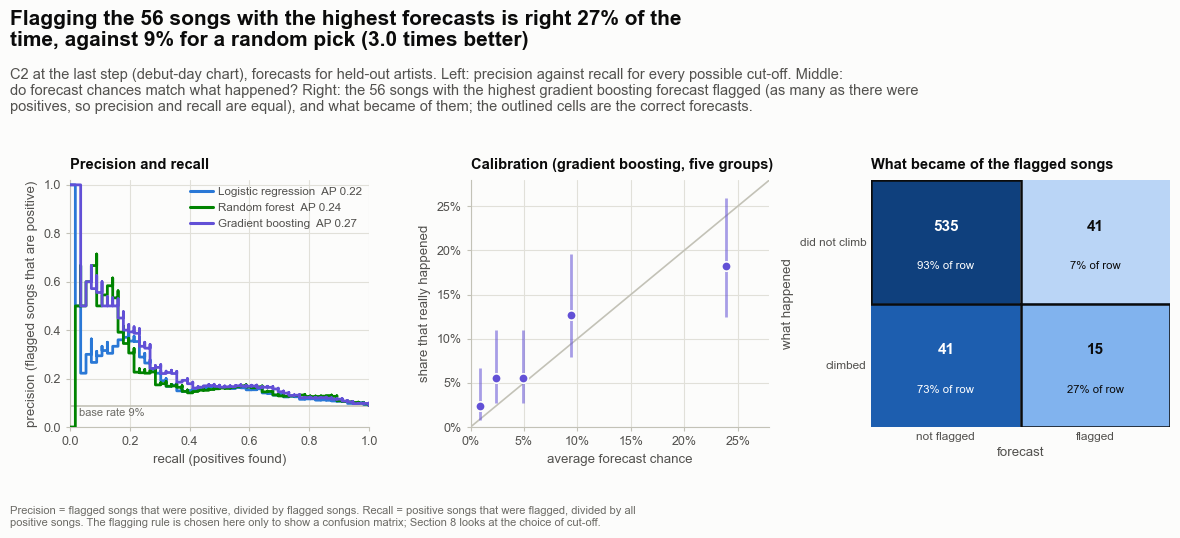

In [16]:
# Figure 07 - C2 in more detail: precision and recall, calibration, and the confusion matrix when as many songs are flagged as there were climbers
detail_figure(C2, "p6a_07_c2_detail", names=("did not climb", "climbed"))

**What to notice**

- The 56 songs with the highest forecasts (as many as there were climbers) include 15 songs that really climbed. 41 flagged songs did not climb and 41 climbers were missed. Precision and recall are both 27% (precision interval 16% to 40%), which is 3.0 times the 9% of a random pick. The interval is wide: it rests on 56 climbers.
- The accuracy of the flags is 87%, below the 91% of answering "no climb" for every song. This is the accuracy trap again, and stronger than for C1 because the yes is rarer.
- Left panel: only the very top of the ranking is clearly better than a random pick. Precision is high for the first few songs and falls to the base rate of 9% as more songs are flagged. The curves are jagged because every step is one climber.
- Calibration: in the highest fifth of songs the model says 24% and 18% climbed, a little lower than forecast; in the lowest fifth it says 0.9% and 2.4% climbed. The bars are wide because each group holds few climbers.
- The Brier score is 0.075, against 0.081 for always forecasting the base rate: hardly any gain in the squared error of the chances, although the ranking is useful.

**What this code is.** C3 and Figure 8. First the tables (balanced accuracy, weighted kappa and accuracy at every step and model, then the differences). Then four panels. Top left: balanced accuracy of every model at every step. The other three: the confusion matrix of each model at the debut step, class by class (the colour is the share of the row, the number is songs), with the correct forecasts outlined.

**Why we need it.** C3 has three classes, so there is no single yes to find. *Balanced accuracy* is the share right within each class, averaged over the three, so that the chance level is 0.33 whatever the class sizes. *Weighted kappa* counts a miss by two classes (Flash called Sustained) as worse than a miss by one, which is what the order of the classes calls for. The confusion matrices show which classes are confused with which.

**What will happen.** The cell prints the tables, then for each model puts together the confusion matrix of its most likely class against the real class. It stores the recall of each class and how often a Flash song is called Sustained or the reverse (a "far miss"), next to the share of far misses that unrelated forecasts would give with the same row and column totals. It then draws the figure, with the best model first, and saves it as `p6a_08_c3_classes.png`.

**Expected outcome.** Flat balanced accuracy near chance for the first three steps, a jump at the debut-day chart, and three matrices with most of the weight on the diagonal for Flash and Sustained, less for Short.

**Motive.** Show what a three-class forecast gets right and which mistakes it makes.

balanced_accuracy            weighted_kappa                 accuracy
step              model                                                                                          
Release details   Logistic regression  0.366  (0.306 to 0.433)  0.064  (-0.030 to 0.188)  0.362  (0.299 to 0.429)
                  Gradient boosting    0.363  (0.326 to 0.396)   0.105  (0.022 to 0.191)  0.358  (0.324 to 0.395)
+ Timing          Logistic regression  0.372  (0.325 to 0.432)   0.082  (0.001 to 0.172)  0.371  (0.321 to 0.430)
                  Gradient boosting    0.365  (0.327 to 0.402)   0.137  (0.042 to 0.231)  0.359  (0.321 to 0.406)
+ Artist's record Logistic regression  0.378  (0.317 to 0.442)   0.119  (0.038 to 0.205)  0.379  (0.313 to 0.444)
                  Gradient boosting    0.371  (0.320 to 0.426)  0.078  (-0.025 to 0.193)  0.367  (0.312 to 0.423)
+ Debut-day chart Logistic regression  0.444  (0.397 to 0.484)   0.219  (0.141 to 0.293)  0.445  (0.399 to 0.486)
                  Gradient boosting    0.504  (0.464 to 0.541)   0.348  (0.272 to 0.414)  0.501  (0.464 to 0.537)
                  Random forest        0.514  (0.475 to 0.554)   0.350  (0.278 to 0.420)  0.513  (0.474 to 0.557)

Difference in balanced accuracy (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Logistic regression,+0.006,-0.049 to +0.051
Timing -> Artist's record,Logistic regression,+0.006,-0.037 to +0.049
Artist's record -> Debut-day chart,Logistic regression,+0.066,-0.002 to +0.132
Release details -> Debut-day chart,Logistic regression,+0.078,+0.003 to +0.143
Release details -> Timing,Gradient boosting,+0.001,-0.024 to +0.034
Timing -> Artist's record,Gradient boosting,+0.006,-0.046 to +0.063
Artist's record -> Debut-day chart,Gradient boosting,+0.133,+0.073 to +0.192
Release details -> Debut-day chart,Gradient boosting,+0.141,+0.093 to +0.186
at the last step: gradient boosting minus logistic regression,Gradient boosting,+0.060,+0.016 to +0.110


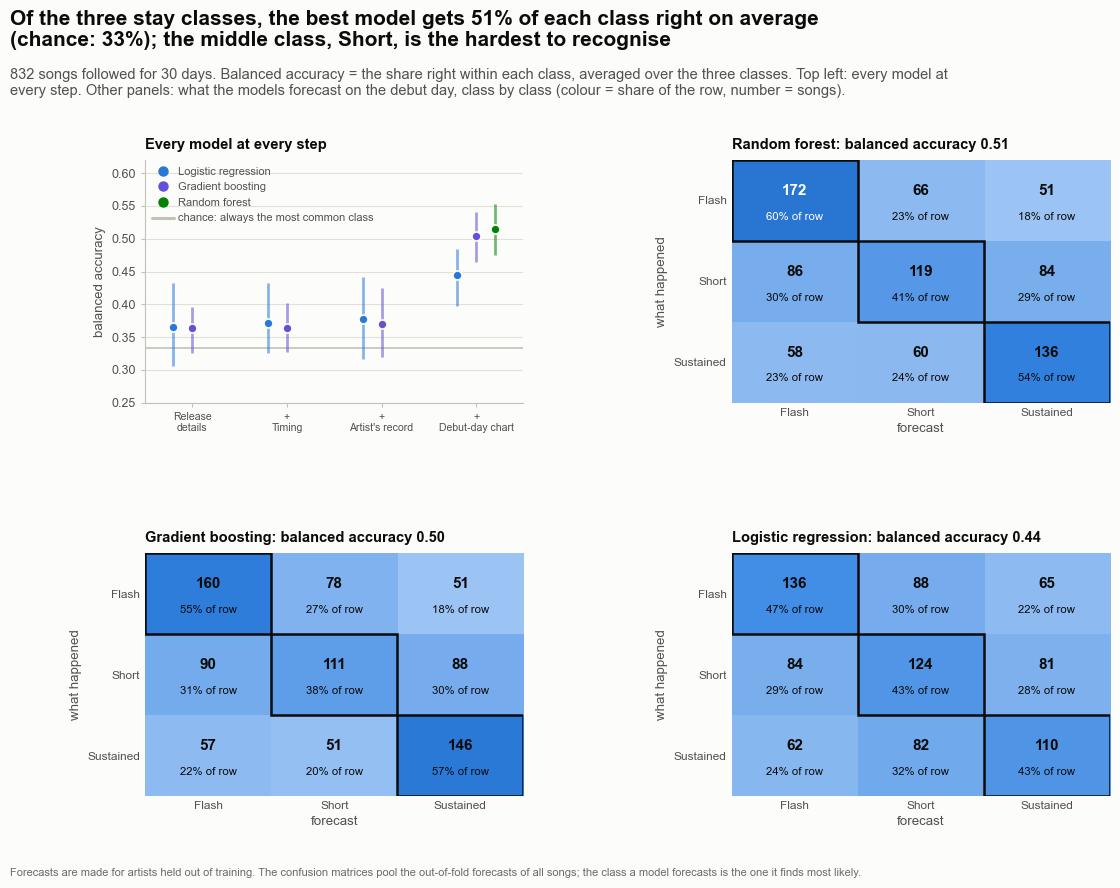

In [17]:
# Figure 08 - C3: the stay class in the first 30 days (Flash 1-3 days, Short 4-14, Sustained 15 or more), forecast on the day the song arrives
C3 = BENCH["stay_class"]
FACTS["c3_chance_balanced_accuracy"] = 1 / len(STAY_CLASSES)
display(ladder_table(C3, ["balanced_accuracy", "weighted_kappa", "accuracy"]))
print("Difference in balanced accuracy (the second score minus the first), with the 95% interval of the difference:")
with pd.option_context("display.max_colwidth", 90):
    display(step_gains(C3))

order = sorted(["logistic", "boosting", "forest"], key=lambda m: -C3.score("debut", m, "balanced_accuracy"))      # best model first
matrices = {}
for model in order:
    guess = C3.predictions[("debut", model)].argmax(axis=1)                  # the class the model finds most likely
    cm = M.confusion_matrix(C3.y, guess, len(STAY_CLASSES))
    matrices[model] = cm
    for name, recall in zip(["flash", "short", "sustained"], np.diag(cm) / cm.sum(axis=1)):
        FACTS[f"c3_recall_{model}_{name}"] = float(recall)
    rows, columns = cm.sum(axis=1), cm.sum(axis=0)
    FACTS[f"c3_far_miss_{model}_pct"] = float(100 * (cm[0, 2] + cm[2, 0]) / cm.sum())                    # a Flash song called Sustained, or the reverse
    FACTS[f"c3_far_miss_chance_{model}_pct"] = float(100 * (rows[0] * columns[2] + rows[2] * columns[0]) / cm.sum() ** 2)   # what unrelated forecasts would give
FACTS["c3_best_model"] = MODEL_LABELS[order[0]].lower()
best_score = C3.score("debut", order[0], "balanced_accuracy")

fig, axes = make_fig(11.8, 9.0, 2, 2, left=1.7, right=0.45, bottom=0.8, hspace=0.62, wspace=0.55, panel_titles=True,
                     title=f"Of the three stay classes, the best model gets {100 * best_score:.0f}% of each class right on average (chance: {100 / len(STAY_CLASSES):.0f}%); "
                           f"the middle class, Short, is the hardest to recognise",
                     subtitle=f"{FACTS['c3_n']} songs followed for 30 days. Balanced accuracy = the share right within each class, averaged over the three classes. "
                              "Top left: every model at every step. Other panels: what the models forecast on the debut day, class by class (colour = share of the row, number = songs).",
                     note_text="Forecasts are made for artists held out of training. The confusion matrices pool the out-of-fold forecasts of all songs; the class a model forecasts is the one it finds most likely.")
ax_ladder = axes[0, 0]
MP.draw_ladder(ax_ladder, C3.table, C3.task.steps, ["logistic", "boosting", "forest"], "balanced_accuracy", LADDER_LABELS, MODEL_LABELS, reference=1 / 3,
               ylim=(0.25, 0.62), ylabel="balanced accuracy", label_last=False)
ax_ladder.set_xticklabels([LADDER_LABELS[s].replace("+ ", "+\n").replace(" details", "\ndetails") for s in C3.task.steps], fontsize=7.6)
MP.ladder_legend(ax_ladder, ["logistic", "boosting", "forest"], MODEL_LABELS, "chance: always the most common class", loc="upper left", fontsize=8.0)
panel_title(ax_ladder, "Every model at every step")
for ax, model in zip([axes[0, 1], axes[1, 0], axes[1, 1]], order):
    MP.draw_confusion(ax, matrices[model], [name.split(" (")[0] for name in STAY_CLASSES], [name.split(" (")[0] for name in STAY_CLASSES])
    panel_title(ax, f"{MODEL_LABELS[model]}: balanced accuracy {C3.score('debut', model, 'balanced_accuracy'):.2f}")
save_fig(fig, "p6a_08_c3_classes", FIG_DIR)
plt.show()

**What to notice**

- Before the debut-day chart no model is clearly above chance. The balanced accuracy of every model at the release, timing and artist steps lies between 0.36 and 0.38, against a chance level of 0.33, and the intervals reach down to chance.
- The debut-day chart is where the signal comes from. At the debut step the random forest reaches 0.51 (0.47 to 0.55), gradient boosting 0.50 (0.46 to 0.54) and the straight-line model 0.44 (0.40 to 0.48).
- Here the flexible models clearly beat the straight line: the forest minus the straight line is +0.070 (interval +0.035 to +0.110) and boosting minus the straight line +0.057 (+0.012 to +0.110). Whatever the debut-day chart tells about the stay is not a straight-line relation. Figure 14 shows the curve for the number of chart days.
- Class by class, the middle class is the hardest for the two best models. The forest gets 60% of the Flash songs right, 41% of the Short songs and 54% of the Sustained songs; boosting gets 55%, 38% and 57%. The straight-line model is more even (47%, 43% and 43%) and lower overall.
- The mistake that matters most, calling a Flash song Sustained or the reverse, happens for 13% of songs with the forest, against 23% if its forecasts had nothing to do with what happened. The forecasts are far from perfect and they are not random.

**What this code is.** R1 and R2 and Figure 9. For each of the two numbers the cell stores the mean absolute error of always forecasting the average (the baseline), the best R-squared at the debut step and which model gets it, and prints the tables (R-squared and mean absolute error at every step and model, then the differences). Then four panels. Top: R-squared of every model at every step, for R1 on the left and R2 on the right. Bottom: for the model with the best R-squared at the debut step, the forecast of every song against what happened, one dot per song, with the average outcome of ten equal groups of songs sorted by forecast as a black line.

**Why we need it.** *R-squared* is the share of the differences between songs that the forecasts account for. Zero means no better than always forecasting the average; below zero means worse. It is the honest way to say how much of a number can be forecast. The *mean absolute error* says the same in the unit of the outcome (popularity points, days). The bottom panels show what the R-squared looks like: a good forecast puts the black line on the grey 45-degree line.

**What will happen.** The cell prints four tables, draws the two ladders, and draws the two dot clouds with their group averages. It saves the picture as `p6a_09_numbers.png`.

**Expected outcome.** R1 with every dot at or below zero and a flat black line; R2 with R-squared at about zero until the debut-day chart and about 0.22 with it, and a black line that rises along the 45-degree line.

**Motive.** Say how much of each number can be forecast, which for R1 is nothing.

r2                       mae
step              model                                                                  
Release details   Ridge regression   -0.069  (-0.250 to -0.000)   8.157  (7.157 to 9.290)
                  Gradient boosting   -0.109  (-0.434 to 0.077)   8.664  (7.620 to 9.723)
+ Timing          Ridge regression    -0.039  (-0.267 to 0.063)   8.061  (6.949 to 9.243)
                  Gradient boosting   -0.073  (-0.360 to 0.042)   8.177  (7.112 to 9.310)
+ Artist's record Ridge regression    -0.335  (-1.031 to 0.018)  9.192  (7.319 to 11.321)
                  Gradient boosting   -0.048  (-0.392 to 0.136)   8.019  (6.735 to 9.338)
+ Debut-day chart Ridge regression    -0.317  (-0.965 to 0.016)  9.119  (7.272 to 11.226)
                  Gradient boosting    0.024  (-0.271 to 0.175)   7.649  (6.423 to 8.886)
                  Random forest        0.011  (-0.286 to 0.175)   7.636  (6.356 to 8.878)

R1: difference in R-squared (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Ridge regression,+0.030,-0.035 to +0.087
Timing -> Artist's record,Ridge regression,-0.296,-0.761 to -0.013
Artist's record -> Debut-day chart,Ridge regression,+0.018,-0.021 to +0.061
Release details -> Debut-day chart,Ridge regression,-0.247,-0.729 to +0.037
Release details -> Timing,Gradient boosting,+0.036,-0.086 to +0.159
Timing -> Artist's record,Gradient boosting,+0.025,-0.129 to +0.150
Artist's record -> Debut-day chart,Gradient boosting,+0.071,+0.016 to +0.137
Release details -> Debut-day chart,Gradient boosting,+0.133,+0.031 to +0.251
at the last step: gradient boosting minus ridge regression,Gradient boosting,+0.341,+0.123 to +0.729


r2                      mae
step              model                                                                
Release details   Ridge regression     0.047  (0.008 to 0.085)  8.895  (8.330 to 9.617)
                  Gradient boosting   0.012  (-0.046 to 0.061)  9.103  (8.432 to 9.874)
+ Timing          Ridge regression    0.031  (-0.021 to 0.077)  8.883  (8.302 to 9.573)
                  Gradient boosting  -0.004  (-0.061 to 0.050)  9.057  (8.417 to 9.804)
+ Artist's record Ridge regression   -0.015  (-0.122 to 0.074)  8.965  (8.445 to 9.580)
                  Gradient boosting   0.007  (-0.050 to 0.062)  8.955  (8.301 to 9.713)
+ Debut-day chart Ridge regression     0.092  (0.013 to 0.159)  8.435  (7.807 to 9.138)
                  Gradient boosting    0.218  (0.136 to 0.285)  7.872  (7.177 to 8.689)
                  Random forest        0.219  (0.150 to 0.281)  7.959  (7.338 to 8.684)

R2: difference in R-squared (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Ridge regression,-0.016,-0.053 to +0.019
Timing -> Artist's record,Ridge regression,-0.046,-0.131 to +0.018
Artist's record -> Debut-day chart,Ridge regression,+0.107,+0.026 to +0.192
Release details -> Debut-day chart,Ridge regression,+0.045,-0.025 to +0.104
Release details -> Timing,Gradient boosting,-0.016,-0.055 to +0.018
Timing -> Artist's record,Gradient boosting,+0.011,-0.034 to +0.056
Artist's record -> Debut-day chart,Gradient boosting,+0.211,+0.139 to +0.271
Release details -> Debut-day chart,Gradient boosting,+0.206,+0.116 to +0.277
at the last step: gradient boosting minus ridge regression,Gradient boosting,+0.126,+0.065 to +0.189


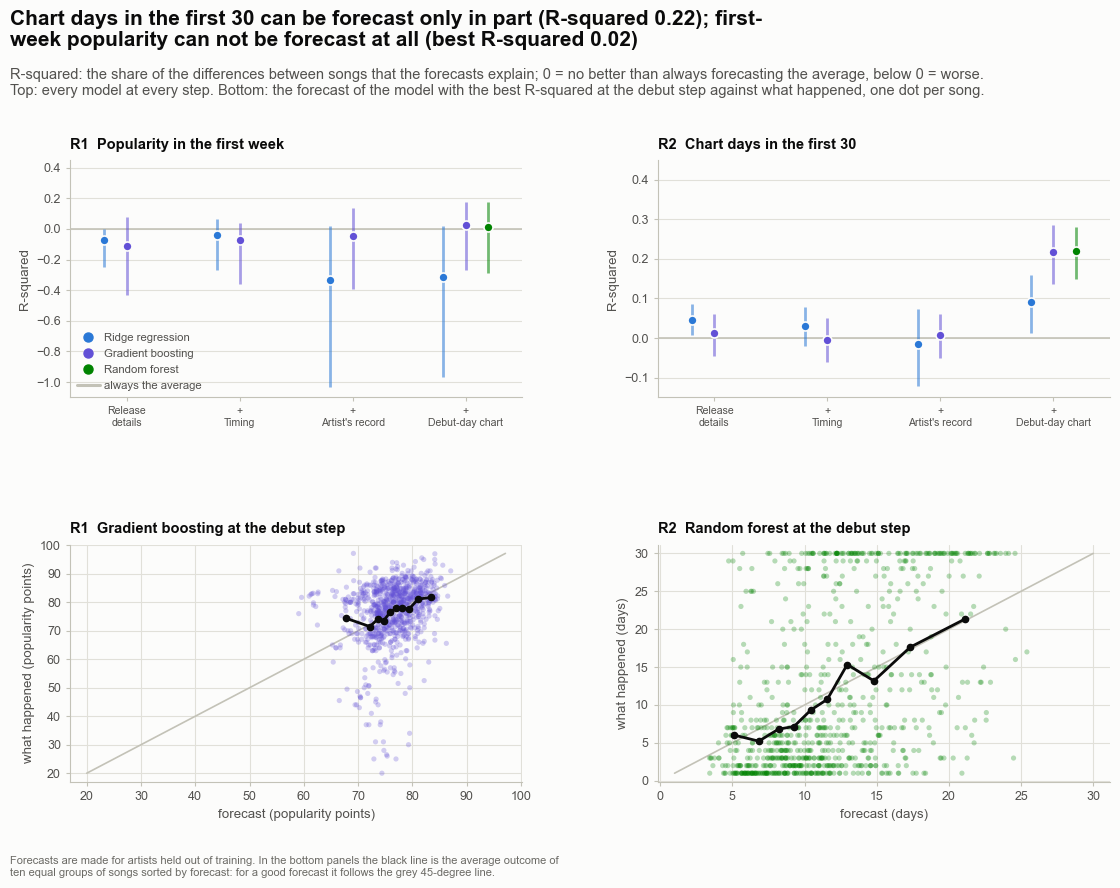

In [18]:
# Figure 09 - R1 and R2: the two outcomes that are numbers, forecast on the day the song arrives
R1, R2 = BENCH["first_week_popularity"], BENCH["chart_days"]
for bench in (R1, R2):
    FACTS[f"{bench.task.code.lower()}_baseline_mae"] = float(bench.score("debut", "baseline", "mae"))
    FACTS[f"{bench.task.code.lower()}_best_model_r2"] = max(bench.score("debut", m, "r2") for m in ["ridge", "boosting", "forest"])
    FACTS[f"{bench.task.code.lower()}_best_model"] = max(["ridge", "boosting", "forest"], key=lambda m: bench.score("debut", m, "r2"))
    best = FACTS[f"{bench.task.code.lower()}_best_model"]
    forecast, actual = np.asarray(bench.predictions[("debut", best)], dtype=float), np.asarray(bench.y, dtype=float)
    groups = np.array_split(np.argsort(forecast, kind="stable"), 10)                       # ten equal groups of songs sorted by forecast: the black line of the figure
    rise_forecast, rise_actual = forecast[groups[-1]].mean() - forecast[groups[0]].mean(), actual[groups[-1]].mean() - actual[groups[0]].mean()
    FACTS[f"{bench.task.code.lower()}_group_forecast_rise"], FACTS[f"{bench.task.code.lower()}_group_actual_rise"] = float(rise_forecast), float(rise_actual)
    FACTS[f"{bench.task.code.lower()}_group_slope"] = float(rise_actual / rise_forecast)    # 1 = the black line is as steep as the grey 45-degree line
    display(ladder_table(bench, ["r2", "mae"]))
    print(f"{bench.task.code}: difference in R-squared (the second score minus the first), with the 95% interval of the difference:")
    with pd.option_context("display.max_colwidth", 90):
        display(step_gains(bench))

fig, axes = make_fig(11.8, 9.0, 2, 2, left=0.95, right=0.45, bottom=0.8, hspace=0.62, wspace=0.3, panel_titles=True,
                     title=f"Chart days in the first 30 can be forecast only in part (R-squared {FACTS['r2_best_model_r2']:.2f}); first-week popularity can not be forecast at all "
                           f"(best R-squared {FACTS['r1_best_model_r2']:.2f})",
                     subtitle="R-squared: the share of the differences between songs that the forecasts explain; 0 = no better than always forecasting the average, below 0 = worse. "
                              "Top: every model at every step. Bottom: the forecast of the model with the best R-squared at the debut step against what happened, one dot per song.",
                     note_text="Forecasts are made for artists held out of training. In the bottom panels the black line is the average outcome of ten equal groups of songs sorted by forecast: "
                               "for a good forecast it follows the grey 45-degree line.")
for ax, bench, ylim in [(axes[0, 0], R1, (-1.1, 0.45)), (axes[0, 1], R2, (-0.15, 0.45))]:
    MP.draw_ladder(ax, bench.table, bench.task.steps, ["ridge", "boosting", "forest"], "r2", LADDER_LABELS, MODEL_LABELS, reference=0.0,
                   ylim=ylim, ylabel="R-squared", label_last=False)
    ax.set_xticklabels([LADDER_LABELS[s].replace("+ ", "+\n").replace(" details", "\ndetails") for s in bench.task.steps], fontsize=7.6)
    panel_title(ax, f"{bench.task.code}  {bench.task.title}")
MP.ladder_legend(axes[0, 0], ["ridge", "boosting", "forest"], MODEL_LABELS, "always the average", loc="lower left", fontsize=8.2)
for ax, bench, unit in [(axes[1, 0], R1, "popularity points"), (axes[1, 1], R2, "days")]:
    best = FACTS[f"{bench.task.code.lower()}_best_model"]
    MP.draw_actual_vs_predicted(ax, bench.y, bench.predictions[("debut", best)], color=MP.MODEL_COLORS[best], unit=unit)
    panel_title(ax, f"{bench.task.code}  {MODEL_LABELS[best]} at the debut step")
save_fig(fig, "p6a_09_numbers", FIG_DIR)
plt.show()

**What to notice**

- R1 can not be forecast. The best R-squared is 0.02 (gradient boosting at the debut step, interval -0.26 to 0.17), and at no step does any interval clear zero. The straight-line (ridge) model is worse than always forecasting the average (-0.32). The mean absolute error of the best model, 7.6 popularity points, is hardly below the 7.9 of always forecasting the average. Songs on this chart differ little in popularity (standard deviation 10.8), and nothing in the inputs tells which are higher.
- Bottom left: the forecasts of first-week popularity bunch in a narrow band while what happened ranges far wider. The black line of group averages is 0.47 times as steep as the grey 45-degree line: from the lowest tenth of the forecasts to the highest the forecast rises by 15.7 points, and what happened rises by 7.4.
- R2, chart days, can be forecast in part. At the debut step R-squared is 0.22 for the forest (0.15 to 0.28), 0.22 for boosting and 0.09 for the straight-line model: about a fifth of the differences between songs, on artists the models have never seen. The mean absolute error is 7.9 days for boosting against 9.4 for always forecasting the average.
- As in C3 the debut-day chart is the only step that matters: before it every R2 score is within 0.05 of zero, and from the artist step to the debut step boosting gains +0.211 (interval +0.140 to +0.270). Again the flexible models are clearly better than the straight line: boosting minus ridge is +0.125 (+0.067 to +0.189).
- Bottom right: the black line rises along the grey 45-degree line from the lowest forecasts to the highest (15 days of outcome for 16 days of forecast), so on average the forecasts put songs in the right group. The dots around the line are spread from one day to the whole month for the same forecast: for a single song the forecast is weak.

## Section 6 - E1 and E2 - what three days on the chart add

The last step of the ladder gives the model the first three days a song spends on the chart: where it stands on the third day, how many places it gained or lost, its best place so far and how its popularity moved. Two questions are asked at that point, of the songs that spent their first three days on the chart without reaching the Top 10 and could be followed for 30 days: E1, does the song later climb into the Top 10? and E2, does it stay on the chart for 15 or more of its first 30 days? These songs are a different group from the songs of C2 and C3, so the scores of this section can not be set against those of the previous one step by step.

**What this code is.** The tables for E1 and E2, in the same layout as before: for each question the AUC and the average precision of every step and model with intervals, then the differences between steps and between models.

**Why we need it.** The only new thing is the last step. Its value is the difference between the first three days and the debut-day chart, and that difference has its own interval in the second table, as before. E1 has 31 climbers among 359 songs and E2 has 132 songs with a long stay among the same 359.

**What will happen.** For each of the two questions the cell stores the share of yes (the baseline's average precision) and the best AUC at the last step and at the debut step (the forest runs only at the last step), and prints the two tables.

**Expected outcome.** Scores that rise at the last step, with wide intervals for E1. Because the songs differ from those of C2, even the first steps start higher than in C2.

**Motive.** Measure what three days on the chart add to the forecast of a later climb and of a long stay.

In [19]:
E1, E2 = BENCH["climb_after3"], BENCH["sustained_after3"]
for bench in (E1, E2):
    code = bench.task.code.lower()
    FACTS[f"{code}_baseline_ap"] = float(bench.score("release", "baseline", "average_precision"))
    FACTS[f"{code}_early_best_auc"] = max(bench.score("early", m, "auc") for m in ["logistic", "forest", "boosting"])
    FACTS[f"{code}_debut_best_auc"] = max(bench.score("debut", m, "auc") for m in ["logistic", "boosting"])           # the forest runs only at the last step
    print(f"{bench.task.code}  {bench.task.title}   ({len(bench.y)} songs, {int(bench.y.sum())} yes)")
    display(ladder_table(bench, ["auc", "average_precision"]))
    print("Difference in AUC (the second score minus the first), with the 95% interval of the difference:")
    with pd.option_context("display.max_colwidth", 90):
        display(step_gains(bench))

E1  Climb into the Top 10 after three days   (359 songs, 31 yes)


auc        average_precision
step               model                                                                
Release details    Logistic regression  0.713  (0.632 to 0.784)  0.150  (0.105 to 0.225)
                   Gradient boosting    0.702  (0.591 to 0.798)  0.157  (0.109 to 0.253)
+ Timing           Logistic regression  0.738  (0.636 to 0.826)  0.188  (0.127 to 0.316)
                   Gradient boosting    0.730  (0.640 to 0.803)  0.214  (0.135 to 0.321)
+ Artist's record  Logistic regression  0.783  (0.687 to 0.867)  0.312  (0.181 to 0.468)
                   Gradient boosting    0.767  (0.681 to 0.840)  0.274  (0.162 to 0.462)
+ Debut-day chart  Logistic regression  0.772  (0.679 to 0.859)  0.346  (0.203 to 0.537)
                   Gradient boosting    0.766  (0.685 to 0.842)  0.383  (0.230 to 0.557)
+ First three days Logistic regression  0.800  (0.699 to 0.891)  0.389  (0.247 to 0.615)
                   Gradient boosting    0.873  (0.810 to 0.929)  0.556  (0.377 to 0.715)
                   Random forest        0.870  (0.801 to 0.924)  0.457  (0.296 to 0.625)

Difference in AUC (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Logistic regression,+0.025,-0.074 to +0.126
Timing -> Artist's record,Logistic regression,+0.045,-0.017 to +0.101
Artist's record -> Debut-day chart,Logistic regression,-0.012,-0.046 to +0.024
Debut-day chart -> First three days,Logistic regression,+0.028,-0.031 to +0.085
Release details -> First three days,Logistic regression,+0.086,-0.025 to +0.201
Release details -> Timing,Gradient boosting,+0.028,-0.036 to +0.090
Timing -> Artist's record,Gradient boosting,+0.037,-0.022 to +0.103
Artist's record -> Debut-day chart,Gradient boosting,-0.001,-0.048 to +0.053
Debut-day chart -> First three days,Gradient boosting,+0.107,+0.044 to +0.167


E2  Stay 15 or more days, after three days   (359 songs, 132 yes)


auc        average_precision
step               model                                                                
Release details    Logistic regression  0.686  (0.593 to 0.740)  0.496  (0.413 to 0.591)
                   Gradient boosting    0.645  (0.535 to 0.712)  0.437  (0.351 to 0.543)
+ Timing           Logistic regression  0.644  (0.562 to 0.708)  0.517  (0.412 to 0.633)
                   Gradient boosting    0.670  (0.583 to 0.736)  0.512  (0.402 to 0.629)
+ Artist's record  Logistic regression  0.686  (0.608 to 0.746)  0.552  (0.446 to 0.664)
                   Gradient boosting    0.680  (0.578 to 0.756)  0.522  (0.409 to 0.654)
+ Debut-day chart  Logistic regression  0.684  (0.604 to 0.746)  0.550  (0.447 to 0.662)
                   Gradient boosting    0.730  (0.647 to 0.803)  0.638  (0.537 to 0.749)
+ First three days Logistic regression  0.779  (0.718 to 0.833)  0.628  (0.520 to 0.739)
                   Gradient boosting    0.821  (0.760 to 0.872)  0.715  (0.630 to 0.811)
                   Random forest        0.841  (0.784 to 0.886)  0.748  (0.665 to 0.828)

Difference in AUC (the second score minus the first), with the 95% interval of the difference:


,model,difference,95% interval
comparison,,,
Release details -> Timing,Logistic regression,-0.042,-0.108 to +0.035
Timing -> Artist's record,Logistic regression,+0.042,-0.037 to +0.113
Artist's record -> Debut-day chart,Logistic regression,-0.002,-0.022 to +0.018
Debut-day chart -> First three days,Logistic regression,+0.095,+0.054 to +0.145
Release details -> First three days,Logistic regression,+0.093,+0.036 to +0.167
Release details -> Timing,Gradient boosting,+0.025,-0.027 to +0.089
Timing -> Artist's record,Gradient boosting,+0.010,-0.056 to +0.082
Artist's record -> Debut-day chart,Gradient boosting,+0.050,+0.016 to +0.090
Debut-day chart -> First three days,Gradient boosting,+0.091,+0.040 to +0.150


**What this code is.** Figure 10. Top row: the AUC at every step of the ladder for E1 on the left and E2 on the right, with 95% intervals. Bottom row: the ROC curves of the three models at the last step, the first three days.

**Why we need it.** The two questions side by side show whether three days of chart history help in the same way for a climb and for a long stay, and the ROC curves show how the models differ at the last step.

**What will happen.** The code draws the two ladders and the two sets of ROC curves from the stored forecasts and saves the picture as `p6a_10_early.png`.

**Expected outcome.** Dots that rise at the last step for both questions, a wide band for E1, and ROC curves that bend well towards the top left corner.

**Motive.** Show the best forecasts of the notebook, and how much to trust them.

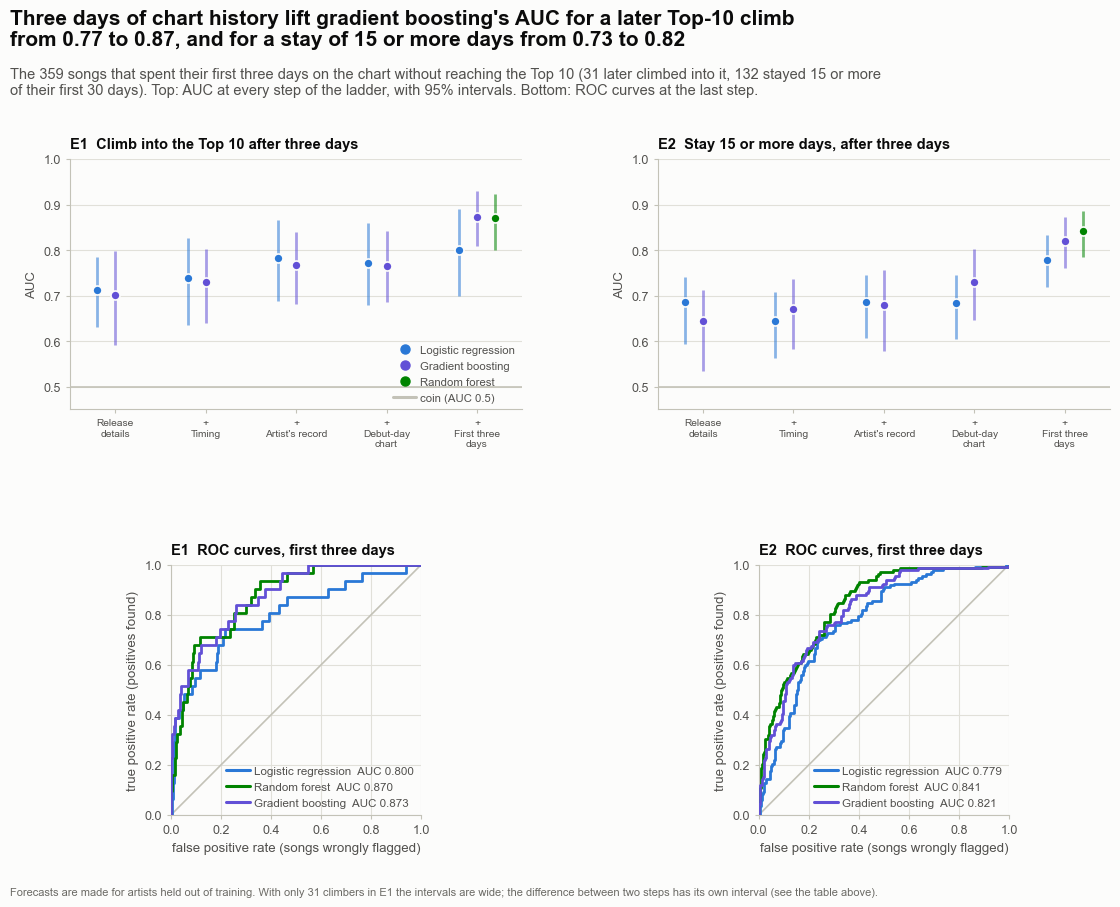

In [20]:
# Figure 10 - E1 and E2: what three days on the chart add
fig, axes = make_fig(11.8, 9.2, 2, 2, left=0.95, right=0.45, bottom=0.8, hspace=0.62, wspace=0.3, panel_titles=True,
                     title=f"Three days of chart history lift gradient boosting's AUC for a later Top-10 climb from {FACTS['e1_debut_boosting_auc']:.2f} to {FACTS['e1_early_boosting_auc']:.2f}, "
                           f"and for a stay of 15 or more days from {FACTS['e2_debut_boosting_auc']:.2f} to {FACTS['e2_early_boosting_auc']:.2f}",
                     subtitle=f"The {FACTS['e1_n']} songs that spent their first three days on the chart without reaching the Top 10 ({FACTS['e1_positives']} later climbed into it, "
                              f"{FACTS['e2_positives']} stayed 15 or more of their first 30 days). Top: AUC at every step of the ladder, with 95% intervals. Bottom: ROC curves at the last step.",
                     note_text="Forecasts are made for artists held out of training. With only 31 climbers in E1 the intervals are wide; the difference between two steps has its own interval (see the table above).")
for column, bench in enumerate((E1, E2)):
    ax_top, ax_bottom = axes[0, column], axes[1, column]
    MP.draw_ladder(ax_top, bench.table, bench.task.steps, ["logistic", "boosting", "forest"], "auc", LADDER_LABELS, MODEL_LABELS, reference=0.5,
                   ylim=(0.45, 1.0), ylabel="AUC", label_last=False)
    ax_top.set_xticklabels([LADDER_LABELS[s].replace("+ ", "+\n").replace(" details", "\ndetails").replace("Debut-day chart", "Debut-day\nchart").replace("First three days", "First three\ndays") for s in bench.task.steps], fontsize=7.4)
    panel_title(ax_top, f"{bench.task.code}  {bench.task.title}")
    curves = []
    for model in ["logistic", "forest", "boosting"]:
        fpr, tpr = M.roc_curve(bench.y, bench.predictions[("early", model)])
        curves.append({"label": f"{MODEL_LABELS[model]}  AUC {bench.score('early', model, 'auc'):.3f}", "fpr": fpr, "tpr": tpr, "color": MP.MODEL_COLORS[model]})
    MP.draw_roc(ax_bottom, curves)
    panel_title(ax_bottom, f"{bench.task.code}  ROC curves, first three days")
MP.ladder_legend(axes[0, 0], ["logistic", "boosting", "forest"], MODEL_LABELS, "coin (AUC 0.5)", loc="lower right", fontsize=8.2)
save_fig(fig, "p6a_10_early", FIG_DIR)
plt.show()

**What to notice**

- Three days of chart history lift gradient boosting's AUC for a later Top-10 climb from 0.77 to 0.87: the gain is +0.105 (interval +0.044 to +0.164). For the straight-line model the gain is only +0.028 (-0.031 to +0.085), which includes zero.
- E1 rests on 31 climbers. The interval of the best score is wide (0.81 to 0.93 for boosting), and boosting is not clearly better than the straight-line model: the difference is +0.073 (-0.013 to +0.158). Average precision at the last step is 0.56 for boosting against 0.09 for a random order.
- For a stay of 15 or more days the gain from the first three days is +0.089 for boosting (+0.038 to +0.148) and +0.095 for the straight-line model (+0.054 to +0.145), both clear. The forest reaches 0.84 and is clearly above the straight line (+0.062, interval +0.031 to +0.097).
- Part of the result is the geography of the chart. A song that sits a few places below the Top 10 on its third day has little distance to cover, and a song that gained places in its first two days is on its way up. Figure 14 shows the shape of this for E1 and E2. These forecasts describe the chart; they do not say why a song moves.
- E1 and E2 cover a different set of songs from C2 and C3, songs that survived three days outside the Top 10. Even release details alone give E1 an AUC of 0.71 (0.63 to 0.78), a level C2 does not reach until the debut day, so the steps of the two ladders should not be compared one for one.

## Section 7 - What goes with the outcomes: odds ratios, coefficients, importance and curves

Until now the notebook asked how well the outcomes can be forecast. This section asks which inputs go with them, and in what way. It uses four tools. Two regressions that can be read directly: odds ratios for the two Top-10 questions and coefficients for the number of chart days. Two ways of questioning a finished gradient-boosting model: permutation importance (which block of inputs does the model lean on?) and partial dependence (what shape of relation did it learn?). All four describe associations among these songs, or what a model does. None of them says what would happen to a song if one of its inputs were changed: that would need a different kind of evidence.

**What this code is.** The explanatory regressions for the two Top-10 questions. For C1 and C2 a logistic regression is fitted on a short list of inputs, each standing for one idea: the song's length, the number of tracks on its release, its chart age at arrival (how many snapshot days of chart history exist before it, up to 90), explicit, collaboration; the artist's days in the Top 10 before, the artist's usual popularity and whether the artist was on the chart the day before; and, for C2 only, the place and the popularity on the debut day (they are not known before the song arrives, so C1 can not have them). Skewed numbers are put on a log scale, every number is put on one scale ("per one standard deviation"), yes-or-no inputs are kept as they are, and a missing value is filled with the median. Where at least 30 songs lack a value a column marks them: that is the case for the artist's usual popularity, and the column is called "no earlier record".

**Why we need it.** The forecasting models of Sections 4 to 6 use every input and, in the case of boosting, have no coefficients to read. To see the direction and size of each association a short, readable regression is better. Its result is an *odds ratio*. The odds of a yes are the chance divided by the chance of a no; an odds ratio of 2 means that the odds are twice as high for a song with one standard deviation more of the input (or for a yes against a no), with the other inputs held fixed; 1 means no association; below 1 means lower odds. The intervals treat all songs of one artist as one cluster, because the songs of an artist are alike (Phase 5), so they count the artists, not the songs, as the independent pieces of evidence.

**What will happen.** The cell builds the inputs with `build_design`, fits the regression with `fit_logit` (and stops if it does not converge), and stores every odds ratio with its 95% interval and p-value. C2 leaves out the 15 songs that have no popularity reading on their debut day: they stayed 1.1 days on the chart on average and none of them climbed, which would make the regression fit them perfectly and fail. The cell checks that none of them climbed. It then prints the two tables.

**Expected outcome.** C1: 894 songs, 222 with a Top-10 debut, 229 artists. C2: 617 songs, 56 that climbed, 212 artists. Odds ratios with intervals; the intervals of C2 are much wider, because only 56 songs climbed.

**Motive.** Show the direction and the size of each association, with an honest interval, and nothing more.

In [21]:
# ---- the inputs of the explanatory regressions: a short list, each one standing for one idea
RELEASE_NUMBERS = {"Song length": ("duration_min", "log1p"), "Tracks on the release": ("total_tracks", "log1p"), "Chart age at arrival": ("history_days", "raw")}
RELEASE_YES_NO = {"Explicit": "is_explicit", "Collaboration": "is_collab"}
ARTIST_NUMBERS = {"Artist: Top-10 days before": ("artist_prior_top10_days", "log1p"), "Artist: usual popularity": ("artist_prior_mean_pop", "raw")}
ARTIST_YES_NO = {"Artist on chart day before": "artist_on_chart_prev_day"}
DEBUT_NUMBERS = {"Debut place": ("entry_rank", "raw"), "Debut popularity": ("entry_pop", "raw")}
NO_RECORD = "Artist: usual popularity (missing)"                     # the extra column that build_design adds for songs whose artist has no earlier chart day
SHORT_NAME = {"Song length": "length", "Tracks on the release": "tracks", "Chart age at arrival": "age", "Explicit": "explicit", "Collaboration": "collab",
              "Artist: Top-10 days before": "top10days", "Artist: usual popularity": "usualpop", NO_RECORD: "norecord",
              "Artist on chart day before": "onchart", "Debut place": "debutplace", "Debut popularity": "debutpop"}
SHOWN_AS = {NO_RECORD: "Artist has no earlier record"}                # how that extra column is called in tables and charts
MIN_MISSING_FOR_FLAG = 30                                             # a "(missing)" column is only added when at least this many songs lack the value


def explanatory_songs(key, needs_debut_reading):
    """The songs of one question. Questions that use the debut-day popularity leave out the few songs without a reading (see the note under the table)."""
    data, y = task_data(TABLE, TASKS[key])
    if needs_debut_reading:
        keep = data["entry_pop"].notna().to_numpy()
        data, y = data[keep].reset_index(drop=True), y[keep]
    return data, y


def odds_ratio_table(key, numbers, yes_no, needs_debut_reading=False):
    """Logistic regression of a yes/no question on the listed inputs, with intervals that treat every artist as one cluster. Returns the table; the numbers go into FACTS."""
    code = TASKS[key].code.lower()
    data, y = explanatory_songs(key, needs_debut_reading)
    design, _ = build_design(data, numbers, yes_no, flag_from=MIN_MISSING_FOR_FLAG)
    fit = fit_logit(y, design.to_numpy(), clusters=data["primary_artist"].to_numpy())
    assert fit.converged, f"the logistic regression for {key} did not converge"
    ratio, low, high = fit.odds_ratios()
    p_value = fit.p_values()
    table = pd.DataFrame({"input": design.columns, "odds_ratio": ratio, "low": low, "high": high, "p_value": p_value}).iloc[1:]      # row 0 is the intercept
    table["input"] = table["input"].map(lambda name: SHOWN_AS.get(name, name))
    FACTS[f"{code}_logit_n"], FACTS[f"{code}_logit_yes"], FACTS[f"{code}_logit_artists"] = len(y), int(y.sum()), int(fit.groups)
    for row, name in zip(table.itertuples(), design.columns[1:]):
        stem = f"{code}_or_{SHORT_NAME[name]}"
        FACTS[stem], FACTS[stem + "_low"], FACTS[stem + "_high"], FACTS[stem + "_p"] = float(row.odds_ratio), float(row.low), float(row.high), float(row.p_value)
    return table


ODDS = {"debut_top10": odds_ratio_table("debut_top10", {**RELEASE_NUMBERS, **ARTIST_NUMBERS}, {**RELEASE_YES_NO, **ARTIST_YES_NO}),
        "climb_top10": odds_ratio_table("climb_top10", {**RELEASE_NUMBERS, **ARTIST_NUMBERS, **DEBUT_NUMBERS}, {**RELEASE_YES_NO, **ARTIST_YES_NO}, needs_debut_reading=True)}
FACTS["unread_songs"] = int(TABLE["entry_pop"].isna().sum())                               # songs without a popularity reading on their debut day (whole table)
FACTS["norecord_songs"] = int(TABLE["artist_prior_mean_pop"].isna().sum())                  # songs whose artist has no earlier popularity reading ...
FACTS["norecord_new_artists"] = int((TABLE["artist_prior_mean_pop"].isna() & (TABLE["artist_prior_slot_days"] == 0)).sum())     # ... and how many of them are artists with no earlier chart day at all
for key, code in [("climb_top10", "c2"), ("chart_days", "r2")]:                            # the songs without a reading, within the songs of each question that is fitted with the debut-day popularity
    rows, outcome = task_data(TABLE, TASKS[key])
    unread = rows["entry_pop"].isna().to_numpy()
    FACTS[f"{code}_unread_songs"] = int(unread.sum())
    FACTS[f"{code}_unread_mean_days"] = float(rows.loc[unread, "chart_days_30"].mean())
    if code == "c2":
        FACTS["c2_unread_climbers"] = int(outcome[unread].sum())
        assert FACTS["c2_unread_climbers"] == 0, "the note under Figure 11 says that none of the songs left out climbed"

for key, table in ODDS.items():
    code = TASKS[key].code
    print(f"{code}  {TASKS[key].title}: {FACTS[code.lower() + '_logit_n']} songs, {FACTS[code.lower() + '_logit_yes']} yes, {FACTS[code.lower() + '_logit_artists']} artists")
    display(pd.DataFrame({"input": table["input"], "odds ratio (95% interval)": [f"{r:.2f}  ({lo:.2f} to {hi:.2f})" for r, lo, hi in zip(table["odds_ratio"], table["low"], table["high"])],
                          "p-value": table["p_value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")}).set_index("input"))

C1  Debut in the Top 10: 894 songs, 222 yes, 229 artists


,odds ratio (95% interval),p-value
input,,
Song length,1.25 (1.10 to 1.41),< 0.001
Tracks on the release,0.80 (0.67 to 0.96),0.014
Chart age at arrival,0.84 (0.67 to 1.05),0.117
Artist: Top-10 days before,1.24 (0.87 to 1.77),0.235
Artist: usual popularity,1.17 (0.85 to 1.63),0.333
Explicit,2.04 (1.51 to 2.77),< 0.001
Collaboration,0.43 (0.22 to 0.83),0.012
Artist on chart day before,1.45 (0.86 to 2.42),0.159
Artist has no earlier record,0.28 (0.13 to 0.60),0.001


C2  Climb into the Top 10 within 30 days: 617 songs, 56 yes, 212 artists


,odds ratio (95% interval),p-value
input,,
Song length,1.02 (0.78 to 1.35),0.879
Tracks on the release,0.88 (0.62 to 1.25),0.482
Chart age at arrival,1.16 (0.86 to 1.58),0.330
Artist: Top-10 days before,0.35 (0.20 to 0.61),< 0.001
Artist: usual popularity,1.46 (0.87 to 2.46),0.152
Debut place,0.59 (0.41 to 0.87),0.008
Debut popularity,1.16 (0.91 to 1.47),0.228
Explicit,0.76 (0.41 to 1.42),0.393
Collaboration,1.22 (0.40 to 3.69),0.728


**What this code is.** Figure 11. A forest plot: one row per input, one dot per odds ratio, and a bar for its 95% interval, on a log scale so that a doubling and a halving look alike. C1 on the left, C2 on the right, the inputs grouped in three blocks (the release, the artist's record, the debut-day chart). A filled dot (blue for higher odds, red for lower) means that the interval does not reach 1; an open dot means that it does.

**Why we need it.** Twenty numbers with intervals are hard to read in a table. The plot shows direction, size and uncertainty at once, and makes it easy to see which associations the data support and which they do not.

**What will happen.** The code takes the two tables of the previous cell, colours every dot by whether its interval excludes 1, draws the dots and bars, writes the odds ratio and interval beside each row, and saves the picture as `p6a_11_odds.png`.

**Expected outcome.** A few filled dots on the left, fewer on the right with much wider bars, and a note that the debut-day inputs are not known before the song arrives.

**Motive.** Make clear which associations are supported by the data and which are not.

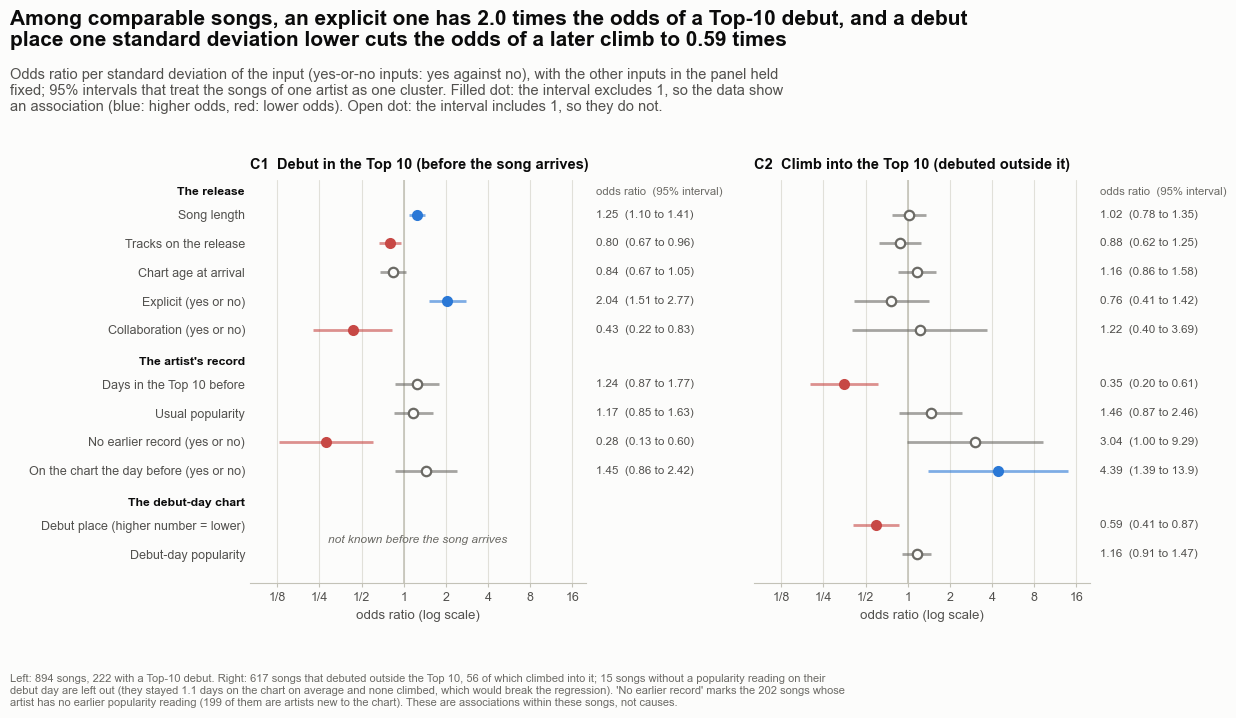

In [22]:
# Figure 11 - which inputs go with a Top-10 debut (C1) and with a later climb (C2)? Odds ratios per standard deviation
FOREST_ROWS = [("The release", ["Song length", "Tracks on the release", "Chart age at arrival", "Explicit", "Collaboration"]),
               ("The artist's record", ["Artist: Top-10 days before", "Artist: usual popularity", SHOWN_AS[NO_RECORD], "Artist on chart day before"]),
               ("The debut-day chart", ["Debut place", "Debut popularity"])]
ROW_LABEL = {"Song length": "Song length", "Tracks on the release": "Tracks on the release", "Chart age at arrival": "Chart age at arrival", "Explicit": "Explicit (yes or no)",
             "Collaboration": "Collaboration (yes or no)", "Artist: Top-10 days before": "Days in the Top 10 before", "Artist: usual popularity": "Usual popularity",
             SHOWN_AS[NO_RECORD]: "No earlier record (yes or no)", "Artist on chart day before": "On the chart the day before (yes or no)",
             "Debut place": "Debut place (higher number = lower)", "Debut popularity": "Debut-day popularity"}
Y_OF, y_now = {}, 0.0
GROUP_TOP = {}
for group, names in FOREST_ROWS:
    GROUP_TOP[group] = y_now
    for name in names:
        Y_OF[name] = y_now
        y_now += 1.0
    y_now += 0.9


def ratio_text(ratio, low, high):
    digits = lambda v: f"{v:.1f}" if v >= 10 else f"{v:.2f}"
    return f"{digits(ratio)}  ({digits(low)} to {digits(high)})"


fig, (ax1, ax2) = make_fig(12.9, 7.3, 1, 2, left=2.75, right=1.75, bottom=0.95, wspace=0.5, panel_titles=True, sharey=True,
                           title=f"Among comparable songs, an explicit one has {FACTS['c1_or_explicit']:.1f} times the odds of a Top-10 debut, and a debut place one standard deviation "
                                 f"lower cuts the odds of a later climb to {FACTS['c2_or_debutplace']:.2f} times",
                           subtitle="Odds ratio per standard deviation of the input (yes-or-no inputs: yes against no), with the other inputs in the panel held fixed; 95% intervals that treat the songs of one artist as one cluster. "
                                    "Filled dot: the interval excludes 1, so the data show an association (blue: higher odds, red: lower odds). Open dot: the interval includes 1, so they do not.",
                           note_text=f"Left: {FACTS['c1_logit_n']} songs, {FACTS['c1_logit_yes']} with a Top-10 debut. Right: {FACTS['c2_logit_n']} songs that debuted outside the Top 10, {FACTS['c2_logit_yes']} of which climbed into it; "
                                     f"{FACTS['c2_unread_songs']} songs without a popularity reading on their debut day are left out (they stayed {FACTS['c2_unread_mean_days']:.1f} days on the chart on average and none climbed, which would break the regression). "
                                     f"'No earlier record' marks the {FACTS['norecord_songs']} songs whose artist has no earlier popularity reading ({FACTS['norecord_new_artists']} of them are artists new to the chart). These are associations within these songs, not causes.")
for ax, key, title in [(ax1, "debut_top10", "C1  Debut in the Top 10 (before the song arrives)"), (ax2, "climb_top10", "C2  Climb into the Top 10 (debuted outside it)")]:
    table = ODDS[key].set_index("input")
    names = [n for n in Y_OF if n in table.index]
    estimates = table.loc[names, "odds_ratio"].to_numpy()
    lows, highs = table.loc[names, "low"].to_numpy(), table.loc[names, "high"].to_numpy()
    colors = [style.MUTED if lo <= 1 <= hi else (style.UP_COLOR if est > 1 else style.DOWN_COLOR) for est, lo, hi in zip(estimates, lows, highs)]
    MP.draw_forest(ax, [Y_OF[n] for n in names], estimates, lows, highs, colors=colors, reference=1.0, log=True,
                   texts=[ratio_text(e, lo, hi) for e, lo, hi in zip(estimates, lows, highs)])
    ax.set_xlim(0.08, 20)
    ax.set_xticks([0.125, 0.25, 0.5, 1, 2, 4, 8, 16])
    ax.set_xticklabels(["1/8", "1/4", "1/2", "1", "2", "4", "8", "16"])
    ax.minorticks_off()
    ax.set_xlabel("odds ratio (log scale)")
    panel_title(ax, title)
    ax.text(1.03, -0.62, "odds ratio  (95% interval)", transform=ax.get_yaxis_transform(), ha="left", va="bottom", fontsize=8.2, color=style.MUTED)
ax1.set_yticks([Y_OF[n] for n in Y_OF])
ax1.set_yticklabels([ROW_LABEL[n] for n in Y_OF], fontsize=9)
ax1.set_ylim(y_now - 0.9, -1.2)
for group, top in GROUP_TOP.items():
    ax1.text(-0.015, top - 0.62, group, transform=ax1.get_yaxis_transform(), ha="right", va="bottom", fontsize=8.8, fontweight="bold", color=style.INK)
ax1.text(0.5, (Y_OF["Debut place"] + Y_OF["Debut popularity"]) / 2, "not known before the song arrives", transform=ax1.get_yaxis_transform(), ha="center", va="center", fontsize=8.6, color=style.MUTED, style="italic")
save_fig(fig, "p6a_11_odds", FIG_DIR)
plt.show()

**What to notice**

- How to read it: for explicit songs, an odds ratio of 2.04 means that the odds of a Top-10 debut are about twice as high as for songs that are not explicit, among songs that are alike in the other inputs. The bar, 1.51 to 2.77, is the 95% interval; it stays well above 1.
- C1, the release: explicit songs have 2.04 times the odds of a Top-10 debut. Collaborations have 0.43 times the odds (0.22 to 0.83). Longer songs go with higher odds (1.25 per standard deviation, 1.10 to 1.41) and songs from bigger releases with lower odds (0.80, 0.67 to 0.96). Phase 5 (H1) asked a related question of all songs, whether an explicit song ever reached the Top 10, without holding anything else fixed. This asks about the debut only, for songs that arrived after day one, with the other inputs held fixed. The two are not the same test.
- C1, the artist's record: one of the four inputs stands out. Songs by an artist with no earlier popularity reading have 0.28 times the odds (0.13 to 0.60). The others are open dots, although the artist's record is the block that carries the forecast (Figure 13). The four overlap: an artist with Top-10 days before is far more often on the chart the day before. With all four in one regression none stands out alone, but a forecast needs the block as a whole.
- C2: among songs that debuted outside the Top 10, a debut place one standard deviation further down the chart goes with 0.59 times the odds of a climb (0.41 to 0.87). An artist with more earlier Top-10 days goes with lower odds (0.35, 0.20 to 0.61) and an artist who was on the chart the day before with higher odds (4.39), with a very wide interval (1.39 to 13.86). One reading of the first, not tested here: every song in C2 debuted outside the Top 10, and for an artist with a big record that may mark a lesser song.
- With only 56 climbers the bars of C2 are wide, and most of its inputs can not be told from 1. These are associations within these songs, not causes: nothing here says that making a song explicit, longer or shorter would change its chances.

**What this code is.** The regressions for the number of chart days (R2). Chart days are fitted three times by ordinary least squares, each time with one more block of inputs: release details; then the artist's record added; then the debut-day chart added. The same 816 songs are used in all three, so that the three can be compared. Each coefficient is the change in chart days (out of 30) for one standard deviation more of the input, or for a yes against a no, with the other inputs of the same regression held fixed; the intervals treat the songs of one artist as one cluster. The cell also works out, for each regression, the share of the spread of chart days that it accounts for in these songs.

**Why we need it.** Adding the blocks one by one shows whether an association survives when more is known about the song. If the coefficient of an input keeps its size from one regression to the next, it is not standing in for the block that was added. The share of the spread that a regression accounts for is measured on the songs the regression was fitted on, so it is *not* a forecasting score: it is the in-sample counterpart of the R-squared of Section 5, which is measured on artists held out of training.

**What will happen.** For each of the three specifications the cell builds the inputs, fits the regression with `fit_ols`, stores every coefficient with its interval and p-value, and stores the share accounted for. Songs without a debut-day popularity reading (16 of them, which stayed 1.1 days on the chart on average) are left out of all three. It prints one table of coefficients with a column per regression and the three shares.

**Expected outcome.** A table with 816 songs and 220 artists, in which some coefficients keep their size from column to column and others change, and three shares that grow from 0.07 to 0.17.

**Motive.** See which associations with chart days are steady and which depend on what else is known.

In [23]:
# ---- chart days (R2) explained by the same kinds of inputs, in three nested regressions: each one adds a block of information
OLS_SPECS = [("release", "Release details", RELEASE_NUMBERS, RELEASE_YES_NO),
             ("artist", "+ Artist's record", {**RELEASE_NUMBERS, **ARTIST_NUMBERS}, {**RELEASE_YES_NO, **ARTIST_YES_NO}),
             ("debut", "+ Debut-day chart", {**RELEASE_NUMBERS, **ARTIST_NUMBERS, **DEBUT_NUMBERS}, {**RELEASE_YES_NO, **ARTIST_YES_NO})]
ols_songs, ols_days = explanatory_songs("chart_days", needs_debut_reading=True)         # the same songs in all three, so that the models can be compared
FACTS["r2_ols_n"], FACTS["r2_ols_artists"] = len(ols_days), int(ols_songs["primary_artist"].nunique())

ols_rows = []
for step, label, numbers, yes_no in OLS_SPECS:
    design, _ = build_design(ols_songs, numbers, yes_no, flag_from=MIN_MISSING_FOR_FLAG)
    fit = fit_ols(ols_days, design.to_numpy(), clusters=ols_songs["primary_artist"].to_numpy())
    FACTS[f"r2_ols_{step}_rsq"] = float(1 - (fit.residuals ** 2).sum() / ((ols_days - ols_days.mean()) ** 2).sum())        # how much of the spread of chart days the fit accounts for, in these songs
    for column, name in enumerate(design.columns):
        if name == "Intercept":
            continue
        test = coefficient_test(fit, column)
        stem = f"r2_ols_{step}_{SHORT_NAME[name]}"
        FACTS[stem], FACTS[stem + "_low"], FACTS[stem + "_high"], FACTS[stem + "_p"] = float(test.estimate), float(test.ci_low), float(test.ci_high), float(test.p_value)
        ols_rows.append({"model": label, "step": step, "input": SHOWN_AS.get(name, name), "days": float(test.estimate), "low": float(test.ci_low), "high": float(test.ci_high), "p_value": float(test.p_value)})
OLS = pd.DataFrame(ols_rows)

print(f"R2  {TASKS['chart_days'].title}: {FACTS['r2_ols_n']} songs, {FACTS['r2_ols_artists']} artists. Change in chart days (of 30) for one standard deviation more of the input; yes-or-no inputs: yes against no.")
shown = OLS.assign(text=[f"{d:+.2f}  ({lo:+.2f} to {hi:+.2f})" for d, lo, hi in zip(OLS["days"], OLS["low"], OLS["high"])]).pivot(index="input", columns="step", values="text")
display(shown.reindex(index=[SHOWN_AS.get(n, n) for n in SHORT_NAME if SHOWN_AS.get(n, n) in set(OLS["input"])], columns=[s for s, *_ in OLS_SPECS]).fillna("").rename(columns={s: l for s, l, *_ in OLS_SPECS}))
print("Share of the spread of chart days that each regression accounts for (in these songs, not on new artists):",
      ",  ".join(f"{l} {FACTS[f'r2_ols_{s}_rsq']:.2f}" for s, l, *_ in OLS_SPECS))

R2  Chart days in the first 30: 816 songs, 220 artists. Change in chart days (of 30) for one standard deviation more of the input; yes-or-no inputs: yes against no.


step,Release details,+ Artist's record,+ Debut-day chart
input,,,
Song length,-0.25 (-1.08 to +0.58),-0.30 (-1.11 to +0.51),-0.81 (-1.63 to +0.01)
Tracks on the release,-2.58 (-3.44 to -1.73),-2.62 (-3.44 to -1.81),-2.54 (-3.32 to -1.76)
Chart age at arrival,+1.19 (+0.09 to +2.29),+1.33 (+0.31 to +2.36),+1.81 (+0.65 to +2.98)
Explicit,+0.45 (-1.35 to +2.26),+1.04 (-0.97 to +3.04),+0.06 (-2.19 to +2.31)
Collaboration,-1.62 (-4.57 to +1.33),-1.64 (-4.69 to +1.40),-1.13 (-4.01 to +1.75)
Artist: Top-10 days before,,+0.14 (-1.47 to +1.75),-0.57 (-2.09 to +0.94)
Artist: usual popularity,,+1.23 (+0.32 to +2.15),+1.12 (+0.18 to +2.07)
Artist has no earlier record,,+2.28 (-1.03 to +5.59),+3.06 (-0.24 to +6.37)
Artist on chart day before,,+1.84 (-0.84 to +4.52),+1.73 (-0.96 to +4.43)


Share of the spread of chart days that each regression accounts for (in these songs, not on new artists): Release details 0.07,  + Artist's record 0.09,  + Debut-day chart 0.17


**What this code is.** Figure 12. The same forest-plot idea for chart days: one row per input, and three dots on each row, one for each of the three regressions, from the lightest blue (release details only) to the darkest (all three blocks). The numbers of the last, fullest regression are written at the right. An open dot means that the interval of that regression reaches 0.

**Why we need it.** The question of this figure is whether the associations change as more is known about the song. Three dots per row, close together or far apart, answer that at a glance.

**What will happen.** The code draws the three sets of dots and bars with a small shift between them so that they do not overlap, writes the numbers of the fullest regression, adds the legend and saves the picture as `p6a_12_ols.png`.

**Expected outcome.** Dots of the three regressions that sit almost on top of each other for some inputs and move for others, and a few rows where the bar of the fullest regression stays away from 0.

**Motive.** Show which associations with chart days are stable.

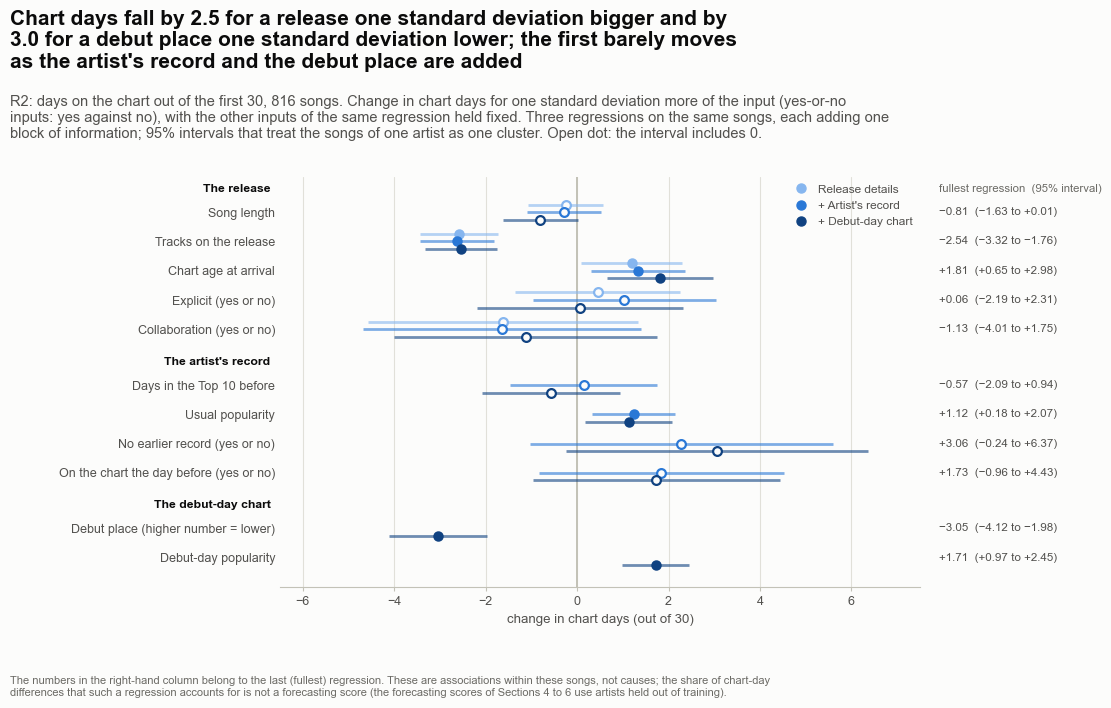

In [24]:
# Figure 12 - which inputs go with the number of chart days (R2), and do they change when more is known about the song?
OLS_COLORS = dict(zip([s for s, *_ in OLS_SPECS], MP.step_colors(3)))
OLS_OFFSET = dict(zip([s for s, *_ in OLS_SPECS], [-0.26, 0.0, 0.26]))
rows_in_order = [name for _, names in FOREST_ROWS for name in names]

fig, ax = make_fig(11.9, 7.2, 1, 1, left=3.05, right=2.45, bottom=0.95,
                   title=f"Chart days fall by {abs(FACTS['r2_ols_debut_tracks']):.1f} for a release one standard deviation bigger and by {abs(FACTS['r2_ols_debut_debutplace']):.1f} "
                         f"for a debut place one standard deviation lower; the first barely moves as the artist's record and the debut place are added",
                   subtitle=f"R2: days on the chart out of the first 30, {FACTS['r2_ols_n']} songs. Change in chart days for one standard deviation more of the input (yes-or-no inputs: yes against no), "
                            "with the other inputs of the same regression held fixed. Three regressions on the same songs, each adding one block of information; 95% intervals that treat the songs of one artist as one cluster. "
                            "Open dot: the interval includes 0.",
                   note_text="The numbers in the right-hand column belong to the last (fullest) regression. These are associations within these songs, not causes; "
                             "the share of chart-day differences that such a regression accounts for is not a forecasting score (the forecasting scores of Sections 4 to 6 use artists held out of training).")
for step, label, *_ in OLS_SPECS:
    part = OLS[OLS["step"] == step].set_index("input")
    names = [n for n in rows_in_order if n in part.index]
    MP.draw_forest(ax, [Y_OF[n] + OLS_OFFSET[step] for n in names], part.loc[names, "days"], part.loc[names, "low"], part.loc[names, "high"],
                   colors=OLS_COLORS[step], reference=0.0, size=40)
    if step == OLS_SPECS[-1][0]:                                                    # the numbers of the fullest regression, level with the row label
        for n in names:
            ax.text(1.03, Y_OF[n], f"{part.loc[n, 'days']:+.2f}  ({part.loc[n, 'low']:+.2f} to {part.loc[n, 'high']:+.2f})".replace("-", "\u2212"), transform=ax.get_yaxis_transform(),
                    ha="left", va="center", fontsize=8.4, color=style.INK_2)
ax.set_xlim(-6.5, 7.5)
ax.set_xlabel("change in chart days (out of 30)")
ax.set_yticks([Y_OF[n] for n in rows_in_order])
ax.set_yticklabels([ROW_LABEL[n] for n in rows_in_order], fontsize=9)
ax.set_ylim(y_now - 0.9, -1.2)
for group, top in GROUP_TOP.items():
    ax.text(-0.015, top - 0.62, group, transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=8.8, fontweight="bold", color=style.INK)
ax.text(1.03, -0.62, "fullest regression  (95% interval)", transform=ax.get_yaxis_transform(), ha="left", va="bottom", fontsize=8.2, color=style.MUTED)
swatch_legend(ax, [(label, OLS_COLORS[step], "dot") for step, label, *_ in OLS_SPECS], loc="upper right", fontsize=8.6)
save_fig(fig, "p6a_12_ols", FIG_DIR)
plt.show()

**What to notice**

- A release with more tracks goes with fewer chart days: -2.54 days for one standard deviation more (interval -3.32 to -1.76). The number hardly changes as blocks are added (-2.58, -2.62, -2.54), so it is not standing in for the artist's record or for the debut-day chart.
- The two debut-day inputs both matter. A debut place one standard deviation lower goes with -3.05 chart days (-4.12 to -1.98), and a higher popularity on the debut day with +1.71 (+0.97 to +2.45).
- The artist's usual popularity goes with +1.12 days (+0.18 to +2.07). Chart age at arrival goes with +1.81 days (+0.65 to +2.98); it counts the snapshot days of history before the song arrived, up to 90, so it separates songs that arrived in the first months of the file from the rest and describes the calendar of the file more than the songs.
- Six inputs of the fullest regression are open dots: song length, explicit, collaboration, the artist's Top-10 days, "no earlier record" and "on the chart the day before". The data do not show an association for them.
- Together the inputs account for a small part of the differences between songs: in these 816 songs the three regressions account for 0.07, 0.09 and 0.17 of the spread of chart days. That share is measured on the songs the regressions were fitted on. The forecasting score for the same question, on artists held out of training, is the R-squared of 0.22 of Figure 9, higher, which suggests that the bends a forest can draw matter (Figure 14). These are associations, not causes.

**What this code is.** Permutation importance for gradient boosting at the last step of every question. The cell goes through the same folds as the main run. In each fold the model is fitted on the training part. The held-out songs' values of one *block* of inputs (release details, timing, the artist's record, the debut-day chart or the first three days, with all the columns of a block shuffled together) are then shuffled among those songs, five times, and the forecasts are scored again. The importance of a block is how far the score falls compared with the intact model, pooled over the folds.

**Why we need it.** Gradient boosting has no coefficients, so the question is put to the finished model: how much worse are your forecasts for songs you have not seen if the information in this block is destroyed? The score is measured on held-out songs, so a block that only helps the model remember the training artists does not look important. Blocks are shuffled instead of single columns because inputs that carry the same information would otherwise protect each other (the model simply uses the twin). The result describes what the *model* leans on, not what drives the outcome.

**What will happen.** For each of the seven questions the cell fits the models of all 5 folds in 3 repeats and scores every shuffle; it is the slowest cell of Section 7. It stores the fall for every block and the score of the intact model, and prints a table: one row per block, one column per question, the fall with its standard deviation over the repeats and scrambles in brackets, and "not known then" where the block does not exist at that question.

**Expected outcome.** A table of five rows and seven columns. In each column where the model has skill, one block (sometimes two) stands out; in the column of R1, where the model has no skill, the numbers are small and mean little.

**Motive.** Ask each finished model what it leans on.

In [25]:
# ---- permutation importance: scramble one BLOCK of inputs among the held-out songs and see how far the score of gradient boosting falls
BLOCKS = {"release": ("Release details", RELEASE_FEATURES), "timing": ("Timing", TIMING_FEATURES), "artist": ("Artist's record", ARTIST_FEATURES),
          "debut": ("Debut-day chart", DEBUT_FEATURES), "early": ("First three days", EARLY_FEATURES)}
SCORE_NAME = {"binary": "AUC", "multiclass": "balanced accuracy", "regression": "R-squared"}


def question_metric(task):
    """(score function of pooled forecasts, kind of forecast, score of knowing nothing) for the main score of a question."""
    if task.kind == "binary":
        return (lambda y, p: M.roc_auc(y, p)), "proba", 0.5
    if task.kind == "multiclass":
        return (lambda y, p: M.matrix_scores(M.confusion_matrix(y, p.argmax(axis=1), p.shape[1]))["balanced_accuracy"]), "proba", 1 / 3
    return (lambda y, p: M.r_squared(y, p)), "value", 0.0


IMPORTANCE_ROWS = []
for key, bench in BENCH.items():
    task, last = bench.task, bench.task.steps[-1]
    columns = feature_set(last, key)
    groups = {name: [c for c in cols if c in columns] for step, (name, cols) in BLOCKS.items() if step in task.steps}
    metric, kind, _ = question_metric(task)
    maker = (lambda: make_regressor("boosting")) if task.kind == "regression" else (lambda: make_classifier("boosting"))
    table = permutation_importance(maker, bench.frame[columns], bench.y, bench.folds, groups, metric, kind=kind, n_permutations=5)
    code = task.code.lower()
    FACTS[f"perm_{code}_intact"] = float(table["intact_score"].iloc[0])
    for step, (name, _) in BLOCKS.items():
        if name in set(table["group"]):
            row = table[table["group"] == name].iloc[0]
            FACTS[f"perm_{code}_{step}"], FACTS[f"perm_{code}_{step}_sd"] = float(row["importance"]), float(row["importance_sd"])
            IMPORTANCE_ROWS.append({"question": task.code, "block": name, "step": step, "importance": float(row["importance"]), "sd": float(row["importance_sd"]),
                                    "intact": float(row["intact_score"]), "score": SCORE_NAME[task.kind]})
IMPORTANCE = pd.DataFrame(IMPORTANCE_ROWS)

shown = IMPORTANCE.assign(text=[f"{v:+.3f}  ({s:.3f})" for v, s in zip(IMPORTANCE["importance"], IMPORTANCE["sd"])]).pivot(index="block", columns="question", values="text")
display(shown.reindex(index=[name for name, _ in BLOCKS.values()], columns=[t.code for t in TASKS.values()]).fillna("not known then"))
print("Fall in the score when the block is scrambled (standard deviation over 3 repeats x 5 scrambles in brackets). Score of the intact model:",
      ",  ".join(f"{t.code} {SCORE_NAME[t.kind]} {FACTS[f'perm_{t.code.lower()}_intact']:.2f}" for t in TASKS.values()))

question,C1,C2,C3,R1,R2,E1,E2
block,,,,,,,
Release details,+0.006 (0.014),-0.024 (0.022),+0.017 (0.014),+0.083 (0.016),+0.099 (0.018),+0.012 (0.015),+0.022 (0.006)
Timing,+0.003 (0.011),+0.053 (0.011),+0.017 (0.006),+0.064 (0.016),+0.034 (0.008),+0.020 (0.014),+0.002 (0.004)
Artist's record,+0.129 (0.026),+0.078 (0.032),+0.022 (0.015),+0.045 (0.024),+0.046 (0.010),+0.089 (0.029),+0.049 (0.019)
Debut-day chart,not known then,+0.082 (0.029),+0.133 (0.018),+0.107 (0.021),+0.330 (0.020),+0.021 (0.014),+0.014 (0.009)
First three days,not known then,not known then,not known then,not known then,not known then,+0.125 (0.024),+0.179 (0.040)


Fall in the score when the block is scrambled (standard deviation over 3 repeats x 5 scrambles in brackets). Score of the intact model: C1 AUC 0.64,  C2 AUC 0.70,  C3 balanced accuracy 0.50,  R1 R-squared 0.01,  R2 R-squared 0.20,  E1 AUC 0.86,  E2 AUC 0.81


**What this code is.** Figure 13. A heat map of the table above: five rows (the blocks), seven columns (the questions), each cell showing the fall in the score when the block is shuffled. The colour is the share of the largest fall in the same column, because the columns are scored in different units (AUC, balanced accuracy, R-squared). Under each column the score of the intact model is written.

**Why we need it.** The table of the previous cell is the evidence, and the heat map makes the pattern visible: which block carries which question.

**What will happen.** The code puts the falls in a grid, shades each cell by its share of the column's largest fall, writes the number in every cell, marks the cells that do not exist (the blocks that are not known at that time of the forecast), flags the column in which the model has no skill (a score within 0.05 of knowing nothing), and saves the picture as `p6a_13_importance.png`.

**Expected outcome.** A dark cell in each column where the model has skill, in a different row for different questions.

**Motive.** Show in one picture where each forecast gets its information from.

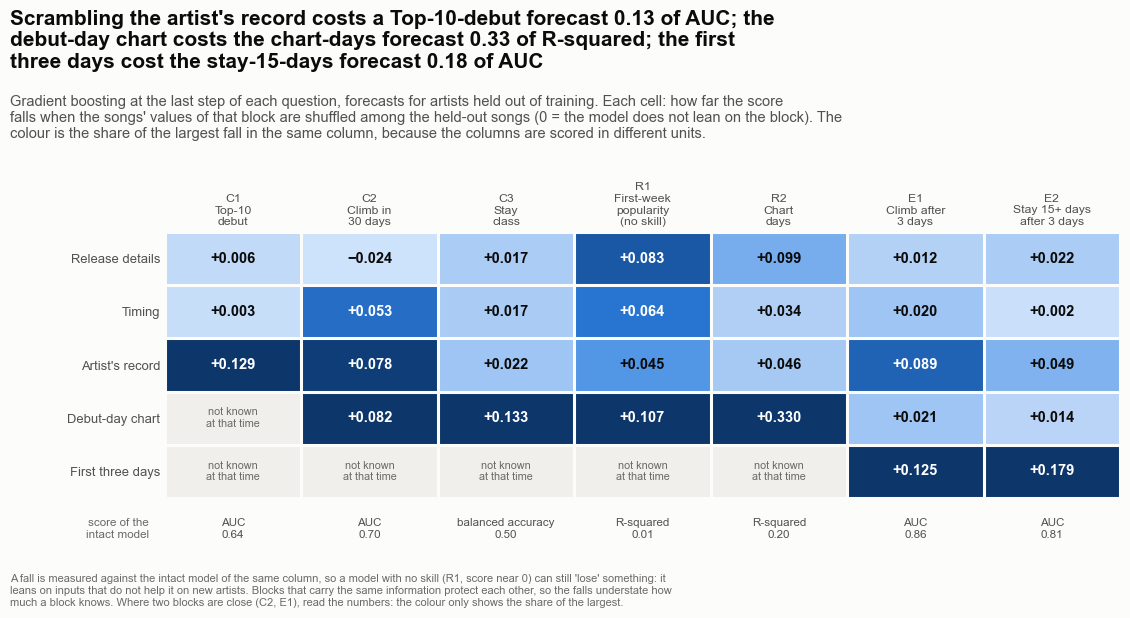

In [26]:
# Figure 13 - which block of information does the model lean on, question by question?
QUESTION_TITLE = {"C1": "Top-10\ndebut", "C2": "Climb in\n30 days", "C3": "Stay\nclass", "R1": "First-week\npopularity", "R2": "Chart\ndays", "E1": "Climb after\n3 days", "E2": "Stay 15+ days\nafter 3 days"}
codes = [t.code for t in TASKS.values()]
block_names = [name for name, _ in BLOCKS.values()]
value = np.full((len(block_names), len(codes)), np.nan)
for row in IMPORTANCE.itertuples():
    value[block_names.index(row.block), codes.index(row.question)] = row.importance
shade = value / np.nanmax(np.where(np.isnan(value), np.nan, np.clip(value, 1e-9, None)), axis=0, keepdims=True)         # share of the largest fall in the same column
shade = np.clip(shade, 0, 1)

fig, ax = make_fig(11.9, 6.3, 1, 1, left=1.9, right=0.45, bottom=0.8, top_extra=0.55,
                   title=f"Scrambling the artist's record costs a Top-10-debut forecast {FACTS['perm_c1_artist']:.2f} of AUC; the debut-day chart costs the chart-days forecast "
                         f"{FACTS['perm_r2_debut']:.2f} of R-squared; the first three days cost the stay-15-days forecast {FACTS['perm_e2_early']:.2f} of AUC",
                   subtitle="Gradient boosting at the last step of each question, forecasts for artists held out of training. Each cell: how far the score falls when the songs' values of that block are shuffled among the held-out songs "
                            "(0 = the model does not lean on the block). The colour is the share of the largest fall in the same column, because the columns are scored in different units.",
                   note_text="A fall is measured against the intact model of the same column, so a model with no skill (R1, score near 0) can still 'lose' something: it leans on inputs that do not help it on new artists. "
                             "Blocks that carry the same information protect each other, so the falls understate how much a block knows. Where two blocks are close (C2, E1), read the numbers: the colour only shows the share of the largest.")
cmap = style.SEQUENTIAL_BLUE.with_extremes(bad=style.NEUTRAL_MID)
image = ax.imshow(np.ma.masked_invalid(shade), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i in range(len(block_names)):
    for j in range(len(codes)):
        if np.isnan(value[i, j]):
            ax.text(j, i, "not known\nat that time", ha="center", va="center", fontsize=7.8, color=style.MUTED)
            continue
        ink = readable_ink(cmap(image.norm(shade[i, j]))[:3], light="white", dark=style.INK)
        ax.text(j, i, f"{value[i, j]:+.3f}".replace("-", "−"), ha="center", va="center", fontsize=10.5, fontweight="bold", color=ink)
ax.set_xticks(range(len(codes)))
NO_SKILL = {t.code: FACTS[f"perm_{t.code.lower()}_intact"] - question_metric(t)[2] < 0.05 for t in TASKS.values()}     # a model that scores within 0.05 of knowing nothing has no skill to lose
ax.set_xticklabels([f"{c}\n{QUESTION_TITLE[c]}" + ("\n(no skill)" if NO_SKILL[c] else "") for c in codes], fontsize=8.8)
ax.xaxis.tick_top()
ax.set_yticks(range(len(block_names)))
ax.set_yticklabels(block_names, fontsize=9.4)
ax.tick_params(length=0)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_xticks(np.arange(-0.5, len(codes), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(block_names), 1), minor=True)
ax.grid(which="minor", color=style.SURFACE, linewidth=2.2)
ax.tick_params(which="minor", length=0)
for j, task in enumerate(TASKS.values()):
    ax.text(j, len(block_names) - 0.5 + 0.38, f"{SCORE_NAME[task.kind]}\n{FACTS[f'perm_{task.code.lower()}_intact']:.2f}", ha="center", va="top", fontsize=8.4, color=style.INK_2, clip_on=False)
ax.text(-0.62, len(block_names) - 0.5 + 0.38, "score of the\nintact model", ha="right", va="top", fontsize=8.4, color=style.MUTED, clip_on=False)
save_fig(fig, "p6a_13_importance", FIG_DIR)
plt.show()

**What to notice**

- Where a model has skill, one block carries most of it. C1: the artist's record (0.127, against 0.007 for release details and 0.005 for timing). C3: the debut-day chart (0.131). R2: the debut-day chart (0.330 of R-squared, far above the 0.101 of release details). E2: the first three days (0.181, against 0.048 for the next block, the artist's record).
- Two columns have two blocks close together. In C2 the artist's record (0.080) and the debut-day chart (0.081) are level, with timing behind (0.052). In E1 the first three days (0.124) lead the artist's record (0.089). The standard deviations of these falls are about 0.033 and 0.024, so the order of two close blocks is not firm.
- R1 has no skill: its intact R-squared is 0.01. The numbers in that column (0.108 for the debut-day chart, 0.086 for release details) show what the model leans on, which does not help it on new artists. A fall is measured against the intact model, and here the intact model is itself about zero.
- Among the questions where the model has skill, release details matter for one only, R2 (0.101), which is consistent with the number of tracks on the release going with chart days in Figure 12. For the Top-10 questions they cost almost nothing when shuffled.
- Blocks that carry the same information protect each other, so these falls understate how much a block knows. The figure shows reliance of the model, on songs of new artists. It does not say that a block causes the outcome.

**What this code is.** Partial dependence for six inputs of gradient boosting. For each input the code sets the input to each of 25 values, from its 5th to its 95th percentile (so that nothing is extrapolated into the thin tails), for all songs, and averages the model's forecast. This is done with each of the 15 models that the cross-validation fitted (5 folds times 3 repeats), so that there is a line for each model.

**Why we need it.** The shape of a relation is what a straight-line model can not show and a boosting model can. Partial dependence draws what the model does when one input changes while the others stay as they are in the data: for instance, how its chance of a climb changes with the place on the debut day. The spread of the 15 lines tells how firmly the shape is established.

**What will happen.** For each of the six inputs the cell refits boosting on the training part of every fold of the question's benchmark (the same folds), calculates the 15 curves, and stores the value at each end of the line and the spread between the lowest and the highest of the 15 models. It prints a small table with one row per input.

**Expected outcome.** A table of six rows: the input, the range that was drawn, the forecast at each end and the spread of the 15 models at the two ends.

**Motive.** Look at the shape of what the models learned, and at how much it is to be trusted.

In [27]:
# ---- partial dependence: the shape of the relationship that gradient boosting learned, from the 15 models of the cross-validation (5 folds x 3 repeats)
PD_PANELS = [
    {"key": "debut_top10", "column": "artist_prior_slot_days", "short": "slot", "title": "C1  The artist's earlier chart days", "xlabel": "chart days the artist already had", "x_scale": "symlog",
     "ylabel": "chance of a Top-10 debut", "percent": True},
    {"key": "debut_top10", "column": "total_tracks", "short": "tracks", "title": "C1  Tracks on the release", "xlabel": "tracks on the release (1 = a single)", "x_scale": None,
     "ylabel": "chance of a Top-10 debut", "percent": True},
    {"key": "climb_top10", "column": "entry_rank", "short": "rank", "title": "C2  Place on the debut day", "xlabel": "place on the debut day (50 = last)", "x_scale": None,
     "ylabel": "chance of a climb into the Top 10", "percent": True},
    {"key": "chart_days", "column": "entry_rank", "short": "rank", "title": "R2  Place on the debut day", "xlabel": "place on the debut day (50 = last)", "x_scale": None,
     "ylabel": "chart days out of 30", "percent": False},
    {"key": "climb_after3", "column": "pos_day2", "short": "pos3", "title": "E1  Place on the third chart day", "xlabel": "place on the third chart day (50 = last)", "x_scale": None,
     "ylabel": "chance of a climb into the Top 10", "percent": True},
    {"key": "sustained_after3", "column": "move_first_3d", "short": "move", "title": "E2  Places gained in the first two days", "xlabel": "places gained between the first and third chart day (negative = fell)", "x_scale": None,
     "ylabel": "chance of 15 or more chart days", "percent": True},
]

FOLD_MODELS = {}                                                          # (question, step) -> the 15 fitted gradient-boosting models and the inputs they were fitted on


def boosting_models_of_the_folds(bench):
    """Fit gradient boosting again on the training part of every fold of the benchmark (the same folds), and keep the 15 fitted models."""
    task, last = bench.task, bench.task.steps[-1]
    X = bench.frame[feature_set(last, task.key)]
    models = []
    for assignment in bench.folds:
        for fold in np.unique(assignment):
            train = np.flatnonzero(assignment != fold)
            model = make_regressor("boosting") if task.kind == "regression" else make_classifier("boosting")
            models.append(model.fit(X.iloc[train], bench.y[train]))
    return models, X


for panel in PD_PANELS:
    bench = BENCH[panel["key"]]
    if panel["key"] not in FOLD_MODELS:
        FOLD_MODELS[panel["key"]] = boosting_models_of_the_folds(bench)
    models, X = FOLD_MODELS[panel["key"]]
    values = X[panel["column"]].dropna().to_numpy()
    panel["grid"] = np.unique(np.quantile(values, np.linspace(0.05, 0.95, 25)))               # from the 5th to the 95th percentile: no extrapolation into the thin tails
    panel["deciles"] = np.quantile(values, np.linspace(0.1, 0.9, 9))
    panel["curves"] = partial_dependence(models, X, panel["column"], panel["grid"], kind="value" if bench.task.kind == "regression" else "proba")
    mean, code = panel["curves"].mean(axis=0), bench.task.code.lower()
    stem = f"pd_{code}_{panel['short']}"
    FACTS[stem + "_x0"], FACTS[stem + "_x1"] = float(panel["grid"][0]), float(panel["grid"][-1])
    FACTS[stem + "_y0"], FACTS[stem + "_y1"] = float(mean[0]), float(mean[-1])
    FACTS[stem + "_spread0"], FACTS[stem + "_spread1"] = float(np.ptp(panel["curves"][:, 0])), float(np.ptp(panel["curves"][:, -1]))     # highest minus lowest of the 15 models at each end
    if panel["percent"]:                                                      # the same numbers in percentage points, for the sentences under the figure
        FACTS[stem + "_change_pts"] = float(100 * (mean[-1] - mean[0]))
        FACTS[stem + "_band0_pts"], FACTS[stem + "_band1_pts"] = float(100 * np.ptp(panel["curves"][:, 0])), float(100 * np.ptp(panel["curves"][:, -1]))

display(pd.DataFrame([{"question": TASKS[p["key"]].code, "input": p["column"], "from": f"{p['grid'][0]:.3g}", "to": f"{p['grid'][-1]:.3g}",
                       "forecast at 'from'": f"{p['curves'].mean(axis=0)[0]:.3f}", "forecast at 'to'": f"{p['curves'].mean(axis=0)[-1]:.3f}",
                       "spread of the 15 models at the two ends": f"{np.ptp(p['curves'][:, 0]):.3f} / {np.ptp(p['curves'][:, -1]):.3f}"} for p in PD_PANELS]).set_index(["question", "input"]))

from        to forecast at 'from' forecast at 'to' spread of the 15 models at the two ends
question input                                                                                                             
C1       artist_prior_slot_days     0  1.14e+03              0.202            0.267                           0.109 / 0.059
         total_tracks               1        27              0.303            0.209                           0.081 / 0.086
C2       entry_rank              12.6        50              0.180            0.065                           0.093 / 0.043
R2       entry_rank                 3        49             18.982            8.179                           4.066 / 1.883
E1       pos_day2                  14        48              0.239            0.058                           0.109 / 0.015
E2       move_first_3d            -22      16.1              0.157            0.523                           0.105 / 0.127

**What this code is.** Figure 14. Six small charts, one for each input: the artist's earlier chart days and the number of tracks on the release (C1), the place on the debut day (C2 and R2), the place on the third chart day (E1) and the places gained in the first two days (E2). Each shows the mean of the 15 models as a line and the lowest and highest of the 15 as a band, with ticks at the bottom for the deciles of the input among the songs.

**Why we need it.** The figure shows which relations have a clear shape (a steep fall, a step) and which are weak and uncertain, which a table of numbers hides.

**What will happen.** The code draws the six panels from the stored curves, with a log-like scale on the horizontal axis of the first panel because the artist's chart days run from 0 to over a thousand, and saves the picture as `p6a_14_partial.png`.

**Expected outcome.** Four panels with a steep, clear shape and two (both C1) that are weak, with a band as wide as the change in the line.

**Motive.** Show what each model learned, and how firmly.

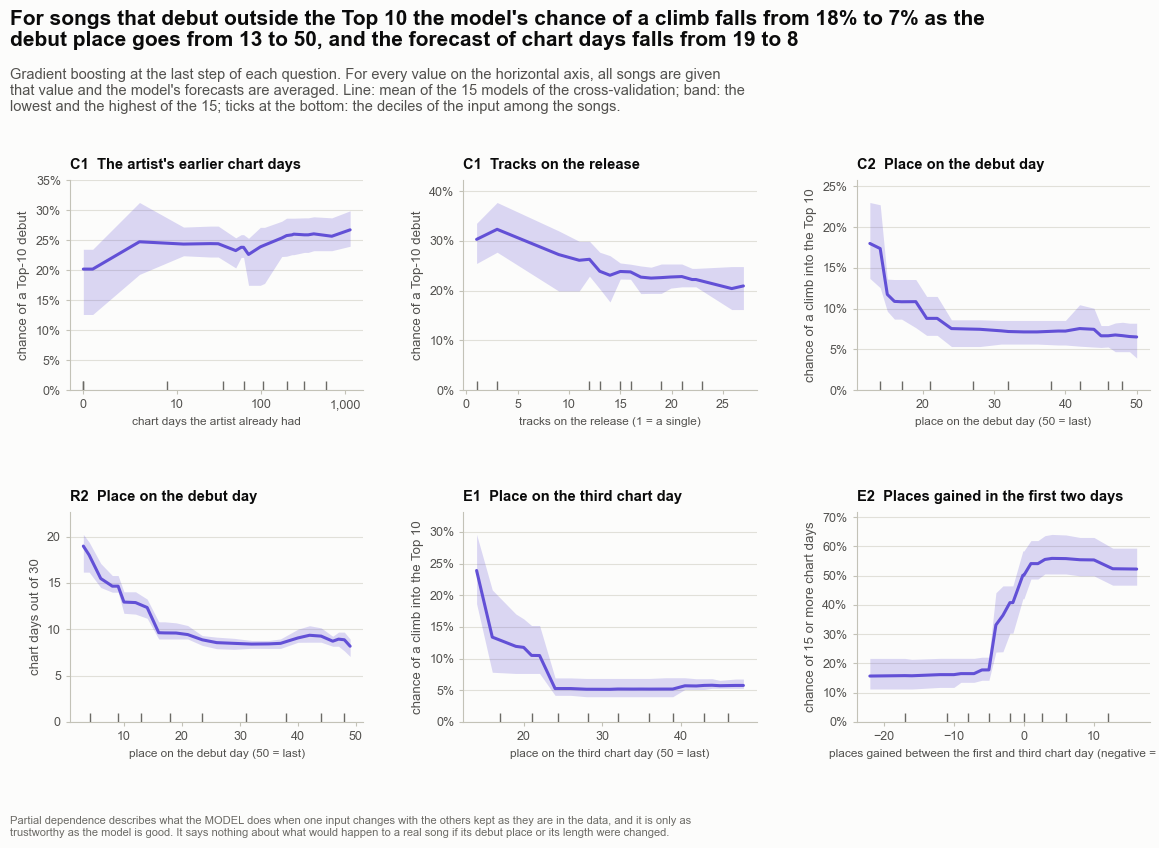

In [28]:
# Figure 14 - the shape of what gradient boosting learned about six inputs
fig, axes = make_fig(12.2, 8.6, 2, 3, left=0.95, right=0.45, bottom=1.0, hspace=0.58, wspace=0.34, panel_titles=True,
                     title=f"For songs that debut outside the Top 10 the model's chance of a climb falls from {FACTS['pd_c2_rank_y0']:.0%} to {FACTS['pd_c2_rank_y1']:.0%} as the debut place goes from "
                           f"{FACTS['pd_c2_rank_x0']:.0f} to {FACTS['pd_c2_rank_x1']:.0f}, and the forecast of chart days falls from {FACTS['pd_r2_rank_y0']:.0f} to {FACTS['pd_r2_rank_y1']:.0f}",
                     subtitle="Gradient boosting at the last step of each question. For every value on the horizontal axis, all songs are given that value and the model's forecasts are averaged. "
                              "Line: mean of the 15 models of the cross-validation; band: the lowest and the highest of the 15; ticks at the bottom: the deciles of the input among the songs.",
                     note_text="Partial dependence describes what the MODEL does when one input changes with the others kept as they are in the data, and it is only as trustworthy as the model is good. "
                               "It says nothing about what would happen to a real song if its debut place or its length were changed.")
for ax, panel in zip(axes.ravel(), PD_PANELS):
    curves = panel["curves"]
    color = MP.MODEL_COLORS["boosting"]
    top = float(curves.max()) * 1.12
    MP.draw_partial(ax, panel["grid"], curves, panel["deciles"], color=color, xlabel=panel["xlabel"], ylabel=panel["ylabel"], as_percent=panel["percent"],
                    x_scale=panel["x_scale"], ylim=(0, top))
    panel_title(ax, panel["title"])
    ax.xaxis.label.set_size(8.6)
save_fig(fig, "p6a_14_partial", FIG_DIR)
plt.show()

**What to notice**

- C2 and R2: the model's chance of a climb and its forecast of chart days fall steeply for songs that debut just outside the Top 10 and are flat for songs that debut in the lower half of the chart. The chance goes from 18% at place 13 to 7% at place 50, and the forecast of chart days from 19 at place 3 to 8 at place 49. A bend like this is something a straight-line model can not draw, which fits the finding that the flexible models beat it for chart days and for the stay class.
- E1: a song at place 14 on its third chart day gets a chance of 24% from the model; the chance falls to 6% at place 48 and is flat in the lower half of the chart. E2: the chance of a stay of 15 or more days goes from 16% at the left end of the axis, for songs that lost places, to 52% at the right end, for songs that gained places, and nearly all of the change happens within a few places either side of zero.
- The two C1 panels are the weak ones. The model's chance of a Top-10 debut changes by +6.4 percentage points from an artist with no earlier chart days to the one with the most, less than the 11 points by which the 15 models disagree at the left end of the line. It changes by -9.4 points from a single to a release of 27 tracks, against a disagreement of 7 and 9 points at the two ends. The shapes are not firm.
- These curves describe what the model does, and they are only as good as the model: the C1 model is modest and the E1 model rests on 31 climbers. They say nothing about what would happen to a real song that moved up the chart.

## Section 8 - Putting a price on the forecasts: gains and break-even

A forecast has no value until it is used, and the most natural use is to decide which songs to look at first. This section asks two questions of the three questions where a rule could act on the forecasts (C1, C2 and E1). If the songs are looked at in the order of the forecast, how many of the songs that really did it sit in the first 10% or 20%? And if looking at a song, or backing it, costs 1 unit and a song that climbs is worth some number of units, at which value would backing the best-forecast songs have paid back? Nobody here knows what a climb is worth: Atlantic does. The section therefore shows a whole range of values. It measures what such a rule would have done on past songs, which is within the brief of historical analytics; it is not a recommendation to back any song.

**What this code is.** The gains table. For C1, C2 and E1 the cell takes the model with the higher AUC at the last step of the ladder, the straight-line model or gradient boosting (chosen on the same songs, so a little flattering), and for every step of the ladder puts the songs in the order of its forecast, highest first. For the first 10% and the first 20% of songs it counts how many songs that really did it (a Top-10 debut or a climb) are among them. It reports three things: the *gain* (the share of all songs that did it which are in that group), the *hit rate* (the share of the songs in the group that did it) and the *lift* (the hit rate divided by the share in all songs, so "how many times better than a random pick").

**Why we need it.** A forecast is useful when there is not enough attention, or money, for all songs, so a choice has to be made: which songs first? Gain and lift answer in counts of songs that anyone can read, and without having to choose a cut-off or to read an AUC. Showing every step of the ladder shows what each kind of knowledge adds to the choice.

**What will happen.** For each question and step the cell flags the best-forecast 10% and 20% of the songs with `top_share_flags`, counts the hits and stores the gain, the hit rate and the lift. It prints one table with a row for every question, step and share.

**Expected outcome.** A table in which the lift rises with the steps of the ladder for C2 and E1 and hardly moves for C1. For the top 10% of C2 at the debut step it shows 63 songs with 16 climbers, and for the top 10% of E1 at the first three days 36 songs with 16 of the 31 climbers.

**Motive.** Say in counts of songs what the ordering of the forecast buys.

In [29]:
# ---- gains: put the songs in the order of the forecast and see how many of the songs that really climbed sit in the first 10% or 20%
DECISION_QUESTIONS = ["debut_top10", "climb_top10", "climb_after3"]
DECISION_MODEL = {}                                                       # the straight-line model or boosting, whichever has the higher AUC at the last step of the question
GAIN_ROWS = []
for key in DECISION_QUESTIONS:
    bench = BENCH[key]
    task, last, code = bench.task, bench.task.steps[-1], bench.task.code.lower()
    DECISION_MODEL[key] = max(["logistic", "boosting"], key=lambda m: bench.score(last, m, "auc"))
    FACTS[f"{code}_decision_model"] = MODEL_LABELS[DECISION_MODEL[key]].lower()
    base_rate = float(bench.y.mean())
    for step in task.steps:
        score = bench.predictions[(step, DECISION_MODEL[key])]
        for share in (0.10, 0.20):
            flagged = M.top_share_flags(score, share)
            hits = int((bench.y.astype(bool) & flagged).sum())
            percent = int(round(100 * share))
            FACTS[f"gain_{code}_{step}_p{percent}"] = hits / float(bench.y.sum())                 # share of ALL positives that sit in the top share of songs
            FACTS[f"prec_{code}_{step}_p{percent}"] = hits / float(flagged.sum())                 # share of the top songs that are positives
            FACTS[f"lift_{code}_{step}_p{percent}"] = hits / float(flagged.sum()) / base_rate     # how many times better than picking at random
            GAIN_ROWS.append({"question": task.code, "step": LADDER_LABELS[step], "model": MODEL_LABELS[DECISION_MODEL[key]], "top": f"{percent}%", "songs": int(flagged.sum()), "positives found": hits,
                              "of all positives": f"{hits / bench.y.sum():.0%}", "lift": f"{hits / flagged.sum() / base_rate:.1f}"})
    FACTS[f"{code}_positives_total"] = int(bench.y.sum())
GAINS = pd.DataFrame(GAIN_ROWS)
display(GAINS.set_index(["question", "step", "top"]))

model  songs  positives found of all positives lift
question step               top                                                                   
C1       Release details    10%  Logistic regression     89               35              16%  1.6
                            20%  Logistic regression    179               71              32%  1.6
         + Timing           10%  Logistic regression     89               34              15%  1.5
                            20%  Logistic regression    179               66              30%  1.5
         + Artist's record  10%  Logistic regression     89               38              17%  1.7
                            20%  Logistic regression    179               67              30%  1.5
C2       Release details    10%    Gradient boosting     63                5               9%  0.9
                            20%    Gradient boosting    126                9              16%  0.8
         + Timing           10%    Gradient boosting     63                9              16%  1.6
                            20%    Gradient boosting    126               14              25%  1.3
         + Artist's record  10%    Gradient boosting     63               10              18%  1.8
                            20%    Gradient boosting    126               15              27%  1.3
         + Debut-day chart  10%    Gradient boosting     63               16              29%  2.9
                            20%    Gradient boosting    126               23              41%  2.1
E1       Release details    10%    Gradient boosting     36                7              23%  2.3
                            20%    Gradient boosting     72               13              42%  2.1
         + Timing           10%    Gradient boosting     36                7              23%  2.3
                            20%    Gradient boosting     72               13              42%  2.1
         + Artist's record  10%    Gradient boosting     36               10              32%  3.2
                            20%    Gradient boosting     72               15              48%  2.4
         + Debut-day chart  10%    Gradient boosting     36               11              35%  3.5
                            20%    Gradient boosting     72               14              45%  2.3
         + First three days 10%    Gradient boosting     36               16              52%  5.1
                            20%    Gradient boosting     72               21              68%  3.4

**What this code is.** Figure 15. One panel for each of C1, C2 and E1, with one curve for every step of the ladder (each step always has the same blue). The horizontal axis is the share of songs looked at, highest forecast first; the vertical axis is the share of all songs that really did it which are among them. The grey diagonal is a random order, the pale line the best possible order (every song that did it comes first), and a vertical line marks the first 10%.

**Why we need it.** The table gives two points of each curve, at 10% and 20%. The picture gives the whole curve, shows how much each step of the ladder lifts it, and shows how steppy the curves are when only a few songs stand behind them.

**What will happen.** The code calculates the gains curve of every step with `M.gains_table`, draws the three panels, and saves the picture as `p6a_15_gains.png`.

**Expected outcome.** Curves above the diagonal and far below the best possible line. In C2 and E1 the curve of the last step of the ladder is the highest over the first part of the list; in C1 the three curves lie close together.

**Motive.** Show how much of what happened can be found by looking at the best-forecast songs first.

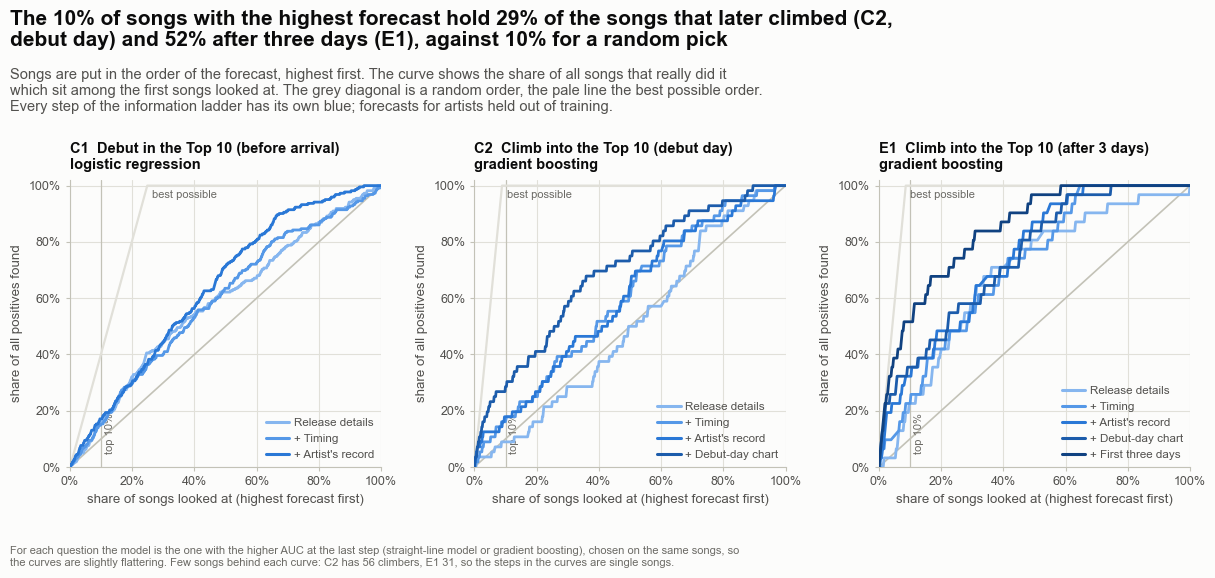

In [30]:
# Figure 15 - gains: how many of the songs that really climbed are found by looking at the best-forecast songs first
STEP_COLOR = dict(zip(LADDER, MP.step_colors(5)))                         # a step of the ladder has the same blue in every chart
GAIN_TITLES = {"debut_top10": "C1  Debut in the Top 10 (before arrival)", "climb_top10": "C2  Climb into the Top 10 (debut day)", "climb_after3": "E1  Climb into the Top 10 (after 3 days)"}

fig, axes = make_fig(12.6, 5.9, 1, 3, left=0.95, right=0.45, bottom=0.85, wspace=0.3, panel_titles=True,
                     title=f"The 10% of songs with the highest forecast hold {FACTS['gain_c2_debut_p10']:.0%} of the songs that later climbed (C2, debut day) and "
                           f"{FACTS['gain_e1_early_p10']:.0%} after three days (E1), against 10% for a random pick",
                     subtitle="Songs are put in the order of the forecast, highest first. The curve shows the share of all songs that really did it which sit among the first songs looked at. "
                              "The grey diagonal is a random order, the pale line the best possible order. Every step of the information ladder has its own blue; forecasts for artists held out of training.",
                     note_text="For each question the model is the one with the higher AUC at the last step (straight-line model or gradient boosting), chosen on the same songs, so the curves are slightly flattering. "
                               f"Few songs behind each curve: C2 has {FACTS['c2_positives']} climbers, E1 {FACTS['e1_positives']}, so the steps in the curves are single songs.")
for ax, key in zip(axes, DECISION_QUESTIONS):
    bench, model = BENCH[key], DECISION_MODEL[key]
    curves = []
    for step in bench.task.steps:
        table = M.gains_table(bench.y, bench.predictions[(step, model)])
        curves.append({"label": LADDER_LABELS[step], "share": table["share_flagged"], "gain": table["gain"], "color": STEP_COLOR[step]})
    MP.draw_gains(ax, curves, float(bench.y.mean()), legend_loc="lower right", mark_share=0.10)
    panel_title(ax, f"{GAIN_TITLES[key]}\n{MODEL_LABELS[model].lower()}")
save_fig(fig, "p6a_15_gains", FIG_DIR)
plt.show()

**What to notice**

- Looking first at the 10% of songs with the highest forecast finds 29% of the songs that later climbed in C2 (16 of 56, among 63 songs, a lift of 2.9) and 52% in E1 (16 of 31, among 36 songs, a lift of 5.1). A random order would find 10%.
- Each step of the ladder matters. In C2 the forecast from release details alone finds 11% in its top 10%, no better than a random pick, and the debut-day chart brings it to 29%. In E1 the figures run from 19% (release details) to 52% (the first three days).
- C1 is the weakest: the top 10% of songs, ranked before they arrive, hold 17% of the Top-10 debuts and the top 20% hold 30%, a lift of 1.7 in the top 10%. As the AUC said, before a song arrives the order is only a little better than a random one, and the three steps of its ladder are hard to tell apart.
- Few songs stand behind each curve (56 climbers in C2, 31 in E1), so each upward step of a curve is a single song, and one more or one fewer in the top 10% changes the share noticeably. The model of each panel was chosen on these same songs, so the curves are slightly flattering.

**What this code is.** The break-even table. Promoting one song costs 1 unit; a promoted song that then climbs into the Top 10 is worth `ratio` units. The return per unit spent is the ratio times the hit rate, minus 1, and the rule pays back when that is above zero, that is, when the ratio is above 1 divided by the hit rate: the *break-even value*. Nobody here knows the real ratio, so the cell works it out for a whole grid: eight ratios (from 2 to 24) and seven shares of songs promoted (from 5% to 50%, always the best-forecast songs first), for C2 on the debut day and E1 after three days.

**Why we need it.** Whether a forecast rule pays does not depend on the forecast alone. It depends on what a hit is worth against what it costs to chase it, which is a business fact. Showing the whole grid, and the one number that summarises it (the break-even value), lets a reader put the real value in. A random pick has a break-even value of 1 divided by the base rate, about 11 promotions for C2, so the forecasts are worth something where the break-even value of the rule is much lower.

**What will happen.** For each of the two questions the cell calculates the grid with `M.decision_table`, stores the numbers for the best 10% (songs promoted, hits, hit rate, break-even value and the return at ratios 4, 8 and 12) and the number of grid cells that pay back, and prints two tables: the grid of returns, and for each share promoted the hit rate and the break-even value.

**Expected outcome.** For C2, the best 10% means 63 songs with 16 hits and a break-even value of 3.9 promotions; for E1, 36 songs with 16 hits and a break-even value of 2.2.

**Motive.** Put the forecasts on a scale that a business can read, without pretending to know its numbers.

In [31]:
# ---- break-even: what a promotion rule that backs the best-forecast songs would have returned on the songs of the past
# Promoting one song costs 1 unit. A promoted song that then climbs is worth `ratio` units. We do not know the real ratio, so a whole range is shown.
VALUE_RATIOS = [2, 3, 4, 6, 8, 12, 16, 24]
SHARES_PROMOTED = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
DECISIONS = {}
for key in ["climb_top10", "climb_after3"]:
    bench = BENCH[key]
    last, code, model = bench.task.steps[-1], bench.task.code.lower(), DECISION_MODEL[key]
    table = M.decision_table(bench.y, bench.predictions[(last, model)], VALUE_RATIOS, SHARES_PROMOTED)
    DECISIONS[key] = table
    base_rate = float(bench.y.mean())
    FACTS[f"{code}_random_break_even"] = 1 / base_rate                        # promoting at random pays back only if a climb is worth this many promotions
    top = table[(table["share_promoted"] == 0.10) & (table["value_ratio"] == VALUE_RATIOS[0])].iloc[0]
    FACTS[f"{code}_p10_promoted"], FACTS[f"{code}_p10_hits"] = int(top["promoted"]), int(top["hits"])
    FACTS[f"{code}_p10_precision"] = float(top["precision"])
    FACTS[f"{code}_p10_break_even"] = 1 / float(top["precision"])                              # the value of a climb, in promotions, at which the top 10% just pays back
    for ratio in (4, 8, 12):
        row = table[(table["share_promoted"] == 0.10) & (table["value_ratio"] == ratio)].iloc[0]
        FACTS[f"{code}_roi_p10_r{ratio}"] = float(row["roi"])
    FACTS[f"{code}_pays_cells"] = int((table["roi"] > 0).sum())               # how many of the grid cells pay back
    FACTS[f"{code}_grid_cells"] = len(table)
    wide = table.pivot(index="share_promoted", columns="value_ratio", values="roi")
    print(f"{bench.task.code}  {bench.task.title}: {MODEL_LABELS[model].lower()} at the last step ({LADDER_LABELS[last].lstrip('+ ').lower()}), {len(bench.y)} songs, {int(bench.y.sum())} climbed ({base_rate:.1%}).")
    display(wide.rename(index=lambda s: f"{s:.0%} promoted", columns=lambda r: f"worth {r:g}").map(lambda v: f"{v:+.2f}"))
    detail = table[table["value_ratio"] == VALUE_RATIOS[0]][["share_promoted", "promoted", "hits", "precision", "break_even"]].copy()
    detail["break_even"] = 1 / detail["precision"]
    detail = detail.rename(columns={"share_promoted": "share promoted", "precision": "hit rate", "break_even": "pays back when a climb is worth more than"})
    detail["share promoted"] = detail["share promoted"].map("{:.0%}".format)
    detail["hit rate"] = detail["hit rate"].map("{:.0%}".format)
    detail["pays back when a climb is worth more than"] = detail["pays back when a climb is worth more than"].map("{:.1f} promotions".format)
    display(detail.set_index("share promoted"))

C2  Climb into the Top 10 within 30 days: gradient boosting at the last step (debut-day chart), 632 songs, 56 climbed (8.9%).


value_ratio,worth 2,worth 3,worth 4,worth 6,worth 8,worth 12,worth 16,worth 24
share_promoted,,,,,,,,
5% promoted,-0.19,+0.22,+0.62,+1.44,+2.25,+3.88,+5.50,+8.75
10% promoted,-0.49,-0.24,+0.02,+0.52,+1.03,+2.05,+3.06,+5.10
15% promoted,-0.58,-0.37,-0.16,+0.26,+0.68,+1.53,+2.37,+4.05
20% promoted,-0.63,-0.45,-0.27,+0.10,+0.46,+1.19,+1.92,+3.38
30% promoted,-0.66,-0.49,-0.33,+0.01,+0.35,+1.02,+1.69,+3.04
40% promoted,-0.69,-0.54,-0.38,-0.08,+0.23,+0.85,+1.47,+2.70
50% promoted,-0.73,-0.60,-0.47,-0.20,+0.06,+0.59,+1.13,+2.19


,promoted,hits,hit rate,pays back when a climb is worth more than
share promoted,,,,
5%,32,13,41%,2.5 promotions
10%,63,16,25%,3.9 promotions
15%,95,20,21%,4.8 promotions
20%,126,23,18%,5.5 promotions
30%,190,32,17%,5.9 promotions
40%,253,39,15%,6.5 promotions
50%,316,42,13%,7.5 promotions


E1  Climb into the Top 10 after three days: gradient boosting at the last step (first three days), 359 songs, 31 climbed (8.6%).


value_ratio,worth 2,worth 3,worth 4,worth 6,worth 8,worth 12,worth 16,worth 24
share_promoted,,,,,,,,
5% promoted,+0.33,+1.00,+1.67,+3.00,+4.33,+7.00,+9.67,+15.00
10% promoted,-0.11,+0.33,+0.78,+1.67,+2.56,+4.33,+6.11,+9.67
15% promoted,-0.30,+0.06,+0.41,+1.11,+1.81,+3.22,+4.63,+7.44
20% promoted,-0.42,-0.12,+0.17,+0.75,+1.33,+2.50,+3.67,+6.00
30% promoted,-0.56,-0.33,-0.11,+0.33,+0.78,+1.67,+2.56,+4.33
40% promoted,-0.62,-0.44,-0.25,+0.12,+0.50,+1.25,+2.00,+3.50
50% promoted,-0.67,-0.50,-0.33,+0.00,+0.33,+1.00,+1.67,+3.00


,promoted,hits,hit rate,pays back when a climb is worth more than
share promoted,,,,
5%,18,12,67%,1.5 promotions
10%,36,16,44%,2.2 promotions
15%,54,19,35%,2.8 promotions
20%,72,21,29%,3.4 promotions
30%,108,24,22%,4.5 promotions
40%,144,27,19%,5.3 promotions
50%,180,30,17%,6.0 promotions


**What this code is.** Figure 16. One heat map for each of the two questions. Down: the share of songs promoted (the best-forecast songs first). Across: what a hit is worth, in promotion costs. Each cell is the return per unit spent, with the number written in it. Blue means the money comes back, red that it does not, and a black line marks break-even.

**Why we need it.** The grid of numbers is the evidence; the map shows at a glance where the rule pays and where it does not, and how that changes as more songs are promoted or as a hit becomes worth more.

**What will happen.** The code draws the two maps with the same colour scale, which stops getting deeper at +1.5 while the numbers stay exact, draws the break-even line, adds a colour bar and saves the picture as `p6a_16_roi.png`.

**Expected outcome.** Red in the top left, blue in the bottom right, and a break-even line that runs from the lower left to the upper right, further to the left for E1 than for C2.

**Motive.** Show where the forecasts would have paid back on past songs, for every value of a hit that Atlantic might put in.

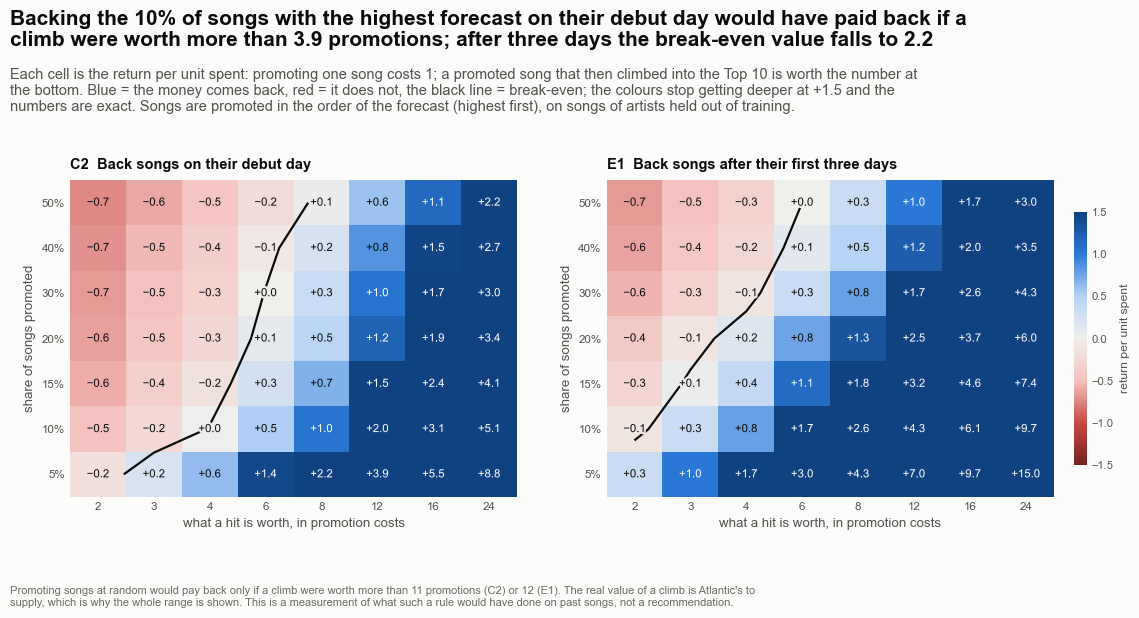

In [32]:
# Figure 16 - the break-even map: what backing the best-forecast songs would have returned, for every share promoted and every value of a climb
ROI_TITLES = {"climb_top10": "C2  Back songs on their debut day", "climb_after3": "E1  Back songs after their first three days"}
fig, axes = make_fig(12.4, 6.3, 1, 2, left=0.95, right=1.15, bottom=0.95, wspace=0.2, panel_titles=True,
                     title=f"Backing the 10% of songs with the highest forecast on their debut day would have paid back if a climb were worth more than {FACTS['c2_p10_break_even']:.1f} promotions; "
                           f"after three days the break-even value falls to {FACTS['e1_p10_break_even']:.1f}",
                     subtitle="Each cell is the return per unit spent: promoting one song costs 1; a promoted song that then climbed into the Top 10 is worth the number at the bottom. Blue = the money comes back, red = it does not, "
                              "the black line = break-even; the colours stop getting deeper at +1.5 and the numbers are exact. Songs are promoted in the order of the forecast (highest first), on songs of artists held out of training.",
                     note_text=f"Promoting songs at random would pay back only if a climb were worth more than {FACTS['c2_random_break_even']:.0f} promotions (C2) or {FACTS['e1_random_break_even']:.0f} (E1). "
                               "The real value of a climb is Atlantic's to supply, which is why the whole range is shown. This is a measurement of what such a rule would have done on past songs, not a recommendation.")
vmax = 1.5                                                                  # the colours stop getting deeper at a return of 1.5 (a loss can never be worse than -1); the numbers in the cells are exact
for ax, key in zip(axes, DECISIONS):
    wide = DECISIONS[key].pivot(index="share_promoted", columns="value_ratio", values="roi")
    mesh = MP.draw_roi_map(ax, wide.index.to_numpy(), wide.columns.to_numpy(), wide.to_numpy(), vmax=vmax, annotate=True)
    panel_title(ax, ROI_TITLES[key])
cbar = fig.colorbar(mesh, ax=list(axes), fraction=0.025, pad=0.02, shrink=0.8)
cbar.set_label("return per unit spent", fontsize=8.8, color=style.INK_2)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=8, length=0)
save_fig(fig, "p6a_16_roi", FIG_DIR)
plt.show()

**What to notice**

- Break-even for the best 10% of songs. On the debut day (C2) the 63 best-forecast songs include 16 climbers, a hit rate of 25%, so the rule pays back if a climb is worth more than 3.9 promotions. After three days (E1) the 36 songs include 16 climbers, a hit rate of 44%, and the break-even value is 2.2.
- A worked example. If a climb were worth 8 promotions, backing the best 10% would have returned +1.03 per unit spent in C2 and +2.56 in E1. At 4 it would have returned +0.02 in C2, which is break-even, and +0.78 in E1.
- Promoting songs at random would pay back only if a climb were worth more than 11 promotions (C2) or 12 (E1). The forecasts bring that value down to 3.9 and 2.2 for the best 10%. Backing fewer songs, the ones the model is surest of, pays back at a lower value; the more songs are added, the more the hit rate falls towards the base rate and the more the break-even line moves to the right.
- 36 of the 56 cells of the C2 map pay back and 42 of 56 for E1, but the grid is only a range of values that nobody here has supplied. The break-even rests on 16 climbers in C2 and 16 in E1: one climber more or fewer in the best 10% moves it noticeably.
- The real value of a climb is Atlantic's to supply. This is a measurement of what such a rule would have done on past songs, not a recommendation to promote any song.

## Section 9 - Stress tests: other splits, other settings, without the biggest artist, forward in time

A result that holds only for one split, one setting or one artist is fragile. The main results of three questions (C1 at the artist step, C2 at the debut step and E2 at the first three days, each with the straight-line model and with gradient boosting) are therefore put through four changes of the test, one at a time: four other ways of dealing the artists into five parts; leaving out the artist with the most songs; other settings of the models; and scoring forward in time, on songs that arrived after the models were trained. E2 stands for the early-warning questions, because E1 has too few climbers to be cut by time.

**What this code is.** The stress tests. For each of the three questions and each of the two models the cell runs four things. (1) The benchmark again with four other deals of the artists into five parts (a score is all that is needed, so 50 draws of artists are enough). (2) The benchmark again without the 92 songs of Taylor Swift, the artist with the most songs. (3) The same forecasts with other settings of the model: the straight-line model with a penalty ten times stronger and ten times weaker, boosting with shallower trees (depth 2), deeper trees (depth 4) and faster learning (rate 0.1, 75 rounds). (4) A forward-in-time test: the models are trained on songs that arrived before day 220 of the file and scored on songs that arrived from day 250 on; the 30 days in between are left out, so that no outcome of a training song reaches into the test period. To have something fair to compare with, the cell also scores the same later songs with the forecasts that the notebook had already made for them.

**Why we need it.** Each test changes one thing that the main run held fixed. Other splits and other settings show whether the scores are an accident of one choice. Leaving out the biggest artist shows whether the results are the story of one artist. The forward test is the closest this notebook gets to the real use of a model: learn from the past, meet songs that arrive later. It is harsher in two ways at once, because it uses only about half of the songs for training and because the later songs may behave differently from the earlier ones. The comparison with the notebook's own forecasts for the same later songs separates the effect of choosing the later songs from the effect of the test itself.

**What will happen.** The cell runs all the tests (about a minute and a half on the computer where it was tested), stores every score with its interval in `FACTS`, works out how far each kind of change moved the score at most, and prints one table with a row for each question and model and a column for each test.

**Expected outcome.** A table of six rows. Other splits and other settings stay within a few hundredths of the notebook's own score. Leaving out Taylor Swift raises the score in 6 of the six rows, by at most 0.031. The forward-in-time column is the one that differs; a last line gives the number of later songs, and of later yes answers, for each question.

**Motive.** See whether the main results survive a harder or a different test.

In [33]:
# ---- stress tests: does the main result of three questions survive a harder or a different test? (the straight-line model and gradient boosting, each at the last step)
STRESS = [("debut_top10", "artist"), ("climb_top10", "debut"), ("sustained_after3", "early")]
STRESS_MODELS = ["logistic", "boosting"]
OTHER_SEEDS = [1, 2, 3, 4]                                                # four other ways of dealing the artists into five parts
BIGGEST_ARTIST = TABLE["primary_artist"].value_counts().index[0]          # the artist with the most songs in the table
FORWARD_CUTOFF, FORWARD_GAP = 250, 30                                     # train on songs that arrived before day 220, test on songs that arrived from day 250 on
SETTINGS = {"logistic": {"strong penalty (C = 0.05)": dict(logistic_c=0.05), "weak penalty (C = 5)": dict(logistic_c=5.0)},
            "boosting": {"shallower trees (depth 2)": dict(boosting={"max_depth": 2}), "deeper trees (depth 4)": dict(boosting={"max_depth": 4}),
                         "faster learning (rate 0.1, 75 rounds)": dict(boosting={"learning_rate": 0.1, "max_iter": 75})}}
FACTS["stress_biggest_artist"] = BIGGEST_ARTIST
FACTS["stress_biggest_songs"] = int((TABLE["primary_artist"] == BIGGEST_ARTIST).sum())
FACTS["stress_cutoff"], FACTS["stress_gap"] = FORWARD_CUTOFF, FORWARD_GAP
FACTS["stress_train_before"] = FORWARD_CUTOFF - FORWARD_GAP

STRESS_RESULTS = {}                                                       # (question, model) -> everything the figure draws
started = time.time()
for key, step in STRESS:
    bench, code = BENCH[key], BENCH[key].task.code.lower()
    other_splits = {s: run_benchmark(TABLE, key, plan={step: STRESS_MODELS}, n_splits=N_SPLITS, n_repeats=N_REPEATS, n_boot=50, fold_seed=s).table for s in OTHER_SEEDS}
    without = run_benchmark(TABLE, key, plan={step: STRESS_MODELS}, n_splits=N_SPLITS, n_repeats=N_REPEATS, n_boot=N_BOOT, exclude_artists=[BIGGEST_ARTIST])
    forward = run_forward(TABLE, key, FORWARD_CUTOFF, FORWARD_GAP, plan={step: STRESS_MODELS}, n_boot=N_BOOT)
    later = (bench.frame["entry_snapshot"] >= FORWARD_CUTOFF).to_numpy()
    FACTS[f"stress_{code}_later_songs"], FACTS[f"stress_{code}_later_yes"] = int(later.sum()), int(bench.y[later].sum())
    FACTS[f"stress_{code}_train_songs"] = int(forward["n_train"].iloc[0])
    FACTS[f"stress_{code}_without_songs"] = int(without.table["n"].iloc[0])
    for model in STRESS_MODELS:
        stem = f"stress_{code}_{model}"
        own = (bench.score(step, model, "auc"), *bench.interval(step, model, "auc"))
        seeds = [float(t[t["model"] == model]["auc"].iloc[0]) for t in other_splits.values()]
        left_out = without.table[without.table["model"] == model].iloc[0]
        variants = {}
        for label, options in SETTINGS[model].items():
            make = (lambda o=options: make_classifier(model, **o))
            variants[label] = score_variant(bench, step, make)[0]
        ahead = forward[forward["model"] == model].iloc[0]
        same_later = score_rows(bench, (step, model), later, n_boot=N_BOOT, metric_set=["auc"])["auc"]
        STRESS_RESULTS[(key, model)] = {"own": own, "seeds": seeds, "without": (float(left_out["auc"]), float(left_out["auc_low"]), float(left_out["auc_high"])), "variants": variants,
                                        "forward": (float(ahead["auc"]), float(ahead["auc_low"]), float(ahead["auc_high"])), "same_later": same_later}
        FACTS[stem + "_own"] = own[0]
        FACTS[stem + "_seeds_min"], FACTS[stem + "_seeds_max"] = min(seeds), max(seeds)
        FACTS[stem + "_without"], FACTS[stem + "_without_low"], FACTS[stem + "_without_high"] = STRESS_RESULTS[(key, model)]["without"]
        FACTS[stem + "_settings_min"], FACTS[stem + "_settings_max"] = min(variants.values()), max(variants.values())
        FACTS[stem + "_forward"], FACTS[stem + "_forward_low"], FACTS[stem + "_forward_high"] = STRESS_RESULTS[(key, model)]["forward"]
        FACTS[stem + "_same_later"], FACTS[stem + "_same_later_low"], FACTS[stem + "_same_later_high"] = same_later
print(f"stress tests done in {time.time() - started:.0f} s")

# ---- how far did each kind of change move the score, at most? (for the headline), and how much lower is the forward-in-time score than the notebook's own forecasts for the same later songs?
FACTS["stress_seeds_max_shift"] = max(abs(v - r["own"][0]) for r in STRESS_RESULTS.values() for v in r["seeds"])
FACTS["stress_settings_max_shift"] = max(abs(v - r["own"][0]) for r in STRESS_RESULTS.values() for v in r["variants"].values())
FACTS["stress_without_max_shift"] = max(abs(r["without"][0] - r["own"][0]) for r in STRESS_RESULTS.values())
_rise = [r["without"][0] - r["own"][0] for r in STRESS_RESULTS.values()]                                # change of the AUC when the biggest artist is left out (positive = the score ROSE)
FACTS["stress_without_higher"] = int(sum(v > 0 for v in _rise))                                         # in how many of the six cases the score rose
FACTS["stress_without_smallest_rise"] = float(min(_rise))                                              # the smallest change; quoted as a rise only when all six rose
FACTS["stress_max_shift"] = max(FACTS["stress_seeds_max_shift"], FACTS["stress_settings_max_shift"], FACTS["stress_without_max_shift"])
for key, _ in STRESS:
    code = TASKS[key].code.lower()
    FACTS[f"stress_{code}_forward_drop"] = float(np.mean([STRESS_RESULTS[(key, m)]["same_later"][0] - STRESS_RESULTS[(key, m)]["forward"][0] for m in STRESS_MODELS]))

rows = []
for (key, model), r in STRESS_RESULTS.items():
    rows.append({"question": TASKS[key].code, "model": MODEL_LABELS[model], "as in the notebook": f"{r['own'][0]:.3f}",
                 f"{len(OTHER_SEEDS)} other artist splits": f"{min(r['seeds']):.3f} to {max(r['seeds']):.3f}",
                 f"without {BIGGEST_ARTIST}": f"{r['without'][0]:.3f}", "other settings": f"{min(r['variants'].values()):.3f} to {max(r['variants'].values()):.3f}",
                 "forward in time": f"{r['forward'][0]:.3f}  ({r['forward'][1]:.3f} to {r['forward'][2]:.3f})",
                 "same later songs, notebook forecasts": f"{r['same_later'][0]:.3f}  ({r['same_later'][1]:.3f} to {r['same_later'][2]:.3f})"})
display(pd.DataFrame(rows).set_index(["question", "model"]))
print(f"Forward in time: trained on songs that arrived before day {FORWARD_CUTOFF - FORWARD_GAP}, tested on the later songs. Later songs / later 'yes':",
      ",  ".join(f"{TASKS[k].code} {FACTS[f'stress_{TASKS[k].code.lower()}_later_songs']} / {FACTS[f'stress_{TASKS[k].code.lower()}_later_yes']}" for k, _ in STRESS))

stress tests done in 49 s


as in the notebook 4 other artist splits without Taylor Swift  other settings          forward in time same later songs, notebook forecasts
question model                                                                                                                                                          
C1       Logistic regression              0.681        0.681 to 0.685                0.693  0.677 to 0.689  0.659  (0.572 to 0.741)              0.697  (0.635 to 0.758)
         Gradient boosting                0.650        0.651 to 0.660                0.680  0.639 to 0.668  0.635  (0.561 to 0.719)              0.663  (0.606 to 0.718)
C2       Logistic regression              0.686        0.663 to 0.690                0.694  0.676 to 0.677  0.798  (0.646 to 0.897)              0.757  (0.588 to 0.868)
         Gradient boosting                0.711        0.702 to 0.719                0.721  0.703 to 0.729  0.717  (0.586 to 0.813)              0.770  (0.631 to 0.854)
E2       Logistic regression              0.779        0.776 to 0.781                0.792  0.782 to 0.782  0.709  (0.621 to 0.820)              0.777  (0.685 to 0.865)
         Gradient boosting                0.821        0.812 to 0.827                0.831  0.816 to 0.824  0.728  (0.627 to 0.844)              0.804  (0.705 to 0.882)

Forward in time: trained on songs that arrived before day 220, tested on the later songs. Later songs / later 'yes': C1 424 / 99,  C2 285 / 20,  E2 162 / 61


**What this code is.** Figure 17. One panel for each of the three questions, with six rows: the score as in the notebook, the four other artist splits, without the biggest artist, the other model settings, forward in time, and the same later songs scored by the notebook's forecasts. The straight-line model and gradient boosting are shown in their own colours, one above the other. A dot with a bar is a score with its 95% interval; open dots are single scores of other splits or settings, joined by a thin line from the lowest to the highest; a faint vertical line marks the notebook's own score.

**Why we need it.** The table holds the numbers. The picture shows at once whether the dots stay close to the notebook's own score (they do for splits and settings) and where they move (forward in time).

**What will happen.** The code draws the dots and bars for every row, the thin lines for the rows with several scores, a line at 0.5 for a coin, and saves the picture as `p6a_17_stress.png`.

**Expected outcome.** Open dots hugging the faint vertical lines for the first rows, and the two lower rows with wide bars and dots that sit to the left of the others for C1 and E2.

**Motive.** Show how far the main results can be moved by harder or different tests.

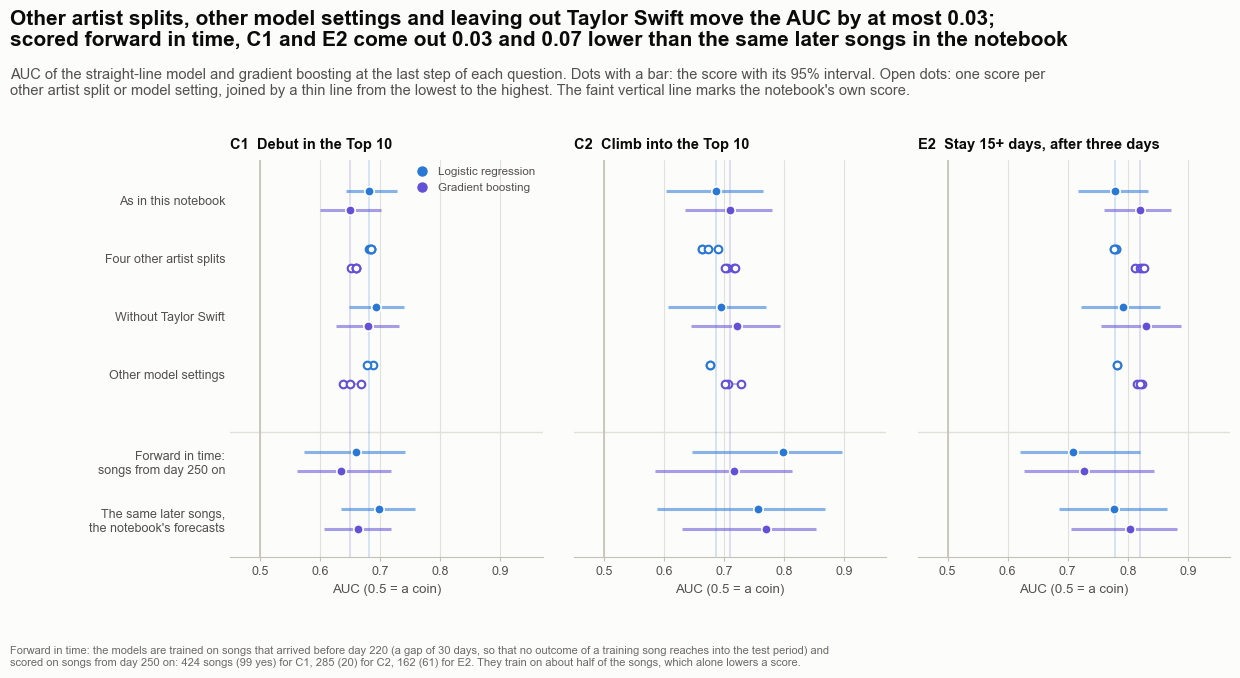

In [34]:
# Figure 17 - stress tests: the same question, asked in harder or different ways
NUMBER_WORD = {1: "One", 2: "Two", 3: "Three", 4: "Four", 5: "Five", 6: "Six"}
STRESS_ROWS = [("own", "As in this notebook"), ("seeds", f"{NUMBER_WORD[len(OTHER_SEEDS)]} other artist splits"), ("without", f"Without {BIGGEST_ARTIST}"), ("variants", "Other model settings"),
               ("forward", f"Forward in time:\nsongs from day {FORWARD_CUTOFF} on"), ("same_later", "The same later songs,\nthe notebook's forecasts")]
ROW_Y = dict(zip([name for name, _ in STRESS_ROWS], [0, 1, 2, 3, 4.5, 5.5]))
DODGE = {"logistic": -0.17, "boosting": 0.17}
STRESS_PANELS = {"debut_top10": "C1  Debut in the Top 10", "climb_top10": "C2  Climb into the Top 10", "sustained_after3": "E2  Stay 15+ days, after three days"}

fig, axes = make_fig(13.0, 6.9, 1, 3, left=2.55, right=0.45, bottom=0.95, wspace=0.1, panel_titles=True, sharey=True,
                     title=f"Other artist splits, other model settings and leaving out {BIGGEST_ARTIST} move the AUC by at most {FACTS['stress_max_shift']:.2f}; "
                           f"scored forward in time, C1 and E2 come out {FACTS['stress_c1_forward_drop']:.2f} and {FACTS['stress_e2_forward_drop']:.2f} lower than the same later songs in the notebook",
                     subtitle="AUC of the straight-line model and gradient boosting at the last step of each question. Dots with a bar: the score with its 95% interval. Open dots: one score per other artist split or model setting, "
                              "joined by a thin line from the lowest to the highest. The faint vertical line marks the notebook's own score.",
                     note_text=f"Forward in time: the models are trained on songs that arrived before day {FORWARD_CUTOFF - FORWARD_GAP} (a gap of {FORWARD_GAP} days, so that no outcome of a training song reaches into the test period) "
                               f"and scored on songs from day {FORWARD_CUTOFF} on: {FACTS['stress_c1_later_songs']} songs ({FACTS['stress_c1_later_yes']} yes) for C1, {FACTS['stress_c2_later_songs']} ({FACTS['stress_c2_later_yes']}) for C2, "
                               f"{FACTS['stress_e2_later_songs']} ({FACTS['stress_e2_later_yes']}) for E2. They train on about half of the songs, which alone lowers a score.")
for ax, (key, step) in zip(axes, STRESS):
    for model in STRESS_MODELS:
        r, color, dy = STRESS_RESULTS[(key, model)], MP.MODEL_COLORS[model], DODGE[model]
        ax.axvline(r["own"][0], color=color, alpha=0.22, linewidth=1.2, zorder=1)
        for name, _ in STRESS_ROWS:
            y = ROW_Y[name] + dy
            if name in ("own", "without", "forward", "same_later"):
                score, low, high = r[name]
                ax.hlines(y, low, high, color=color, linewidth=2.2, alpha=0.55, zorder=2)
                ax.scatter([score], [y], s=46, color=color, edgecolor=style.SURFACE, linewidth=1.2, zorder=3)
            else:
                values = np.array(r[name] if name == "seeds" else list(r["variants"].values()))
                ax.hlines(y, values.min(), values.max(), color=color, linewidth=1.2, alpha=0.5, zorder=2)
                ax.scatter(values, np.full(len(values), y), s=30, facecolor=style.SURFACE, edgecolor=color, linewidth=1.5, zorder=3)
    ax.axvline(0.5, color=style.AXIS, linewidth=1.2, zorder=1)
    ax.set_xlim(0.45, 0.97)
    ax.set_xlabel("AUC (0.5 = a coin)")
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
    panel_title(ax, STRESS_PANELS[key])
    ax.axhline(4.0, color=style.GRID, linewidth=1.0, zorder=0)
axes[0].set_yticks([ROW_Y[name] for name, _ in STRESS_ROWS])
axes[0].set_yticklabels([label for _, label in STRESS_ROWS], fontsize=9)
axes[0].set_ylim(6.15, -0.7)
MP.ladder_legend(axes[0], STRESS_MODELS, MODEL_LABELS, None, loc="upper right", fontsize=8.4)
save_fig(fig, "p6a_17_stress", FIG_DIR)
plt.show()

**What to notice**

- Four other ways of dealing the artists into five parts move the AUC by at most 0.023, and the other model settings by at most 0.017. The scores of the notebook are not an accident of one split or one choice of settings.
- Leaving out Taylor Swift (92 songs, the artist with the most) raised the AUC in 6 of the six cases, by 0.008 to 0.031. The scores do not depend on that artist; they are a little higher without.
- Forward in time, C1 scores 0.66 with the straight-line model and 0.64 with boosting, against 0.70 and 0.66 for the same later songs in the notebook: lower by 0.032 on average. For E2 the average drop is 0.072 (0.71 and 0.73 against 0.78 and 0.80). In every row the bar of the forward score overlaps the bar of the notebook's score for the same songs, so a drop of this size is a hint and not a measured drop.
- For C2 the forward test is mixed: the straight-line model does better in time (0.80 against 0.76) and boosting worse (0.71 against 0.77). The later songs hold only 20 climbers, and the bars are wide, so nothing can be read from the difference.
- The forward test trains on about half of the songs (418 for C1, 301 for C2, 164 for E2), which lowers a score by itself. The drop can not be put down to the passing of time alone, and the test can not tell how much of it is time and how much is less data.
- All of this is one chart in one period. It shows that the scores are steady within this chart. It does not show that the same scores would hold in another year or on another list.

## Section 10 - Saving the results and what Phase 6A adds up to

The last code cell writes the files that the later phases read, so that the dashboard, the Power BI report and the paper do not have to run the models again. After it comes the summary of the phase.

**What this code is.** The save cell. It puts the results into five tables and one facts file and writes them to `reports/`. (1) `p6a_model_register.csv`: every score of every model at every step of every question, with its 95% interval, one row per question, step and model. (2) `p6a_oof_predictions.csv`: for every question, the forecast of every song at the last step by the baseline, the straight-line model, boosting and the forest, each made by models that had never seen the song's artist, next to what really happened (for the stay class, the probability of each class and the most likely class). (3) `p6a_explanations.csv`: the odds ratios, the coefficients and the permutation importances of Section 7 in one long table. (4) `p6a_decisions.csv`: the break-even grids of Section 8. (5) `p6a_stress_tests.csv`: the stress tests of Section 9. The sixth file, `p6a_facts.json`, holds every number that the sentences of the notebook quote.

**Why we need it.** Later phases should read results, not recompute them: the Streamlit dashboard of Phase 7, the Power BI report of Phase 8 and the paper of Phase 9 all need the same scores, forecasts and verdicts, and running the models takes minutes. The checks inside the cell make the files trustworthy: there must be one row per question, step and model, and one forecast per song, model and question.

**What will happen.** The code assembles the tables, stops with an error if a duplicate row appears, saves each table with `save_table`, saves the facts, and counts the charts in `reports/figures/`. It stops if there are not exactly 17.

**Expected outcome.** A list of the five files with their number of rows (94 rows in the register), the number of stored facts, and "charts 17 files in reports/figures".

**Motive.** Leave the work in files that later phases can read, and a notebook that checks itself.

In [35]:
# Section 10 - save the files that the later phases read, and count the charts
# (1) every score of every model, with its 95% interval (a blank means that the score does not exist for that kind of question)
register_rows = []
for key, bench in BENCH.items():
    for _, row in bench.table.iterrows():
        entry = {"question": bench.task.code, "title": bench.task.title, "kind": bench.task.kind, "step": row["step"], "model": row["model"], "songs": int(row["n"])}
        for metric in METRICS[bench.task.kind]:
            entry[metric], entry[f"{metric}_low"], entry[f"{metric}_high"] = float(row[metric]), float(row[f"{metric}_low"]), float(row[f"{metric}_high"])
        register_rows.append(entry)
MODEL_REGISTER = pd.DataFrame(register_rows)

# (2) the forecast for every song at the last step of every question, made by models that had never seen the song's artist
CLASS_COLUMNS = ["p_flash", "p_short", "p_sustained"]
forecast_parts = []
for key, bench in BENCH.items():
    last = bench.task.steps[-1]
    identity = bench.frame[["track_id", "track_label", "primary_artist", "entry_date"]].reset_index(drop=True)
    for model in ["baseline", LINEAR_NAME[bench.task.kind], "boosting", "forest"]:
        if (last, model) not in bench.predictions:
            continue
        pred = bench.predictions[(last, model)]
        part = identity.copy()
        part.insert(0, "model", model)
        part.insert(0, "step", last)
        part.insert(0, "question", bench.task.code)
        if bench.task.kind == "multiclass":
            classes = CLASS_LISTS[key]
            part["actual"] = [classes[i] for i in bench.y]
            part["forecast"] = np.nan
            part["forecast_class"] = [classes[i] for i in pred.argmax(axis=1)]
            for column, probability in zip(CLASS_COLUMNS, pred.T):
                part[column] = probability
        else:
            part["actual"] = bench.y
            part["forecast"] = pred
            part["forecast_class"] = None
            for column in CLASS_COLUMNS:
                part[column] = np.nan
        forecast_parts.append(part)
FORECASTS = pd.concat(forecast_parts, ignore_index=True)

# (3) the explanations of Section 7 in one long table
explain_rows = []
for key, table in ODDS.items():
    explain_rows += [{"kind": "odds ratio per standard deviation", "question": TASKS[key].code, "model": "logistic regression", "input": r.input, "estimate": r.odds_ratio,
                      "low": r.low, "high": r.high, "p_value": r.p_value, "spread": np.nan} for r in table.itertuples()]
explain_rows += [{"kind": "change in chart days per standard deviation", "question": "R2", "model": f"regression: {r.model.lower()}", "input": r.input, "estimate": r.days,
                  "low": r.low, "high": r.high, "p_value": r.p_value, "spread": np.nan} for r in OLS.itertuples()]
explain_rows += [{"kind": f"fall in {r.score} when the block is scrambled", "question": r.question, "model": "gradient boosting", "input": r.block, "estimate": r.importance,
                  "low": np.nan, "high": np.nan, "p_value": np.nan, "spread": r.sd} for r in IMPORTANCE.itertuples()]
EXPLANATIONS = pd.DataFrame(explain_rows)

# (4) the break-even grids of Section 8
DECISION_TABLE = pd.concat([table.assign(question=TASKS[key].code, model=MODEL_LABELS[DECISION_MODEL[key]]) for key, table in DECISIONS.items()], ignore_index=True)
DECISION_TABLE = DECISION_TABLE[["question", "model", "share_promoted", "value_ratio", "promoted", "hits", "precision", "net", "roi", "break_even"]]

# (5) the stress tests of Section 9
stress_rows = []
for (key, model), r in STRESS_RESULTS.items():
    who = {"question": TASKS[key].code, "model": MODEL_LABELS[model]}
    stress_rows.append({**who, "check": "as in the notebook", "score": r["own"][0], "low": r["own"][1], "high": r["own"][2]})
    stress_rows += [{**who, "check": f"other artist split {seed}", "score": value, "low": np.nan, "high": np.nan} for seed, value in zip(OTHER_SEEDS, r["seeds"])]
    stress_rows.append({**who, "check": f"without {BIGGEST_ARTIST}", "score": r["without"][0], "low": r["without"][1], "high": r["without"][2]})
    stress_rows += [{**who, "check": f"setting: {label}", "score": value, "low": np.nan, "high": np.nan} for label, value in r["variants"].items()]
    stress_rows.append({**who, "check": f"forward in time (songs from day {FORWARD_CUTOFF} on)", "score": r["forward"][0], "low": r["forward"][1], "high": r["forward"][2]})
    stress_rows.append({**who, "check": "the same later songs, notebook forecasts", "score": r["same_later"][0], "low": r["same_later"][1], "high": r["same_later"][2]})
STRESS_TABLE = pd.DataFrame(stress_rows)

files = {"p6a_model_register.csv": MODEL_REGISTER, "p6a_oof_predictions.csv": FORECASTS, "p6a_explanations.csv": EXPLANATIONS,
         "p6a_decisions.csv": DECISION_TABLE, "p6a_stress_tests.csv": STRESS_TABLE}
assert MODEL_REGISTER.duplicated(["question", "step", "model"]).sum() == 0, "one row per question, step and model"
assert FORECASTS.duplicated(["question", "model", "track_id"]).sum() == 0, "one forecast per song, model and question"
for name, table in files.items():
    save_table(table, paths.reports_dir / name)
FACTS.save(paths.reports_dir / "p6a_facts.json")

charts = sorted(FIG_DIR.glob("p6a_*.png"))
for name, table in files.items():
    print(f"{name:<26}{len(table):>7,} rows")
print(f"{'p6a_facts.json':<26}{len(FACTS):>7,} stored numbers and names")
print(f"charts                    {len(charts):>7} files in {FIG_DIR.parent.name}/{FIG_DIR.name}/")
assert len(charts) == 17, "expected 17 charts (Figures 1 to 17); run the notebook from the first cell"

p6a_model_register.csv         94 rows
p6a_oof_predictions.csv    19,144 rows
p6a_explanations.csv           74 rows
p6a_decisions.csv             112 rows
p6a_stress_tests.csv           63 rows
p6a_facts.json              1,559 stored numbers and names
charts                         17 files in reports/figures/


## What Phase 6A adds up to

**The result in one paragraph.** What is known early says something about what happens to a new song, but not much, and how much depends on the moment the question is asked. Before a song arrives, a Top-10 debut can be ranked with an AUC of 0.68 (interval 0.64 to 0.73); the artist's record is the step that adds. On the debut day, a later climb into the Top 10 can be ranked with an AUC of up to 0.71 (0.63 to 0.78 for the best model), the stay class with a balanced accuracy of 0.51 against a chance level of 0.33, and the number of chart days with an R-squared of 0.22. First-week popularity can not be forecast at all (best R-squared 0.02, with an interval that includes zero). After three days on the chart the AUC is 0.87 for a later climb, which rests on 31 climbers, and 0.84 for a stay of 15 or more days.

**Where the information comes from.**

- *Before the song arrives (C1): the artist's record.* The straight-line AUC goes from 0.61 with release details to 0.68 with the artist's record, and timing adds nothing the data can show. Shuffling the artist's record costs the boosting model 0.127 of AUC, against 0.007 for release details and 0.005 for timing.
- *On the debut day (C2, C3, R2): the debut-day chart.* Boosting goes from an AUC of 0.50 with release details to 0.71 for C2, from a balanced accuracy of 0.37 (before the debut-day chart) to 0.50 for C3, and from an R-squared of 0.01 to 0.22 for R2. The importance figures agree for C3 and R2 (shuffling the debut-day chart costs 0.131 of balanced accuracy and 0.330 of R-squared). For the climb, C2, the artist's record and the debut-day chart count about equally (0.080 and 0.081).
- *After three days (E1, E2): the first three days.* They are the largest block in both questions (shuffling them costs 0.124 of AUC for E1 and 0.181 for E2). These two questions start higher than the others, because their songs are a different group: release details alone give an AUC of 0.71 for E1 and 0.69 for E2.
- *The regressions say it from the other side.* Among songs that are alike in the other inputs, a debut place one standard deviation further down the chart goes with 0.59 times the odds of a climb and with a change of -3.05 chart days, and a release with one standard deviation more tracks with a change of -2.54 chart days. Explicit songs have 2.04 times the odds of a Top-10 debut and collaborations 0.43 times.

**Simple against complicated.** For the three Top-10 questions (C1, C2 and E1) no flexible model is clearly better than the straight-line model: every interval of a difference includes zero. E1 is the close one: boosting scores +0.073 higher (-0.013 to +0.158), and with 31 climbers the interval only just reaches zero. For C3, R2 and E2 the flexible models are clearly better: the random forest minus the straight line is +0.070 in balanced accuracy for C3 and +0.062 in AUC for E2, and boosting minus ridge regression is +0.125 in R-squared for R2. For chart days and for E2 the curves of Figure 14 bend in ways that a straight line can not follow, which fits this.

**What the checks show.** The test is built not to flatter the models, and the checks found no sign that the machinery invents skill. Random folds would have raised the AUC by 0.024 on average over the 9 cases checked, and by up to 0.061. With the outcomes shuffled, the 27 scores averaged 0.48 (from 0.39 to 0.68). Scrambling the future of the chart for 6 songs changed none of their inputs. Other artist splits, other model settings and leaving out Taylor Swift moved the AUC by at most 0.031. Scored forward in time, C1 and E2 came out 0.032 and 0.072 lower than the same later songs in the notebook, with bars that overlap, so that is a hint of a drop and not a measured one.

**What a price on the forecasts shows.** Backing the best 10% of songs would have paid back if a climb were worth more than 3.9 promotions on the debut day and more than 2.2 after three days, against 11 and 12 for random picks. The value of a climb is Atlantic's to supply, and this is a measurement of what such a rule would have done on past songs.

**What this does not show.**

- *Nothing here is causal.* Odds ratios, coefficients, importances and curves describe associations among these songs, or what a model does. They say nothing about what would happen to a song that were changed.
- *The forecasts are measuring tools, not advice.* The brief is historical analytics. No model here is a way to choose songs.
- *The models used in the detail charts, the gains and the break-even were chosen on the songs they are scored on,* by the higher AUC, so those numbers are slightly flattering.
- *Few positives.* C2 has 56 climbers and E1 31. The intervals are wide, and a handful of songs moves the break-even.
- *The forward test uses about half of the songs for training,* so it can not tell how much of its lower score is time and how much is less data.
- *One chart, one period.* The scores are steady within this chart. Nothing says that they would hold in another year or on another list.

**What Phase 6B takes from here.** Phase 6B turns from forecasting to describing: which songs and artists look alike (clustering) and how long a chart run lasts when runs that are still going are counted properly (survival analysis). Three things carry over from this notebook.

1. *Judge by artist.* The songs of one artist are alike, so any grouping or survival model that is to be judged on how well it holds up must be judged on artists it has not seen, as here.
2. *Say what was known when.* The ladder of information (release, timing, the artist's record, the debut-day chart, the first three days) is a way of saying at which moment each statement could have been made. The same discipline applies to a cluster or to a survival curve.
3. *Count unfinished runs.* Songs that arrived too late in the file to be followed for 30 days were left out of C2, C3, R2, E1 and E2. Survival analysis is the proper tool for them, because it counts a run that is still going as one that has lasted at least this long.

The files that Phase 6B and the later phases read from this one are `reports/p6a_model_register.csv` (every score with its interval), `reports/p6a_oof_predictions.csv` (the forecast for every song), `reports/p6a_explanations.csv`, `reports/p6a_decisions.csv`, `reports/p6a_stress_tests.csv` and `reports/p6a_facts.json`.